# Pharmaceutical Operations Intelligence System

## Integrated SQL, data cleaning, exploratory data analysis and predictive models

This notebook uses four LAL datasets: **batch production** and **equipment maintenance** (joined with SQL), and **sales transactions** and **inventory movements** (joined with pandas). It cleans each source, explores them with tables and charts, and builds simple models for the proposal's three modules:
- **inventory and demand** (weekly demand forecast, stock-out risk, reorder points);
- **quality and compliance** (batch failure, yield, quality trends, abnormal conditions, failure causes);
- **preventive maintenance** (maintenance status, equipment priority).

In [502]:
# Import standard-library tools used for file paths, SQL, warnings, and utilities.
import os, sys, sqlite3, warnings, json, math                               # system, SQL, warning and maths utilities
from pathlib import Path                                                    # file-path handling

# Import data handling and plotting libraries.
import numpy as np                                                          # numerical arrays
import pandas as pd                                                         # data tables (DataFrames)
import matplotlib.pyplot as plt                                             # plotting
import seaborn as sns                                                       # statistical charts

# Import tools for splitting data, preprocessing features, and building pipelines.
from sklearn.model_selection import train_test_split                        # split data into training and test sets
from sklearn.compose import ColumnTransformer                               # apply different preprocessing to different columns
from sklearn.pipeline import Pipeline                                       # chain preprocessing steps
from sklearn.preprocessing import OneHotEncoder, StandardScaler             # encode categories; standardise numbers
from sklearn.impute import SimpleImputer                                    # fill missing values

# Import evaluation metrics for classification and regression models.
from sklearn.metrics import (classification_report, confusion_matrix, precision_score,  # model evaluation metrics
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             mean_absolute_error, mean_squared_error, r2_score)

# Import candidate machine-learning models and dimensionality-reduction tools.
from sklearn.linear_model import LogisticRegression, Ridge                  # linear models
from sklearn.tree import DecisionTreeClassifier                             # decision tree model
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, IsolationForest  # tree-ensemble models
from sklearn.neural_network import MLPClassifier                            # simple neural-network classifier
from sklearn.decomposition import PCA                                       # principal component analysis



# Set a fixed random seed so random operations are reproducible.
RANDOM_STATE = 42                                                           # fixed seed used throughout
np.random.seed(RANDOM_STATE)                                                # make NumPy random results repeatable

# Set a default size for plots.
plt.rcParams['figure.figsize'] = (10, 5)                                    # default chart size


## 2. Load source files and inspect structure

In [504]:
# Read the four source files into DataFrames (IDs read as text so codes like "SUP_001" stay intact).
production = pd.read_csv('LAL_Batch_Manufacturing_Production.csv')          # batch production records
maintenance = pd.read_csv('LAL_Equipment_Maintenance_Records.csv')          # equipment maintenance records
sales = pd.read_csv('sales_records.csv', dtype={'Supplier_ID': str})        # sales transactions
inventory = pd.read_csv('inventory_records.csv', dtype={'Supplier_ID': str})  # stock movements: receipts and sale-outs

# Show the size and the field names of each dataset.
for name, df in [('Production', production), ('Maintenance', maintenance), ('Sales', sales), ('Inventory', inventory)]:
    print(f'{name} shape: {df.shape}')                                    # rows and columns
    print(f'{name} columns: {df.columns.tolist()}', end='\n\n')          # field names

# Preview the first five rows of each dataset.
display(production.head())                                                  # first five production rows
display(maintenance.head())                                                 # first five maintenance rows
display(sales.head())                                                       # first five sales rows
display(inventory.head())                                                   # first five inventory movements

Production shape: (60000, 30)
Production columns: ['batch_id', 'drug_name', 'dosage_form', 'manufacturing_section', 'production_start', 'batch_size', 'batch_size_unit', 'equipment_id', 'equipment_name', 'equipment_age_days', 'maintenance_days_ago', 'upstream_equipment_id', 'downstream_equipment_id', 'ahu_id', 'operator_id', 'operator_experience_years', 'temp_avg', 'temp_variance', 'pressure_avg', 'pressure_variance', 'humidity_avg', 'production_hours', 'raw_material_quality', 'target_yield', 'actual_yield', 'assay_result_purity', 'impurity_level', 'dissolution_time_min', 'batch_passed', 'rejection_reason']

Maintenance shape: (60000, 16)
Maintenance columns: ['batch_id', 'equipment_id', 'equipment_name', 'manufacturing_section', 'production_date', 'equipment_age_days', 'maintenance_days_ago', 'maintenance_status', 'upstream_equipment_id', 'downstream_equipment_id', 'operator_experience_years', 'batch_size', 'batch_size_unit', 'production_hours', 'batch_passed', 'rejection_reason']

Sal

,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,humidity_avg,production_hours,raw_material_quality,target_yield,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,44.0,26.7,99.6,95.0,99.79,100.69,0.098,17.26,1,NaN
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,47.1,21.4,99.8,95.0,99.21,99.55,0.104,16.67,1,NaN
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,48.7,19.6,99.6,95.0,98.62,100.18,0.066,15.06,1,NaN
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,40.7,7.2,99.0,98.0,98.86,102.38,0.161,NaN,1,NaN
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,57.9,6.7,99.8,98.0,98.80,99.51,0.282,NaN,1,NaN


,batch_id,equipment_id,equipment_name,manufacturing_section,production_date,equipment_age_days,maintenance_days_ago,maintenance_status,upstream_equipment_id,downstream_equipment_id,operator_experience_years,batch_size,batch_size_unit,production_hours,batch_passed,rejection_reason
0,TOT-07-0001,LAL/TAB/006,35 STN Compression Machine,Oral Solids,02/01/2007,1695,78,Current,LAL/TAB/012,LAL/TAB/008,3,250,kg,26.7,1,NaN
1,ACM-07-0001,LAL/TAB/006,35 STN Compression Machine,Oral Solids,03/01/2007,1696,79,Current,LAL/TAB/012,LAL/TAB/008,8,250,kg,21.4,1,NaN
2,ACM-07-0002,LAL/TAB/006,35 STN Compression Machine,Oral Solids,03/01/2007,1696,79,Current,LAL/TAB/012,LAL/TAB/008,2,200,kg,19.6,1,NaN
3,ALS-07-0001,LAL/LIQ/003,Liquids Mfg Tank (500 L),Oral Liquids,03/01/2007,1633,79,Current,LAL/LIQ/014,LAL/LIQ/008,10,500,L,7.2,1,NaN
4,ALS-07-0002,LAL/LIQ/003,Liquids Mfg Tank (500 L),Oral Liquids,03/01/2007,1633,79,Current,LAL/LIQ/014,LAL/LIQ/008,4,300,L,6.7,1,NaN


,Sale_ID,Invoice_No,Sale_Date,Branch_Code,Customer_ID,Product_ID,Product_Category,Quantity,Unit_Price_KES,Gross_Amount_KES,...,VAT_Rate_Pct,VAT_Amount_KES,Total_Amount_KES,Payment_Method,Payment_Status,Amount_Paid_KES,Balance_Due_KES,Order_Status,Sales_Rep_ID,Supplier_ID
0,TXN_SALES_00000001,INV-2014-000001,2014-01-01,BR01,CUST_ORG_002670,LAB_PROD_00230,Equipment,1,58450,58450,...,16,8884.4,64411.90,M-Pesa,Paid,64411.90,0.0,Delivered,REP_001,SUP_010
1,TXN_SALES_00000002,INV-2014-000002,2014-01-01,BR01,CUST_ORG_000401,LAB_PROD_00126,Reagents,15,225,3375,...,16,513.0,3719.25,Cheque,Paid,3719.25,0.0,Delivered,REP_010,SUP_003
2,TXN_SALES_00000003,INV-2014-000003,2014-01-01,BR04,CUST_ORG_001896,LAB_PROD_00087,Glassware,12,250,3000,...,16,432.0,3132.00,Cheque,Paid,3132.00,0.0,Delivered,REP_001,SUP_029
3,TXN_SALES_00000004,INV-2014-000004,2014-01-01,BR01,CUST_ORG_002223,LAB_PROD_00086,Glassware,2,275,550,...,16,88.0,638.00,Cash,Paid,638.00,0.0,Delivered,REP_006,SUP_026
4,TXN_SALES_00000005,INV-2014-000005,2014-01-01,BR01,CUST_ORG_001047,LAB_PROD_00278,Clinical_Supplies,10,825,8250,...,16,1320.0,9570.00,M-Pesa,Paid,9570.00,0.0,Delivered,REP_001,SUP_019


,Movement_ID,Movement_Date,Branch_Code,Product_ID,Movement_Type,Reference_ID,Quantity_Change,Unit_Cost_KES,Supplier_ID,Movement_Value_KES
0,MOV_00000001,2014-01-01,BR01,LAB_PROD_00230,Sale_Out,TXN_SALES_00000001,-1,42100.0,NaN,-42100.0
1,MOV_00000002,2014-01-01,BR01,LAB_PROD_00126,Sale_Out,TXN_SALES_00000002,-15,165.0,NaN,-2475.0
2,MOV_00000003,2014-01-01,BR04,LAB_PROD_00087,Sale_Out,TXN_SALES_00000003,-12,180.0,NaN,-2160.0
3,MOV_00000004,2014-01-01,BR01,LAB_PROD_00086,Sale_Out,TXN_SALES_00000004,-2,200.0,NaN,-400.0
4,MOV_00000005,2014-01-01,BR01,LAB_PROD_00278,Sale_Out,TXN_SALES_00000005,-10,600.0,NaN,-6000.0


### Explanation

| Dataset | Rows | Columns | One row is |
|---|---|---|---|
| Production | 60,000 | 30 | one manufactured batch: product, equipment, process conditions, lab results, pass/fail |
| Maintenance | 60,000 | 16 | the maintenance state of the equipment used for a batch |
| Sales | 150,000 | 23 | one sales transaction: date, branch, customer, product, quantity, price, discount, VAT, payment, order status, supplier |
| Inventory | 162,000 | 10 | one stock movement: 150,000 sale-outs (each linked to a sale) and 12,000 goods received from suppliers |

**How the files connect:**
- Production and maintenance share `batch_id`.
- Sales and inventory share the sale ID: each sale-out movement's `Reference_ID` equals a `Sale_ID`.
- The two pairs have no common key. Production uses LAL batch and equipment IDs, while sales use `LAB_PROD_` product IDs for six laboratory-supply categories. They are therefore compared by **calendar month** in Section 5.7.

**Gaps:** the sales and inventory data have no expiry dates, no opening stock balance and no supplier lead times. These affect what can be modelled and are noted where relevant.

## 3. Integrate the datasets
### 3.1 Join production and maintenance (SQL)
Each batch is joined to its maintenance record on `batch_id`.

In [507]:
# Join production and maintenance data using an in-memory SQLite database.
conn = sqlite3.connect(":memory:")                                          # temporary in-memory SQL database

# Copy both DataFrames into temporary SQL tables.
production.to_sql("production", conn, index=False, if_exists="replace")     # copy production data into an SQL table
maintenance.to_sql("maintenance", conn, index=False, if_exists="replace")   # copy maintenance data into an SQL table

# Keep every production row and attach matching maintenance fields by batch_id.
# A LEFT JOIN preserves production records even when no maintenance match exists.
combined_data = pd.read_sql_query("""
    SELECT p.*,
           m.maintenance_status,
           m.production_date AS maintenance_production_date
    FROM production p
    LEFT JOIN maintenance m
    ON p.batch_id = m.batch_id
""", conn)

# Preview the integrated dataset and check its dimensions.
display(combined_data.head())                                               # preview the first five rows
print("Joined data shape:", combined_data.shape)                            # rows and columns after the join

# Close the temporary database connection after the query has completed.
conn.close()                                                                # close the SQL connection


,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,raw_material_quality,target_yield,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason,maintenance_status,maintenance_production_date
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,99.6,95.0,99.79,100.69,0.098,17.26,1,None,Current,02/01/2007
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.8,95.0,99.21,99.55,0.104,16.67,1,None,Current,03/01/2007
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.6,95.0,98.62,100.18,0.066,15.06,1,None,Current,03/01/2007
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,99.0,98.0,98.86,102.38,0.161,NaN,1,None,Current,03/01/2007
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,99.8,98.0,98.80,99.51,0.282,NaN,1,None,Current,03/01/2007


Joined data shape: (60000, 32)


### Explanation

`Joined data shape: (60000, 32)` means the integrated dataset contains **60,000 rows and 32 columns**. The preview shows the first five joined records, with production details and maintenance-related fields side by side.

The output demonstrates that the join returned 60,000 rows, but the shape alone does not prove that every match is correct. The later duplicate-batch check reports zero duplicate `batch_id` values, which is a useful additional check. Confirm that the SQL join keys and the meaning of the date fields match the source data before drawing operational conclusions.

In [509]:
# Report the number of rows and columns in the integrated dataset.
print("Data shape:", combined_data.shape)                                   # rows and columns of the joined data

# List all fields available after the SQL join.
print(combined_data.columns.tolist())                                       # list all columns

# Show column types, non-missing counts, and memory use.
combined_data.info()                                                        # column types and non-missing counts

# Summarize numeric columns with descriptive statistics.
combined_data.describe()                                                    # summary statistics of numeric columns

# Count rows that are exact duplicates across all columns.
print("Duplicate rows:", combined_data.duplicated().sum())                  # count fully duplicated rows

# Preview the first five integrated records.
display(combined_data.head())                                               # preview the first five rows


Data shape: (60000, 32)
['batch_id', 'drug_name', 'dosage_form', 'manufacturing_section', 'production_start', 'batch_size', 'batch_size_unit', 'equipment_id', 'equipment_name', 'equipment_age_days', 'maintenance_days_ago', 'upstream_equipment_id', 'downstream_equipment_id', 'ahu_id', 'operator_id', 'operator_experience_years', 'temp_avg', 'temp_variance', 'pressure_avg', 'pressure_variance', 'humidity_avg', 'production_hours', 'raw_material_quality', 'target_yield', 'actual_yield', 'assay_result_purity', 'impurity_level', 'dissolution_time_min', 'batch_passed', 'rejection_reason', 'maintenance_status', 'maintenance_production_date']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   batch_id                     60000 non-null  object 
 1   drug_name                    60000 non-null  object 
 2   dosage_form  

,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,raw_material_quality,target_yield,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason,maintenance_status,maintenance_production_date
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,99.6,95.0,99.79,100.69,0.098,17.26,1,None,Current,02/01/2007
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.8,95.0,99.21,99.55,0.104,16.67,1,None,Current,03/01/2007
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.6,95.0,98.62,100.18,0.066,15.06,1,None,Current,03/01/2007
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,99.0,98.0,98.86,102.38,0.161,NaN,1,None,Current,03/01/2007
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,99.8,98.0,98.80,99.51,0.282,NaN,1,None,Current,03/01/2007


### Explanation

- **`Data shape: (60000, 32)`** means 60,000 records and 32 fields after integration.
- **The column list** identifies the variables available for analysis.
- **`combined_data.info()`** shows each field's data type and non-null count. At this stage, `production_start` and `maintenance_production_date` are shown as `object`, meaning they are stored as text rather than as true datetime values.
- **The descriptive statistics** summarize numeric columns, such as their count, mean, spread, and minimum/maximum.
- **`Duplicate rows: 0`** means no rows are exact duplicates across all columns at this stage.
- **The preview** shows a sample of five records, not the whole dataset.

A field can have missing values even when the dataset has no duplicate rows. The next cleaning checks address missing values and date formats.

### 3.2 Join sales and inventory (Python)
Each sale is matched to its own stock movement (`Reference_ID = Sale_ID`) with a pandas `merge`. This adds the **unit cost** of the item sold, which is needed for margins and stock value.

In [512]:
# Join each sale to its sale-out stock movement with pandas to add the unit cost (how="left" keeps every sale).
sale_moves = inventory.loc[inventory["Movement_Type"] == "Sale_Out", ["Reference_ID", "Movement_ID", "Unit_Cost_KES", "Quantity_Change"]]  # sale-out rows only
sales_data = sales.merge(sale_moves, left_on="Sale_ID", right_on="Reference_ID", how="left")  # one row per sale
sales_data["Quantity_Moved"] = -sales_data["Quantity_Change"]               # units taken from stock (sale-outs are negative)
sales_data = sales_data.drop(columns=["Reference_ID", "Quantity_Change"])  # drop the helper columns

print("Sales rows before / after the join:", len(sales), "/", len(sales_data))  # no sale lost or duplicated
print("Sales without a stock movement:", sales_data["Movement_ID"].isna().sum())  # orphan sales
print("Sale-out movements without a sale:", (~sale_moves["Reference_ID"].isin(sales["Sale_ID"])).sum())  # orphan movements
display(sales_data.head())                                                  # preview the joined table

Sales rows before / after the join: 150000 / 150000
Sales without a stock movement: 0
Sale-out movements without a sale: 0


,Sale_ID,Invoice_No,Sale_Date,Branch_Code,Customer_ID,Product_ID,Product_Category,Quantity,Unit_Price_KES,Gross_Amount_KES,...,Payment_Method,Payment_Status,Amount_Paid_KES,Balance_Due_KES,Order_Status,Sales_Rep_ID,Supplier_ID,Movement_ID,Unit_Cost_KES,Quantity_Moved
0,TXN_SALES_00000001,INV-2014-000001,2014-01-01,BR01,CUST_ORG_002670,LAB_PROD_00230,Equipment,1,58450,58450,...,M-Pesa,Paid,64411.90,0.0,Delivered,REP_001,SUP_010,MOV_00000001,42100.0,1
1,TXN_SALES_00000002,INV-2014-000002,2014-01-01,BR01,CUST_ORG_000401,LAB_PROD_00126,Reagents,15,225,3375,...,Cheque,Paid,3719.25,0.0,Delivered,REP_010,SUP_003,MOV_00000002,165.0,15
2,TXN_SALES_00000003,INV-2014-000003,2014-01-01,BR04,CUST_ORG_001896,LAB_PROD_00087,Glassware,12,250,3000,...,Cheque,Paid,3132.00,0.0,Delivered,REP_001,SUP_029,MOV_00000003,180.0,12
3,TXN_SALES_00000004,INV-2014-000004,2014-01-01,BR01,CUST_ORG_002223,LAB_PROD_00086,Glassware,2,275,550,...,Cash,Paid,638.00,0.0,Delivered,REP_006,SUP_026,MOV_00000004,200.0,2
4,TXN_SALES_00000005,INV-2014-000005,2014-01-01,BR01,CUST_ORG_001047,LAB_PROD_00278,Clinical_Supplies,10,825,8250,...,M-Pesa,Paid,9570.00,0.0,Delivered,REP_001,SUP_019,MOV_00000005,600.0,10


### Explanation
- **Row counts:** the join returns **150,000 rows** from 150,000 sales, so no sale was lost or duplicated.
- **Orphans:** **0** sales have no stock movement and **0** sale-out movements have no sale. Every sale can be traced to stock and back.
- **New columns:**
  - `Movement_ID` links each sale to its stock movement.
  - `Unit_Cost_KES` is the cost of the item, used for margins and stock value.
  - `Quantity_Moved` is the number of units taken from stock.
- **Link to production:** the production and maintenance data use batch and equipment IDs, while sales use `LAB_PROD_` product IDs. No key links a batch to a sale, so the two sides are compared month by month in Section 5.7.

## 4. Data cleaning (all four datasets)
### 4.1 Production and maintenance (`combined_data`)

In [515]:
# Preview the original production dates before conversion.
print(combined_data["production_start"].head())                             # preview the raw production dates

# Convert production_start to datetime; invalid values become NaT.
combined_data["production_start"] = pd.to_datetime(                         # convert dates to datetime (invalid -> NaT)
    combined_data["production_start"], errors="coerce"
)

# Find the earliest and latest valid production dates.
print("Earliest date:", combined_data["production_start"].min())            # first production date
print("Latest date:", combined_data["production_start"].max())              # last production date

# Count production dates that are missing or could not be parsed.
print("Missing dates:", combined_data["production_start"].isnull().sum())   # count missing or invalid dates

# Extract calendar year and month for later time-based analysis.
combined_data["year"] = combined_data["production_start"].dt.year           # production year
combined_data["month"] = combined_data["production_start"].dt.month         # production month

# Display the date and its extracted calendar features.
combined_data[["production_start", "year", "month"]].head()                 # preview the date and its year/month


0    2007-01-02
1    2007-01-03
2    2007-01-03
3    2007-01-03
4    2007-01-03
Name: production_start, dtype: object
Earliest date: 2007-01-02 00:00:00
Latest date: 2026-10-09 00:00:00
Missing dates: 0


,production_start,year,month
0,2007-01-02,2007,1
1,2007-01-03,2007,1
2,2007-01-03,2007,1
3,2007-01-03,2007,1
4,2007-01-03,2007,1


### Explanation

The first five `production_start` values are shown before conversion, and they appear to be date strings. After conversion, the earliest valid date is **2 January 2007**, the latest is **9 October 2026**, and the output reports **0 missing production dates**.

The `year` and `month` columns are extracted from the converted date. For example, `2007-01-02` becomes year `2007` and month `1`. These features support grouping production records by calendar period.

Because `errors="coerce"` turns unparseable dates into `NaT`, the missing-date count is a useful check: zero means every production date was parsed successfully in this run.

**Missing-value treatment**

The next cell counts the missing values, removes exact duplicate rows, fills gaps (numeric columns with the column **mean**, text columns with the **most frequent value**), trims spaces from text, and flags outliers with the 1.5 × IQR rule without deleting them.

In [518]:
# Count missing values in each column before applying cleaning steps.
print(combined_data.isnull().sum())                                         # missing values per column

# Remove rows that are exact duplicates across all columns.
combined_data = combined_data.drop_duplicates()                             # remove fully duplicated rows

# Identify numeric columns so missing numeric values can be filled with each column's mean.
numeric_columns = combined_data.select_dtypes(include="number").columns     # numeric columns

# Fill missing numeric entries using the mean of that column.
for col in numeric_columns:                                                 # loop over the numeric columns
    combined_data[col] = combined_data[col].fillna(                         # fill missing values in this column
        combined_data[col].mean()
    )

# Identify text columns for categorical missing-value treatment.
text_columns = combined_data.select_dtypes(include="object").columns        # text columns

# Fill missing text entries with the most frequent category when one exists.
for col in text_columns:                                                    # loop over the text columns
    if combined_data[col].isnull().any():                                   # only if the column has missing values
        combined_data[col] = combined_data[col].fillna(                     # fill missing values in this column
            combined_data[col].mode()[0]
        )

# Standardise text fields without replacing meaningful missing values.
for col in combined_data.select_dtypes(include=['object', 'string']).columns:  # loop over text columns
    combined_data[col] = combined_data[col].astype('string').str.strip()    # remove leading/trailing spaces
    combined_data[col] = combined_data[col].replace({'': pd.NA, 'N/A': pd.NA, 'NA': pd.NA, 'unknown': pd.NA})  # treat blank and 'N/A' text as missing

# The following identifier-standardization example is intentionally commented out.
# id_columns = [
#     "batch_id", "equipment_id", "operator_id",
#     "upstream_equipment_id", "downstream_equipment_id", "ahu_id"
# ]

# for col in id_columns:
#     if col in combined_data.columns:
#         combined_data[col] = combined_data[col].str.upper()

# Select integer columns for a basic IQR-based outlier check.
numeric_columns = combined_data.select_dtypes(include="int").columns        # integer columns for the outlier check

# Calculate the interquartile range and flag values outside the 1.5 × IQR limits.
for col in numeric_columns:                                                 # loop over the numeric columns
    Q1 = combined_data[col].quantile(0.25)                                  # first quartile
    Q3 = combined_data[col].quantile(0.75)                                  # third quartile
    IQR = Q3 - Q1                                                           # interquartile range

    lower_limit = Q1 - 1.5 * IQR                                            # lower outlier limit
    upper_limit = Q3 + 1.5 * IQR                                            # upper outlier limit

    # Select rows with values below or above the calculated limits.
    outliers = combined_data[                                               # rows outside the limits
        (combined_data[col] < lower_limit) |
        (combined_data[col] > upper_limit)
    ]

    # Print the number of flagged records only when outliers are found.
    if len(outliers) > 0:                                                   # only report columns with outliers
        print(col, "- Outliers found:", len(outliers))                      # number of outliers in this column

print("Outlier checking completed.")                                        # confirm the check finished

# Recheck missing values after the cleaning steps.
print("Missing values after cleaning:")                                     # heading
print(combined_data.isnull().sum())                                         # missing values per column


batch_id                           0
drug_name                          0
dosage_form                        0
manufacturing_section              0
production_start                   0
batch_size                         0
batch_size_unit                    0
equipment_id                       0
equipment_name                     0
equipment_age_days                 0
maintenance_days_ago               0
upstream_equipment_id              0
downstream_equipment_id            0
ahu_id                             0
operator_id                        0
operator_experience_years          0
temp_avg                         442
temp_variance                    795
pressure_avg                     587
pressure_variance                715
humidity_avg                     862
production_hours                 289
raw_material_quality             682
target_yield                       0
actual_yield                     230
assay_result_purity                0
impurity_level                   300
d

### Explanation
- **Missing values before cleaning:**
  - `rejection_reason` is empty for **58,125** rows, because only failed batches have a reason; this is expected, not missing data.
  - `dissolution_time_min` is empty for **15,057** rows, mostly liquids and creams, which have no dissolution test.
  - The process readings have small gaps: humidity 862, temperature variance 795, pressure variance 715, raw-material quality 682, pressure 587, temperature 442, impurity 300, production hours 289 and actual yield 230 (each under 1.5% of rows).
- **After cleaning:** every column shows **0** missing values.
  - A filled value is an estimate, not a measurement. For example, liquids now carry the average dissolution time (15.3 minutes).
  - The 58,125 passed batches now carry the most common reason ("Assay out of specification"). Problem 6 uses failed batches only, so its results are not affected.
- **Outliers (flagged, not removed):**
  - **batch_size 7,948:** kilograms and litres are mixed in one column, so these are not real outliers.
  - **operator_experience_years 1,319:** very experienced operators.
  - **maintenance_days_ago 161:** long gaps since service, the Critical equipment.
  - **batch_passed 1,875:** these are simply the failed batches, because the IQR rule treats the rare 0 as unusual.

**Check for duplicate batch IDs**

The SQL join connects production and maintenance records using `batch_id`. This check counts repeated batch IDs and displays a sample of duplicated records. Repeated IDs may be expected if a batch has multiple maintenance records, but they should be reviewed because they can affect batch counts and analysis.

In [521]:
# Count batch IDs that occur more than once after the join.
print("Duplicate batch IDs:", combined_data["batch_id"].duplicated().sum())  # count repeated batch IDs

# Display up to ten rows belonging to duplicated batch IDs.
# keep=False marks every occurrence of a duplicated ID, not just later repeats.
display(                                                                    # show the rows below
    combined_data[
        combined_data["batch_id"].duplicated(keep=False)
    ].head(10)
)


Duplicate batch IDs: 0


,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason,maintenance_status,maintenance_production_date,year,month


### Explanation

`Duplicate batch IDs: 0` means the current joined dataset has no repeated `batch_id` values. The displayed DataFrame is empty because there are no records matching the duplicate-ID condition.

This is a useful check after joining tables: repeated IDs can indicate a many-to-many join or repeated source records. Zero duplicates is reassuring, but it does not independently prove every maintenance record was matched to the correct production batch.

### 4.2 Sales data (`sales_data`)
The same cleaning steps as the production data are applied: dates, missing values, duplicates, text, outliers and duplicate IDs. The sales-specific business rules come last.

In [524]:
# Make the column names lower case so they match the production data (e.g. Sale_Date -> sale_date).
sales_data.columns = sales_data.columns.str.lower()                         # lower-case column names

# Preview the original sale dates before conversion.
print(sales_data["sale_date"].head())                                       # preview the raw sale dates

# Convert sale_date to datetime; invalid values become NaT.
sales_data["sale_date"] = pd.to_datetime(sales_data["sale_date"], errors="coerce")  # text -> date (invalid -> NaT)

# Find the earliest and latest valid sale dates.
print("Earliest date:", sales_data["sale_date"].min())                      # first sale date
print("Latest date:", sales_data["sale_date"].max())                        # last sale date

# Count sale dates that are missing, could not be parsed, or lie in the future.
print("Missing dates:", sales_data["sale_date"].isnull().sum())             # missing or invalid dates
print("Future dates:", (sales_data["sale_date"] > pd.Timestamp.today()).sum())  # dates after today

# Extract calendar year and month for later time-based analysis.
sales_data["year"] = sales_data["sale_date"].dt.year                        # sale year
sales_data["month"] = sales_data["sale_date"].dt.month                      # sale month

# Display the date and its extracted calendar features.
sales_data[["sale_date", "year", "month"]].head()                           # preview the date and its year/month

0    2014-01-01
1    2014-01-01
2    2014-01-01
3    2014-01-01
4    2014-01-01
Name: sale_date, dtype: object
Earliest date: 2014-01-01 00:00:00
Latest date: 2025-12-31 00:00:00
Missing dates: 0
Future dates: 0


,sale_date,year,month
0,2014-01-01,2014,1
1,2014-01-01,2014,1
2,2014-01-01,2014,1
3,2014-01-01,2014,1
4,2014-01-01,2014,1


### Explanation
- The first five `sale_date` values are text such as `2014-01-01`. After conversion, the earliest sale is **1 January 2014** and the latest **31 December 2025**: twelve full years.
- **0 missing or unparseable dates** and **0 future dates**, so every sale can be placed in time.
- `year` and `month` are taken from the date (for example `2014-01-01` → year 2014, month 1) for the yearly and seasonal analysis.

In [526]:
# Count missing values in each column before applying cleaning steps.
print(sales_data.isnull().sum())                                            # missing values per column

# Remove rows that are exact duplicates across all columns.
rows_before = len(sales_data)                                               # rows before
sales_data = sales_data.drop_duplicates()                                   # remove fully duplicated rows
print("Duplicate rows removed:", rows_before - len(sales_data))             # how many were removed

# Fill missing numeric entries with the column mean, and missing text with the most frequent value.
for col in sales_data.select_dtypes(include="number").columns:              # loop over the numeric columns
    sales_data[col] = sales_data[col].fillna(sales_data[col].mean())        # fill with the mean
for col in sales_data.select_dtypes(include=["object", "string"]).columns:  # loop over the text columns
    if sales_data[col].isnull().any():                                      # only if the column has missing values
        sales_data[col] = sales_data[col].fillna(sales_data[col].mode()[0])  # fill with the most frequent value

# Standardise text fields: remove leading/trailing spaces.
for col in sales_data.select_dtypes(include=["object", "string"]).columns:  # loop over the text columns
    sales_data[col] = sales_data[col].str.strip()                           # remove spaces

# Flag outliers with the 1.5 x IQR rule (reported, not removed).
for col in ["quantity", "unit_price_kes", "discount_pct", "net_amount_excl_vat_kes", "balance_due_kes"]:  # key numeric columns
    Q1 = sales_data[col].quantile(0.25)                                     # first quartile
    Q3 = sales_data[col].quantile(0.75)                                     # third quartile
    IQR = Q3 - Q1                                                           # interquartile range
    lower_limit, upper_limit = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR               # outlier limits
    outliers = sales_data[(sales_data[col] < lower_limit) | (sales_data[col] > upper_limit)]  # rows outside the limits
    print(f"{col}: limits {lower_limit:,.1f} to {upper_limit:,.1f} - outliers found: {len(outliers):,}")  # number of outliers
print("Outlier checking completed.")                                        # confirm the check finished

# Recheck missing values after the cleaning steps.
print("Missing values after cleaning:", sales_data.isnull().sum().sum())    # total missing cells

sale_id                    0
invoice_no                 0
sale_date                  0
branch_code                0
customer_id                0
product_id                 0
product_category           0
quantity                   0
unit_price_kes             0
gross_amount_kes           0
discount_pct               0
discount_amount_kes        0
net_amount_excl_vat_kes    0
vat_rate_pct               0
vat_amount_kes             0
total_amount_kes           0
payment_method             0
payment_status             0
amount_paid_kes            0
balance_due_kes            0
order_status               0
sales_rep_id               0
supplier_id                0
movement_id                0
unit_cost_kes              0
quantity_moved             0
year                       0
month                      0
dtype: int64
Duplicate rows removed: 0
quantity: limits -17.5 to 34.5 - outliers found: 15,629
unit_price_kes: limits -8,412.5 to 16,087.5 - outliers found: 21,495
discount_pct: limits -7.

### Explanation
- **Missing values:** every column shows **0**, including the columns added by the join (`movement_id`, `unit_cost_kes`, `quantity_moved`). The mean and mode fills therefore change nothing; they are kept so the same rule protects future data.
- **Duplicates:** **0 duplicate rows** removed.
- **Text:** spaces are trimmed from every text column, so labels such as `"BR01 "` and `"BR01"` cannot become two branches.
- **Outliers (1.5 × IQR, flagged, not removed):**

  | Column | Upper limit | Rows above | Reading |
  |---|---|---|---|
  | Quantity | 34.5 units | 15,629 | large institutional orders, up to 400 units |
  | Unit price | KES 16,088 | 21,495 | mostly Equipment (median price KES 30,150) |
  | Net amount | KES 135,675 | 19,984 | follows from the two above |
  | Discount | 12.5% | 0 | only five discount levels, 0–10% |
  | Balance due | KES 0 | 25,245 | every unpaid or part-paid order; more than 75% of orders owe nothing, so any balance looks "unusual" |

  All of them are real business values, so **no row is deleted**. Bulk orders are flagged in Section 4.4.

In [528]:
# Count sale IDs and invoice numbers that occur more than once.
print("Duplicate sale IDs:", sales_data["sale_id"].duplicated().sum())      # repeated sale IDs
print("Duplicate invoice numbers:", sales_data["invoice_no"].duplicated().sum())  # repeated invoices
display(sales_data[sales_data["sale_id"].duplicated(keep=False)].head(10))  # rows with a repeated ID (if any)

# Check the category labels for spelling or capitalisation differences.
for col in ["branch_code", "product_category", "payment_method", "payment_status", "order_status"]:  # category columns
    print(f"{col}: {sales_data[col].value_counts().to_dict()}")             # each label and its count

# Check for impossible values.
print("Zero or negative quantities:", (sales_data["quantity"] <= 0).sum())  # quantity must be positive
print("Zero or negative prices:", (sales_data["unit_price_kes"] <= 0).sum())  # price must be positive
print("Discounts outside 0-100%:", (~sales_data["discount_pct"].between(0, 100)).sum())  # discount must be a valid %

Duplicate sale IDs: 0
Duplicate invoice numbers: 0


,sale_id,invoice_no,sale_date,branch_code,customer_id,product_id,product_category,quantity,unit_price_kes,gross_amount_kes,...,amount_paid_kes,balance_due_kes,order_status,sales_rep_id,supplier_id,movement_id,unit_cost_kes,quantity_moved,year,month


branch_code: {'BR01': 119689, 'BR04': 10184, 'BR03': 10094, 'BR02': 10033}
product_category: {'PPE': 25120, 'Consumables': 25116, 'Equipment': 24995, 'Clinical_Supplies': 24956, 'Reagents': 24926, 'Glassware': 24887}
payment_method: {'Bank Transfer (EFT/RTGS)': 41324, 'Credit Account': 40642, 'M-Pesa': 28723, 'Cash': 21983, 'Cheque': 17328}
payment_status: {'Paid': 118710, 'Outstanding': 15635, 'Partially Paid': 9610, 'Cancelled': 6045}
order_status: {'Delivered': 143955, 'Cancelled': 6045}
Zero or negative quantities: 0
Zero or negative prices: 0
Discounts outside 0-100%: 0


### Explanation
- **IDs:** **0 duplicate sale IDs** and **0 duplicate invoice numbers**, so each sale is counted once. The duplicate preview is empty for that reason.
- **Labels are consistent:** 4 branches (**BR01 has 119,689 of 150,000 orders, 80%**), 6 product categories of almost equal size (about 25,000 orders each), 5 payment methods, 4 payment statuses and 2 order statuses. There are no spelling or capitalisation variants to fix.
- **Impossible values:** **0** zero or negative quantities, **0** zero or negative prices and **0** discounts outside 0–100%.

**Business-rule checks**

The money and quantity fields of each sale must agree with each other (pipeline 4.9, 4.10).

In [531]:
# Business-rule checks: do the money and quantity fields agree? (pipeline 4.9, 4.10)
tol = 0.5                                                                   # allow for rounding of half a shilling
rule_checks = pd.Series({
    "Gross amount differs from quantity x price": (abs(sales_data["quantity"] * sales_data["unit_price_kes"] - sales_data["gross_amount_kes"]) > tol).sum(),
    "Net amount differs from gross - discount": (abs(sales_data["gross_amount_kes"] - sales_data["discount_amount_kes"] - sales_data["net_amount_excl_vat_kes"]) > tol).sum(),
    "Total differs from net + VAT": (abs(sales_data["net_amount_excl_vat_kes"] + sales_data["vat_amount_kes"] - sales_data["total_amount_kes"]) > tol).sum(),
    "Balance differs from total - paid": (abs(sales_data["total_amount_kes"] - sales_data["amount_paid_kes"] - sales_data["balance_due_kes"]) > tol).sum(),
    "Units sold differ from units taken from stock": (sales_data["quantity"] != sales_data["quantity_moved"]).sum(),
    "Sold below unit cost": (sales_data["unit_price_kes"] < sales_data["unit_cost_kes"]).sum(),
}, name="rows")                                                             # number of rows breaking each rule
display(rule_checks.to_frame())                                             # show the checks
print("Rows breaking the balance rule, by order status:")                   # where the balance rule fails
print(sales_data.loc[abs(sales_data["total_amount_kes"] - sales_data["amount_paid_kes"] - sales_data["balance_due_kes"]) > tol,
                     "order_status"].value_counts())

,rows
Gross amount differs from quantity x price,0
Net amount differs from gross - discount,0
Total differs from net + VAT,0
Balance differs from total - paid,6045
Units sold differ from units taken from stock,0
Sold below unit cost,0


Rows breaking the balance rule, by order status:
order_status
Cancelled    6045
Name: count, dtype: int64


### Explanation
- **Amounts reconcile:**
  - Gross amount always equals quantity × price, net equals gross − discount, and total equals net + VAT, with **0 exceptions**.
  - Units sold always equal the units taken from stock.
  - **No item is sold below cost.**
- **One exception:** **6,045 rows** break the balance rule (total − paid ≠ balance). All of them are **Cancelled** orders, which keep a total amount but show nothing paid and nothing owed. A cancelled order is a void sale, not unpaid revenue, so it is **separated from demand and revenue** in Section 4.4 (pipeline 4.12).

### 4.3 Inventory data (`inventory_data`)
The same steps again for the stock movements. Inventory has two extra checks: the supplier code is filled from the linked sale, and each movement type must change stock in the right direction.

In [534]:
# Work on a copy so the raw inventory file stays untouched, and make the column names lower case.
inventory_data = inventory.copy()                                           # working copy
inventory_data.columns = inventory_data.columns.str.lower()                 # lower-case column names

# Preview the original movement dates before conversion.
print(inventory_data["movement_date"].head())                               # preview the raw movement dates

# Convert movement_date to datetime; invalid values become NaT.
inventory_data["movement_date"] = pd.to_datetime(inventory_data["movement_date"], errors="coerce")  # text -> date

# Find the earliest and latest valid movement dates.
print("Earliest date:", inventory_data["movement_date"].min())              # first movement date
print("Latest date:", inventory_data["movement_date"].max())                # last movement date

# Count movement dates that are missing, could not be parsed, or lie in the future.
print("Missing dates:", inventory_data["movement_date"].isnull().sum())     # missing or invalid dates
print("Future dates:", (inventory_data["movement_date"] > pd.Timestamp.today()).sum())  # dates after today

# Extract calendar year and month for later time-based analysis.
inventory_data["year"] = inventory_data["movement_date"].dt.year            # movement year
inventory_data["month"] = inventory_data["movement_date"].dt.month          # movement month

# Display the date and its extracted calendar features.
inventory_data[["movement_date", "year", "month"]].head()                   # preview the date and its year/month

0    2014-01-01
1    2014-01-01
2    2014-01-01
3    2014-01-01
4    2014-01-01
Name: movement_date, dtype: object
Earliest date: 2014-01-01 00:00:00
Latest date: 2025-12-31 00:00:00
Missing dates: 0
Future dates: 0


,movement_date,year,month
0,2014-01-01,2014,1
1,2014-01-01,2014,1
2,2014-01-01,2014,1
3,2014-01-01,2014,1
4,2014-01-01,2014,1


### Explanation
- The raw `movement_date` values are text (`2014-01-01`). After conversion, movements run from **1 January 2014 to 31 December 2025**, the same period as the sales.
- **0 missing or unparseable dates** and **0 future dates.**
- `year` and `month` are extracted the same way as for sales and production.

In [536]:
# Count missing values in each column before applying cleaning steps.
print(inventory_data.isnull().sum())                                        # missing values per column

# Remove rows that are exact duplicates across all columns.
rows_before = len(inventory_data)                                           # rows before
inventory_data = inventory_data.drop_duplicates()                           # remove fully duplicated rows
print("Duplicate rows removed:", rows_before - len(inventory_data))         # how many were removed

# supplier_id is missing on sale-out movements; the supplier is recorded on the linked sale, so fill it from there
# (filling with the most frequent supplier would put the wrong supplier on most rows).
missing_supplier = inventory_data["supplier_id"].isna()                     # rows without a supplier
print("Missing supplier codes by movement type:", inventory_data.loc[missing_supplier, "movement_type"].value_counts().to_dict())
supplier_by_sale = sales_data.set_index("sale_id")["supplier_id"]           # supplier recorded on each sale
inventory_data.loc[missing_supplier, "supplier_id"] = inventory_data.loc[missing_supplier, "reference_id"].map(supplier_by_sale)  # fill from the sale

# Any other gaps: numeric -> column mean, text -> most frequent value (same rule as the production data).
for col in inventory_data.select_dtypes(include="number").columns:          # loop over the numeric columns
    inventory_data[col] = inventory_data[col].fillna(inventory_data[col].mean())  # fill with the mean
for col in inventory_data.select_dtypes(include=["object", "string"]).columns:  # loop over the text columns
    if inventory_data[col].isnull().any():                                  # only if the column has missing values
        inventory_data[col] = inventory_data[col].fillna(inventory_data[col].mode()[0])  # fill with the most frequent value

# Standardise text fields: remove leading/trailing spaces.
for col in inventory_data.select_dtypes(include=["object", "string"]).columns:  # loop over the text columns
    inventory_data[col] = inventory_data[col].str.strip()                   # remove spaces

# Flag outliers with the 1.5 x IQR rule, separately for receipts and sale-outs (their sizes are very different).
for mtype, part in inventory_data.groupby("movement_type"):                 # Goods_Received and Sale_Out
    for col in ["quantity_change", "unit_cost_kes", "movement_value_kes"]:  # key numeric columns
        values = part[col].abs()                                            # size of the movement, ignoring its sign
        Q1, Q3 = values.quantile(0.25), values.quantile(0.75)               # quartiles
        IQR = Q3 - Q1                                                       # interquartile range
        n_out = ((values < Q1 - 1.5 * IQR) | (values > Q3 + 1.5 * IQR)).sum()  # values outside the limits
        print(f"{mtype} - {col}: outliers found: {n_out:,}")                # number of outliers
print("Outlier checking completed.")                                        # confirm the check finished

# Recheck missing values after the cleaning steps.
print("Missing values after cleaning:", inventory_data.isnull().sum().sum())  # total missing cells

movement_id                0
movement_date              0
branch_code                0
product_id                 0
movement_type              0
reference_id               0
quantity_change            0
unit_cost_kes              0
supplier_id           150000
movement_value_kes         0
year                       0
month                      0
dtype: int64
Duplicate rows removed: 0
Missing supplier codes by movement type: {'Sale_Out': 150000}
Goods_Received - quantity_change: outliers found: 0
Goods_Received - unit_cost_kes: outliers found: 1,713
Goods_Received - movement_value_kes: outliers found: 1,754
Sale_Out - quantity_change: outliers found: 15,629
Sale_Out - unit_cost_kes: outliers found: 21,444
Sale_Out - movement_value_kes: outliers found: 20,020
Outlier checking completed.
Missing values after cleaning: 0


### Explanation
- **Missing values:** the only gap is **`supplier_id`, missing on 150,000 rows**, and all of them are **Sale_Out** movements. A sale-out records goods leaving the shelf, so the supplier is written on the sale, not on the movement.
  - The gap is filled **from the linked sale** (`reference_id = sale_id`), leaving **0 missing values**.
  - The production rule (fill text with the most common value) is **not** used for this column, because it would give all 150,000 rows the same supplier (SUP_005) and distort the supplier analysis.
- **Duplicates:** **0 duplicate rows.**
- **Outliers (1.5 × IQR, by movement type):**
  - **Goods received:** delivery sizes have **0 outliers** (every delivery is 50 to 1,000 units). About **1,713 high unit costs** and 1,754 high movement values are flagged; about two-thirds are Equipment, the rest mostly Reagents and Consumables.
  - **Sale-outs:** **15,629** large quantities (the same bulk orders as in the sales table) and about **21,444** high unit costs, again about two-thirds Equipment.
  - All are kept as genuine values.

In [538]:
# Count movement IDs that occur more than once.
print("Duplicate movement IDs:", inventory_data["movement_id"].duplicated().sum())  # repeated movement IDs
display(inventory_data[inventory_data["movement_id"].duplicated(keep=False)].head(10))  # rows with a repeated ID (if any)

# Check the movement-type labels and that each type changes stock in the right direction.
print("movement_type:", inventory_data["movement_type"].value_counts().to_dict())  # labels and counts
print(pd.crosstab(inventory_data["movement_type"], np.sign(inventory_data["quantity_change"]).map({-1: "stock out (-)", 1: "stock in (+)", 0: "zero"})))

# Check for impossible values: zero or negative costs, and value different from quantity x cost.
print("Zero or negative unit costs:", (inventory_data["unit_cost_kes"] <= 0).sum())  # cost must be positive
value_gap = (inventory_data["quantity_change"].abs() * inventory_data["unit_cost_kes"] - inventory_data["movement_value_kes"].abs()).abs()
print("Movement value differs from quantity x cost:", (value_gap > 0.5).sum())  # allow half a shilling of rounding

Duplicate movement IDs: 0


,movement_id,movement_date,branch_code,product_id,movement_type,reference_id,quantity_change,unit_cost_kes,supplier_id,movement_value_kes,year,month


movement_type: {'Sale_Out': 150000, 'Goods_Received': 12000}
quantity_change  stock in (+)  stock out (-)
movement_type                               
Goods_Received          12000              0
Sale_Out                    0         150000
Zero or negative unit costs: 0
Movement value differs from quantity x cost: 0


### Explanation
- **IDs:** **0 duplicate movement IDs**; the preview is empty.
- **Movement types:** **12,000 Goods_Received** and **150,000 Sale_Out** movements. The cross-table shows every receipt **adds** stock and every sale-out **removes** stock, with no movement of zero units, so the signs are correct.
- **Values:** **0** zero or negative unit costs, and movement value equals quantity × unit cost on **every row (0 differences)**.
- The inventory table is therefore clean and complete. The one real issue, stock that goes negative, is found when stock is rebuilt in Section 4.4.

### 4.4 Cancelled orders, flags and stock rebuild (sales + inventory together)
Two rules need both tables: cancelled orders are taken out of demand and stock, and stock on hand is rebuilt from the movements and reconciled.

In [541]:
# Cleaning rules: separate cancelled orders, flag margins and bulk orders; log every change.
sales_data["is_cancelled"] = sales_data["order_status"].eq("Cancelled")     # void sales (not demand, not revenue)
cancelled_ids = set(sales_data.loc[sales_data["is_cancelled"], "sale_id"])  # their sale IDs
inventory_data["is_cancelled_sale"] = inventory_data["reference_id"].isin(cancelled_ids)  # their stock movements

sales_data["margin_pct"] = 100 * (sales_data["unit_price_kes"] - sales_data["unit_cost_kes"]) / sales_data["unit_price_kes"]  # gross margin
q1, q3 = sales_data["margin_pct"].quantile([0.25, 0.75])                    # margin quartiles
sales_data["margin_outlier"] = ~sales_data["margin_pct"].between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))  # unusual margin (IQR rule)
q1, q3 = sales_data["quantity"].quantile([0.25, 0.75])                      # quantity quartiles
sales_data["bulk_order"] = sales_data["quantity"] > q3 + 1.5 * (q3 - q1)    # very large orders (IQR rule)

cleaning_log = pd.DataFrame([                                               # what changed, how many rows, and why (pipeline 4.8)
    ["Cancelled orders separated from demand and revenue", sales_data["is_cancelled"].sum(), "Void sales: nothing paid, nothing owed"],
    ["Stock movements of cancelled orders excluded from stock", inventory_data["is_cancelled_sale"].sum(), "Goods did not leave stock"],
    ["Supplier filled on sale-out movements", missing_supplier.sum(), "Supplier is recorded on the linked sale"],
    ["Margin outliers flagged (kept)", sales_data["margin_outlier"].sum(), "IQR rule; prices change over time, so values are real"],
    ["Bulk orders flagged (kept)", sales_data["bulk_order"].sum(), "IQR rule; large institutional orders are genuine demand"],
    ["Rows removed", 0, "No duplicates, invalid dates or impossible values"],
], columns=["Rule", "Rows affected", "Reason"])
display(cleaning_log)                                                       # cleaning log
print(f"Gross margin: median {sales_data['margin_pct'].median():.1f}%, range {sales_data['margin_pct'].min():.1f}% to {sales_data['margin_pct'].max():.1f}%")

,Rule,Rows affected,Reason
0,Cancelled orders separated from demand and rev...,6045,"Void sales: nothing paid, nothing owed"
1,Stock movements of cancelled orders excluded f...,6045,Goods did not leave stock
2,Supplier filled on sale-out movements,150000,Supplier is recorded on the linked sale
3,Margin outliers flagged (kept),15970,"IQR rule; prices change over time, so values a..."
4,Bulk orders flagged (kept),15629,IQR rule; large institutional orders are genui...
5,Rows removed,0,"No duplicates, invalid dates or impossible values"


Gross margin: median 28.0%, range 14.3% to 42.9%


### Explanation
- **Cancelled orders:** **6,045 cancelled orders (4.0% of sales)** and their 6,045 stock movements are excluded from demand, revenue and stock. They stay in the table with the `is_cancelled` flag, so the cancellation rate can still be analysed.
- **Supplier codes:** the **150,000** supplier codes filled in Section 4.3 are recorded in the log.
- **Margins:**
  - The gross margin is almost fixed: median **28.0%**, with the middle half of sales between **27.7% and 28.3%** and a full range of **14.3% to 42.9%**.
  - Because the band is so narrow, the IQR rule flags **15,970 sales** as margin outliers. They are **kept**: they come from price changes over time, not from errors.
- **Bulk orders:**
  - **15,629 orders above 34 units** are flagged as bulk.
  - They are **kept**: large institutional orders are genuine demand, and removing them would understate stock needs.
- **No rows were deleted.**

In [543]:
# Rebuild stock on hand from the movements and reconcile it (pipeline 3.8 and 5.6).
# The files have no opening balance, so opening stock is set to 0 on 1 Jan 2014 for every product and branch.
moves = inventory_data[~inventory_data["is_cancelled_sale"]].sort_values(["movement_date", "movement_id"]).copy()  # valid movements, in time order
moves["stock_on_hand"] = moves.groupby(["branch_code", "product_id"])["quantity_change"].cumsum()  # running stock

recon = pd.DataFrame({"received": moves[moves["quantity_change"] > 0].groupby("branch_code")["quantity_change"].sum(),
                      "sold": -moves[moves["quantity_change"] < 0].groupby("branch_code")["quantity_change"].sum()})
recon["closing = 0 + received - sold"] = recon["received"] - recon["sold"]  # closing stock from the totals
recon["closing from running stock"] = moves.groupby(["branch_code", "product_id"])["stock_on_hand"].last().groupby("branch_code").sum()
recon["balanced"] = recon.iloc[:, 2] == recon.iloc[:, 3]                    # do both ways agree?
display(recon)                                                              # reconciliation per branch

negative = moves["stock_on_hand"] < 0                                       # sold before enough stock was received
print(f"Movements leaving negative stock: {negative.mean():.1%} ({negative.sum():,})")  # stock-out / back-order signal
print("Share by year (%):", (negative.groupby(moves["movement_date"].dt.year).mean() * 100).round(1).to_dict())

,received,sold,closing = 0 + received - sold,closing from running stock,balanced
branch_code,,,,,
BR01,2308350,1644898,663452,663452,True
BR02,602400,137654,464746,464746,True
BR03,615600,139127,476473,476473,True
BR04,601200,144562,456638,456638,True


Movements leaving negative stock: 21.3% (33,223)
Share by year (%): {2014: 57.6, 2015: 33.7, 2016: 26.8, 2017: 20.5, 2018: 17.2, 2019: 16.5, 2020: 16.3, 2021: 16.2, 2022: 15.7, 2023: 17.0, 2024: 18.0, 2025: 19.9}


### Explanation
- **Reconciliation:**
  - For every branch, opening (0) + received − sold equals the closing stock from the running balance (`balanced = True`), so the movements are internally consistent.
  - BR01 receives about 2.3 million units; the other branches about 0.6 million each.
- **Negative stock:**
  - **21.3% of movements (33,223)** leave the running stock below zero. Goods were recorded as sold before enough had been received, which is a **stock-out or back-order**.
  - The share is **58% in 2014**, falls to about **16% in 2019–2022**, and creeps back up to **20% in 2025**.
  - The very high 2014 figure comes mostly from the **opening-stock assumption of 0**, because the files have no opening balance.
- **Use:** pipeline step 4.11 asks for stock-out periods to be flagged. In Section 6, Step 9, weeks that end with stock at or below zero are treated as **stock-out weeks**, and Problem 8 predicts them.

### 4.5 Final data quality check (all tables)
After cleaning, each table's size, missing values and duplicate rows are checked once more.

### Data-cleaning checklist

During data cleaning, review:

- **Column names and structure:** confirm that the expected fields are present.
- **Missing values:** identify where data is unavailable and decide how each field should be treated.
- **Data types:** convert dates and numeric fields to appropriate types.
- **Consistency:** check spelling, category labels, units, and relationships between columns.
- **Outliers and invalid values:** investigate unusually high or low values, including impossible negative values where they are not valid.
- **Duplicates:** identify repeated rows and batch IDs, then confirm whether they are genuine duplicates or valid repeated records.

The checks should help identify problems; they do not automatically prove that every value is correct.

In [547]:
# Final check of the cleaned tables: size, missing values and duplicate rows.
for name, df in [("combined_data", combined_data), ("sales_data", sales_data), ("inventory_data", inventory_data)]:
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} columns | missing cells {df.isna().sum().sum():,} | duplicate rows {df.duplicated().sum()}")
display(combined_data.head())                                               # preview the cleaned production table

combined_data: 60,000 rows x 34 columns | missing cells 0 | duplicate rows 0
sales_data: 150,000 rows x 32 columns | missing cells 0 | duplicate rows 0
inventory_data: 162,000 rows x 13 columns | missing cells 0 | duplicate rows 0


,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason,maintenance_status,maintenance_production_date,year,month
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,99.79,100.69,0.098,17.260000,1,Assay out of specification,Current,02/01/2007,2007,1
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.21,99.55,0.104,16.670000,1,Assay out of specification,Current,03/01/2007,2007,1
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,98.62,100.18,0.066,15.060000,1,Assay out of specification,Current,03/01/2007,2007,1
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,98.86,102.38,0.161,15.320502,1,Assay out of specification,Current,03/01/2007,2007,1
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,98.80,99.51,0.282,15.320502,1,Assay out of specification,Current,03/01/2007,2007,1


### Explanation
- **`combined_data` (production + maintenance):**
  - 60,000 rows × 34 columns, with **0 missing cells** and **0 duplicate rows**.
  - Missing process readings were filled with the column mean and missing text with the most common value. A filled cell does not mean the reading was taken.
- **`sales_data`:**
  - 150,000 rows, with **0 missing cells** and **0 duplicates**.
  - Cancelled orders are kept but flagged (`is_cancelled`), so they can be excluded from demand and revenue.
- **`inventory_data`:** 162,000 movements, with **0 missing cells** after the supplier codes were filled, and **0 duplicates**.

These checks confirm the cleaning ran. They do not prove every filled value is right; those rules are documented above for review by QA and stores staff.

# 5. Exploratory Data Analysis (EDA)
Each step covers **all four datasets** before moving to the next: first production and maintenance, then sales and inventory.

## 5.1 Dataset overview and missing values

#### Production and maintenance

In [552]:
print("Dataset shape:", combined_data.shape)                                # rows and columns
print("Number of production records:", len(combined_data))                  # number of rows
print("Number of variables:", combined_data.shape[1])                       # number of columns

display(combined_data.head())                                               # preview the first five rows
display(combined_data.describe(include="all").T)                            # summary of every column

missing_summary = combined_data.isna().sum().sort_values(ascending=False)   # missing values per column, largest first
missing_summary = missing_summary[missing_summary > 0]                      # keep only columns with missing values

if len(missing_summary):                                                    # if any column still has missing values
    display(missing_summary.to_frame("missing_values"))                     # show them
else:                                                                       # otherwise
    print("No missing values remain in combined_data.")                     # confirm there are none

Dataset shape: (60000, 34)
Number of production records: 60000
Number of variables: 34


,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason,maintenance_status,maintenance_production_date,year,month
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,99.79,100.69,0.098,17.260000,1,Assay out of specification,Current,02/01/2007,2007,1
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,99.21,99.55,0.104,16.670000,1,Assay out of specification,Current,03/01/2007,2007,1
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,98.62,100.18,0.066,15.060000,1,Assay out of specification,Current,03/01/2007,2007,1
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,98.86,102.38,0.161,15.320502,1,Assay out of specification,Current,03/01/2007,2007,1
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,98.80,99.51,0.282,15.320502,1,Assay out of specification,Current,03/01/2007,2007,1


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
batch_id,60000,60000,TOT-07-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drug_name,60000,40,Totomol,4352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dosage_form,60000,9,Tablet,27561,NaN,NaN,NaN,NaN,NaN,NaN,NaN
manufacturing_section,60000,4,Oral Solids,45282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
production_start,60000,NaN,NaN,NaN,2018-02-14 15:45:18.720000,2007-01-02 00:00:00,2013-08-26 00:00:00,2018-08-22 00:00:00,2022-12-01 00:00:00,2026-10-09 00:00:00,NaN
batch_size,60000.0,NaN,NaN,NaN,281.754333,20.0,100.0,150.0,300.0,1400.0,294.724713
batch_size_unit,60000,2,kg,46762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
equipment_id,60000,13,LAL/TAB/006,13411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
equipment_name,60000,13,35 STN Compression Machine,13411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
equipment_age_days,60000.0,NaN,NaN,NaN,3760.550817,45.0,1939.0,3455.0,5448.0,8915.0,2243.153654


No missing values remain in combined_data.


### Explanation
- **Shape:** **60,000 batches × 34 variables**, with no missing values left after cleaning.
- **Text columns:**
  - 40 drugs, 9 dosage forms (Tablet is the most common, 27,561 batches), 4 sections (Oral Solids 45,282), 13 machines and 202 operators.
  - Maintenance status is Current for 54,240 batches.
- **Numeric summary:**
  - Yield averages **97.71** (91.41 to 100.40), assay purity **99.99** (85.36 to 119.12) and impurity **0.234**.
  - Production hours average **20.0** (3.1 to 108.3) and temperature **22.5 °C**.
  - Equipment is on average **10.3 years old** (3,761 days), and service was **46 days** ago on average (maximum 185).
  - `batch_passed` averages **0.969**, which is the 96.9% pass rate.
- **Note:** the 25% and 50% values of temperature (22.53) and dissolution time (15.32) equal the column means. This shows where missing values were filled with the mean.

#### Sales and inventory

In [555]:
for name, df in [("sales_data", sales_data), ("inventory_data", inventory_data)]:  # same checks for both tables
    print(f"{name}: {df.shape[0]:,} records x {df.shape[1]} variables")      # rows and columns
    missing = df.isna().sum()                                               # missing values per column
    print("  Missing values:", missing[missing > 0].to_dict() if missing.any() else "none")  # columns with gaps

display(sales_data.describe().T.round(1))                                   # summary of the numeric sales columns
display(sales_data.describe(include=["object", "string"]).T)               # summary of the text sales columns
display(inventory_data.describe().T.round(1))                               # summary of the numeric inventory columns

sales_data: 150,000 records x 32 variables
  Missing values: none
inventory_data: 162,000 records x 13 variables
  Missing values: none


,count,mean,min,25%,50%,75%,max,std
sale_date,150000,2020-11-21 08:56:41.280000,2014-01-01 00:00:00,2018-02-17 00:00:00,2021-04-20 00:00:00,2023-11-14 00:00:00,2025-12-31 00:00:00,NaN
quantity,150000.0,14.3362,1.0,2.0,5.0,15.0,400.0,27.421862
unit_price_kes,150000.0,19672.114867,20.0,775.0,2200.0,6900.0,882550.0,72015.126982
gross_amount_kes,150000.0,84160.331067,20.0,3400.0,13690.0,57600.0,20910000.0,292156.130236
discount_pct,150000.0,2.44075,0.0,0.0,2.5,5.0,10.0,2.810753
discount_amount_kes,150000.0,2884.481276,0.0,0.0,36.25,847.5,1568250.0,17448.292055
net_amount_excl_vat_kes,150000.0,81275.849791,18.0,3300.0,13350.0,56250.0,19341750.0,277649.873151
vat_rate_pct,150000.0,14.400747,0.0,16.0,16.0,16.0,16.0,4.79902
vat_amount_kes,150000.0,11855.35731,0.0,275.2,1488.0,7449.0,3094680.0,43658.134394
total_amount_kes,150000.0,93131.207101,20.88,3801.9,15207.6,64157.0625,22436430.0,320391.405301


,count,unique,top,freq
sale_id,150000,150000,TXN_SALES_00000001,1
invoice_no,150000,150000,INV-2014-000001,1
branch_code,150000,4,BR01,119689
customer_id,150000,3000,CUST_ORG_001540,75
product_id,150000,300,LAB_PROD_00207,575
product_category,150000,6,PPE,25120
payment_method,150000,5,Bank Transfer (EFT/RTGS),41324
payment_status,150000,4,Paid,118710
order_status,150000,2,Delivered,143955
sales_rep_id,150000,12,REP_005,12685


,count,mean,min,25%,50%,75%,max,std
movement_date,162000,2020-10-28 14:11:12,2014-01-01 00:00:00,2018-01-17 00:00:00,2021-03-17 00:00:00,2023-10-28 00:00:00,2025-12-31 00:00:00,NaN
quantity_change,162000.0,12.204444,-400.0,-15.0,-4.0,-1.0,1000.0,130.571676
unit_cost_kes,162000.0,14134.247377,15.0,555.0,1550.0,4950.0,635450.0,51837.931831
movement_value_kes,162000.0,280754.108148,-15060000.0,-36750.0,-7950.0,-1650.0,554850000.0,6429673.991215
year,162000.0,2020.317759,2014.0,2018.0,2021.0,2023.0,2025.0,3.395977
month,162000.0,6.620895,1.0,3.0,7.0,10.0,12.0,3.545774


### Explanation
- **Size:** `sales_data` has **150,000 records × 32 variables** and `inventory_data` **162,000 records × 13 variables**, with **no missing values** after cleaning.
- **Numeric summary (sales):** order size averages **14.4 units** (median 5); unit price averages **KES 19,660** but the median is only **KES 2,200**, so a few very expensive items pull the average up. The gross margin is almost constant (standard deviation under 1 point).
- **Text summary (sales):** **3,000 customers**, **300 products**, **12 sales reps** and **30 suppliers**. The most common customer placed 75 orders and the most common product (LAB_PROD_00207) 575.
- **Inventory:** unit cost averages **KES 14,134** (median KES 1,550), the same skew as prices.

## 5.2 Prepare outcome labels for EDA

#### Production and maintenance

In [559]:
eda_data = combined_data.copy()                                             # working copy for the EDA

def label_batch_outcome(value):                                             # turns batch_passed into Passed / Failed / Unknown
    value = str(value).strip().lower()                                      # normalise the value to lower-case text
    if value in ["1", "1.0", "true", "pass", "passed"]:                     # values meaning passed
        return "Passed"                                                     # label as Passed
    if value in ["0", "0.0", "false", "fail", "failed"]:                    # values meaning failed
        return "Failed"                                                     # label as Failed
    return "Unknown"                                                        # anything else

eda_data["batch_outcome"] = eda_data["batch_passed"].apply(label_batch_outcome)  # add the readable outcome label

print(eda_data["batch_outcome"].value_counts(dropna=False))                 # count batches per outcome

batch_outcome
Passed    58125
Failed     1875
Name: count, dtype: int64


### Explanation

The counts show **58,125 Passed (96.88%)**, **1,875 Failed (3.12%)** and **0 Unknown** batches. That is about **31 passed batches for every failed one**. This imbalance has two consequences used throughout the modelling sections: (1) a model that always says "Passed" is 96.9% accurate while finding no failure at all, so accuracy cannot be the main metric; (2) the models must be told to give failed batches extra weight and are judged with precision, recall, F1 and PR-AUC. No batch is Unknown, so nothing is silently treated as a pass or a failure.

#### Sales and inventory

In [562]:
sales_eda = sales_data.copy()                                               # working copy for the EDA
sales_eda["order_outcome"] = np.where(sales_eda["is_cancelled"], "Cancelled", "Delivered")  # readable order label
print(sales_eda["order_outcome"].value_counts())                            # orders per outcome
print((sales_eda["order_outcome"].value_counts(normalize=True) * 100).round(2))  # share in %

valid_sales = sales_data[~sales_data["is_cancelled"]].copy()                # demand and revenue use delivered orders only

inventory_eda = moves.copy()                                                # valid movements (cancelled orders removed)
inventory_eda["direction"] = np.where(inventory_eda["quantity_change"] > 0, "Received", "Sold")  # readable movement label
inventory_eda["units"] = inventory_eda["quantity_change"].abs()             # size of the movement in units
print(inventory_eda.groupby("direction")["units"].agg(["count", "sum"]))    # movements and units per direction

order_outcome
Delivered    143955
Cancelled      6045
Name: count, dtype: int64
order_outcome
Delivered    95.97
Cancelled     4.03
Name: proportion, dtype: float64
            count      sum
direction                 
Received    12000  4127550
Sold       143955  2066241


### Explanation
- **Orders:** **143,955 Delivered (95.97%)** and **6,045 Cancelled (4.03%)**, about one cancellation in every 25 orders. Only delivered orders count as demand and revenue (`valid_sales`).
- **Stock movements:** **12,000 deliveries** brought in **4,127,550 units**, while **143,955 sales** took out **2,066,241 units**. Twice as many units were received as sold over the twelve years, the first sign of the overstock found later.

## 5.3 Univariate analysis

#### Production and maintenance

### A. Distribution of actual production yield

The histogram shows the frequency of yield values. The KDE curve provides a smoothed view of the distribution.

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


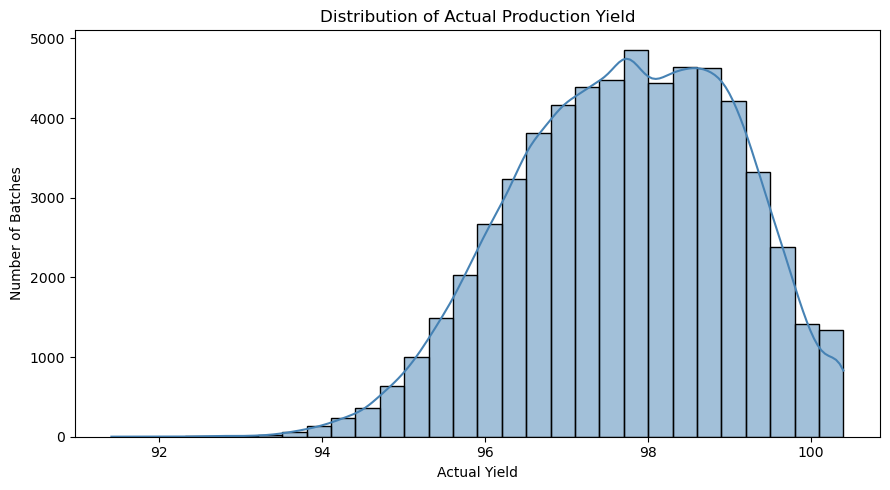

In [567]:
plt.figure(figsize=(9, 5))                                                  # new chart
sns.histplot(data=eda_data, x="actual_yield", bins=30, kde=True, color="steelblue")  # histogram of yield with a density curve
plt.title("Distribution of Actual Production Yield")                        # chart title
plt.xlabel("Actual Yield")                                                  # x-axis label
plt.ylabel("Number of Batches")                                             # y-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**

- The histogram peaks at about **97.7 to 98.0**, where 4,858 batches sit in a single bar. The mean is **97.71**, the median **97.77** and the standard deviation **1.34**.
- The curve is slightly stretched to the left (skewness −0.27): the mean is a little lower than the median because a thin tail of poor batches runs down to the minimum of **91.41**. The right side stops sharply at **100.4**.
- About **70%** of batches fall between 96 and 99; only **2.4%** are below 95. Of those below 95, almost all (1,423 of 1,444) are Oral Solids.
- **2.9% of batches report a yield above 100**, which is physically impossible on a mass-balance basis; it usually means the yield is calculated against a theoretical quantity or an assay-corrected basis. Confirm the calculation with production before using these values.
- The average batch beats its target yield by **1.69 points**, and **7.5%** fall below their own target. Because each product has a different target (94 to 98), judge a batch against its own target, not against 97.7.

### B. Distribution of production hours and process temperature

These histograms show how long production runs take and how average process temperature is distributed.

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


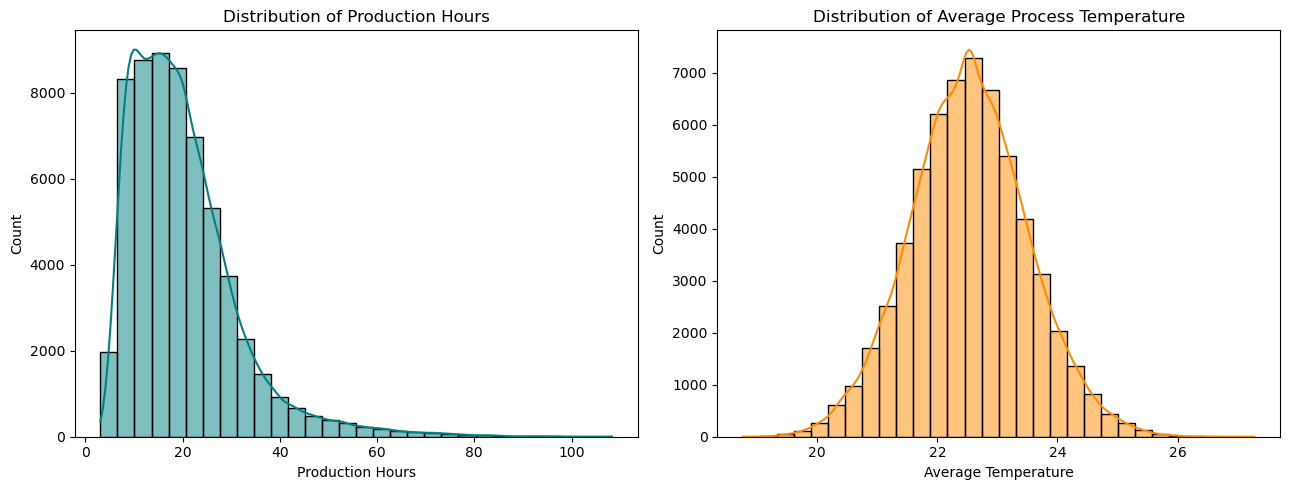

In [570]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))                             # two charts side by side

sns.histplot(data=eda_data, x="production_hours", bins=30, kde=True, ax=axes[0], color="teal")  # histogram of production hours
axes[0].set_title("Distribution of Production Hours")                       # left chart title
axes[0].set_xlabel("Production Hours")                                      # left x-axis label

sns.histplot(data=eda_data, x="temp_avg", bins=30, kde=True, ax=axes[1], color="darkorange")  # histogram of average temperature
axes[1].set_title("Distribution of Average Process Temperature")            # right chart title
axes[1].set_xlabel("Average Temperature")                                   # right x-axis label

plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**

- **Production hours** are strongly right-skewed (skewness 1.7). The typical run is short: the median is **18 hours**, the mean **20.0** and the tallest bar (13.6 to 17.1 hours) holds 8,918 batches. **86%** of batches finish within 30 hours, 10% take under 8.5 hours, but the longest 1% take more than **60.9 hours** and the maximum is **108.3 hours**.
- The long tail is a product-mix effect, not one bad process: median run time is **21 hours for Oral Solids**, 14 for Injectables, 11 for Creams and only **8.8 hours for Oral Liquids**. Judge a run against its own product.
- **Average temperature** is almost perfectly bell-shaped (skewness 0.08), centred at **22.5 °C** with a standard deviation of **0.98 °C**. **87%** of batches run between 21 and 24 °C and the middle 90% between 20.9 and 24.2 °C. The extremes (18.8 and 27.3 °C) are rare, so the temperature is tightly controlled; whether 27.3 °C breaches an approved limit must be checked against the product specification.

### C. Batch counts by manufacturing section and dosage form

The charts show which manufacturing sections and dosage forms contribute the most records.

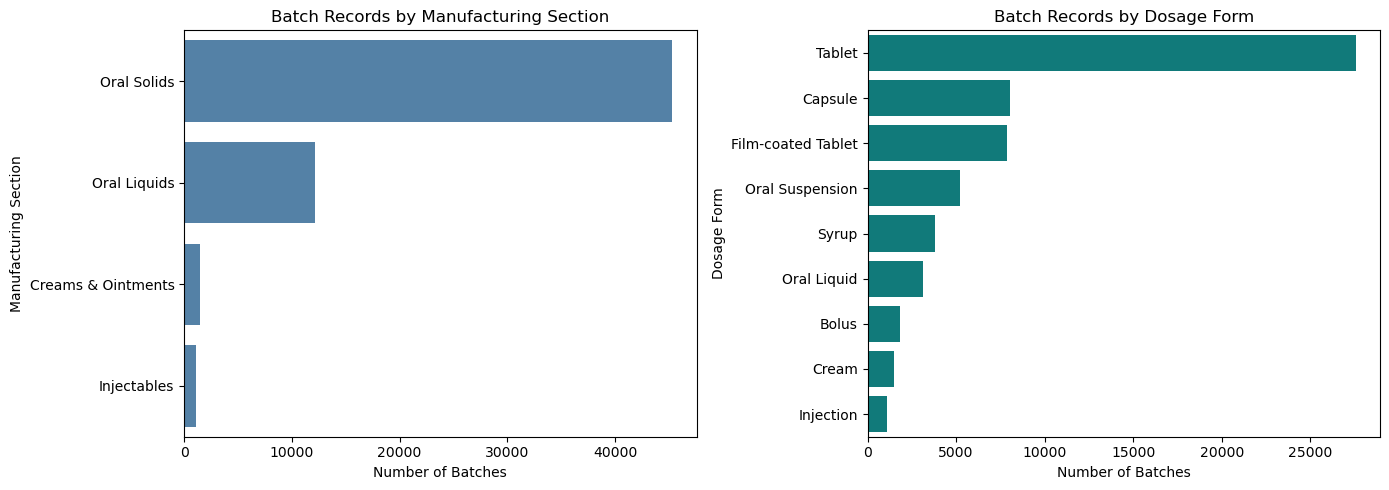

In [573]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                             # two charts side by side

section_counts = eda_data["manufacturing_section"].value_counts().head(12)  # batches per section (top 12)
sns.barplot(x=section_counts.values, y=section_counts.index, ax=axes[0], color="steelblue")  # bar chart of batches per section
axes[0].set_title("Batch Records by Manufacturing Section")                 # left chart title
axes[0].set_xlabel("Number of Batches")                                     # left x-axis label
axes[0].set_ylabel("Manufacturing Section")                                 # left y-axis label

form_counts = eda_data["dosage_form"].value_counts().head(12)               # batches per dosage form (top 12)
sns.barplot(x=form_counts.values, y=form_counts.index, ax=axes[1], color="darkcyan")  # bar chart of batches per dosage form
axes[1].set_title("Batch Records by Dosage Form")                           # right chart title
axes[1].set_xlabel("Number of Batches")                                     # right x-axis label
axes[1].set_ylabel("Dosage Form")                                           # right y-axis label

plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation (with the actual values).**

- The records are dominated by **Oral Solids: 45,282 batches (75.5%)**, then Oral Liquids 12,170 (20.3%), Creams & Ointments 1,480 (2.5%) and Injectables 1,068 (1.8%).
- By dosage form, **Tablets alone are 27,561 batches (45.9%)**, followed by Capsules 8,066 (13.4%), Film-coated Tablets 7,855 (13.1%), Oral Suspension 5,242 (8.7%), Syrup 3,801 (6.3%), Oral Liquid 3,127 (5.2%), Bolus 1,800 (3.0%), Cream 1,480 (2.5%) and Injection 1,068 (1.8%).
- Two practical consequences: plant-wide averages mostly describe tablets, and the small sections have few events. Injectables, for example, have only **51 failed batches**, so any failure rate for them is much less certain than the rates for tablets (805 failures). These are record counts, not revenue or workload.

#### Sales and inventory

### D. Distribution of order quantity and net order value

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


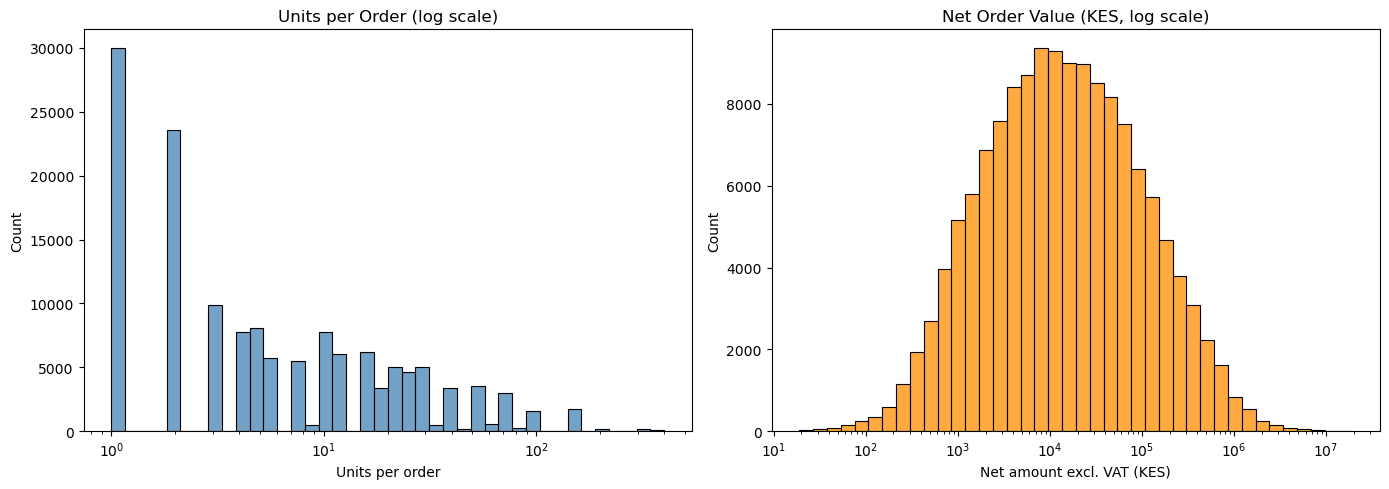

       quantity  net_amount_excl_vat_kes
count  143955.0                 143955.0
mean       14.4                  81271.8
std        27.5                 276298.8
min         1.0                     19.0
25%         2.0                   3300.0
50%         5.0                  13366.2
75%        15.0                  56306.2
max       400.0               19341750.0


In [577]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                             # two charts side by side
sns.histplot(data=valid_sales, x="quantity", bins=40, log_scale=True, ax=axes[0], color="steelblue")  # units per order (log scale)
axes[0].set_title("Units per Order (log scale)")                            # left chart title
axes[0].set_xlabel("Units per order")                                       # left x-axis label
sns.histplot(data=valid_sales, x="net_amount_excl_vat_kes", bins=40, log_scale=True, ax=axes[1], color="darkorange")  # order value
axes[1].set_title("Net Order Value (KES, log scale)")                       # right chart title
axes[1].set_xlabel("Net amount excl. VAT (KES)")                            # right x-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
print(valid_sales[["quantity", "net_amount_excl_vat_kes"]].describe().round(1))  # numbers behind the charts

**Interpretation.**
- **Units per order** is strongly right-skewed: the median order is **5 units** and the mean **14.4**. Half of all orders are 2 to 15 units, but a long tail runs up to **400 units**. The tallest bars are single-unit orders (**31,234**) and two-unit orders (24,567); smaller spikes sit at round sizes such as 5 and 10.
- **Net order value** is roughly bell-shaped on the log scale, centred on about **KES 13,400** (median). The middle half of orders is worth **KES 3,300 to 56,300**, and the largest single order is **KES 19.3 million**.
- Because both are so skewed, totals are driven by a minority of large orders, and medians describe a "typical" order better than means.

### E. Distribution of unit price and discount

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


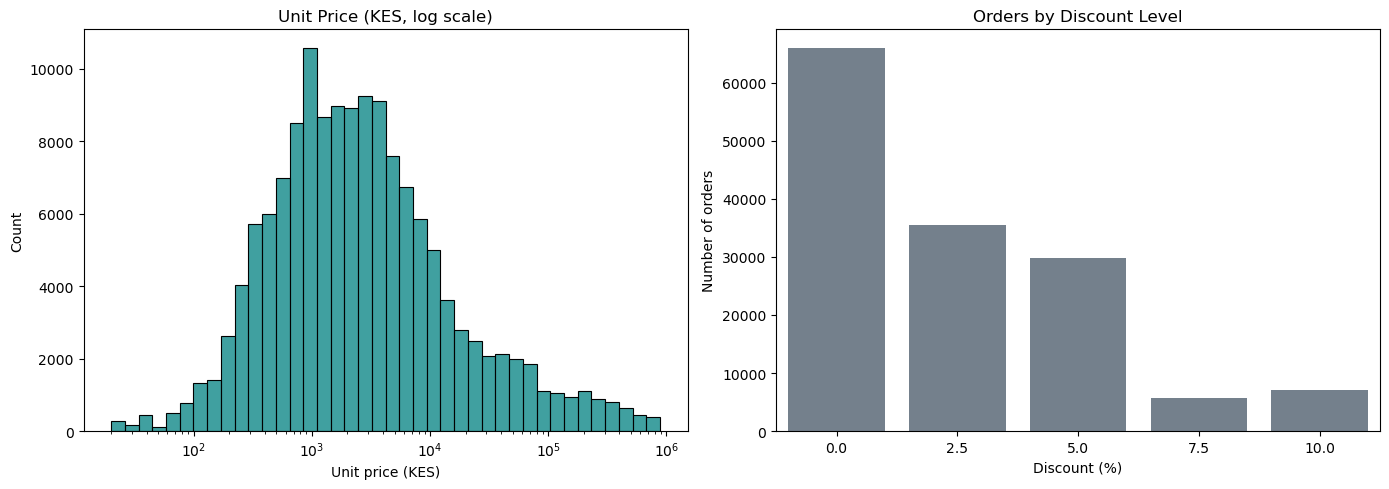

{0.0: 45.8, 2.5: 24.6, 5.0: 20.7, 7.5: 4.0, 10.0: 4.9}


In [580]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                             # two charts side by side
sns.histplot(data=valid_sales, x="unit_price_kes", bins=40, log_scale=True, ax=axes[0], color="teal")  # price per unit (log scale)
axes[0].set_title("Unit Price (KES, log scale)")                            # left chart title
axes[0].set_xlabel("Unit price (KES)")                                      # left x-axis label
discount_counts = valid_sales["discount_pct"].value_counts().sort_index()   # orders per discount level
sns.barplot(x=discount_counts.index.astype(str), y=discount_counts.values, ax=axes[1], color="slategray")  # bar per discount level
axes[1].set_title("Orders by Discount Level")                               # right chart title
axes[1].set_xlabel("Discount (%)"); axes[1].set_ylabel("Number of orders")  # axis labels
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
print((discount_counts / discount_counts.sum() * 100).round(1).to_dict())   # share of orders per discount level (%)

**Interpretation.**
- **Unit price** spans from **KES 20 to KES 882,550**. The median is **KES 2,200** and the middle half lies between **KES 775 and 6,950**; the long right tail is Equipment.
- **Discounts** take only five values: **0% on 45.8% of orders**, 2.5% on 24.6%, 5% on 20.7%, 7.5% on 4.0% and 10% on 4.9%. The average discount is small (about 2.4%), so discounting is not a major revenue leak.

### F. Orders by branch, product category and payment method

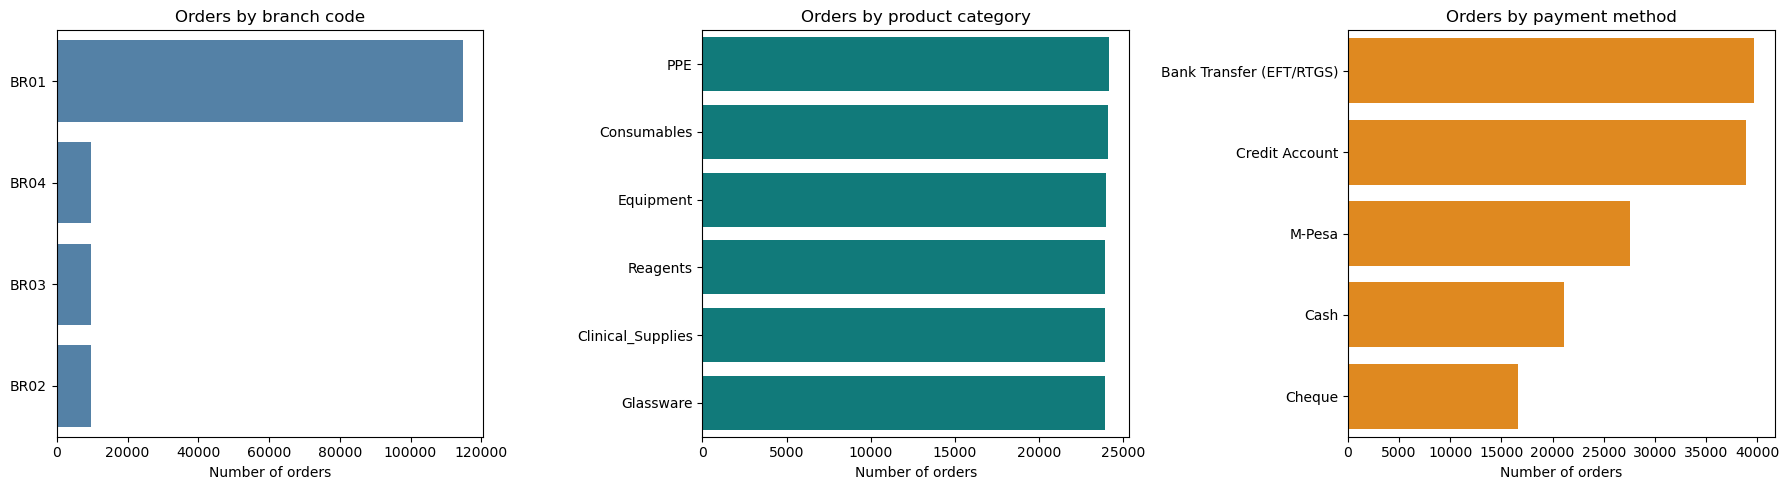

branch_code {'BR01': 79.8, 'BR04': 6.8, 'BR03': 6.7, 'BR02': 6.7}
product_category {'PPE': 16.8, 'Consumables': 16.7, 'Equipment': 16.7, 'Reagents': 16.6, 'Clinical_Supplies': 16.6, 'Glassware': 16.6}
payment_method {'Bank Transfer (EFT/RTGS)': 27.6, 'Credit Account': 27.0, 'M-Pesa': 19.2, 'Cash': 14.6, 'Cheque': 11.6}


In [583]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))                             # three charts side by side
for ax, col, colour in zip(axes, ["branch_code", "product_category", "payment_method"], ["steelblue", "darkcyan", "darkorange"]):
    counts = valid_sales[col].value_counts()                                # orders per label
    sns.barplot(x=counts.values, y=counts.index, ax=ax, color=colour)       # horizontal bar chart
    ax.set_title(f"Orders by {col.replace('_', ' ')}")                      # chart title
    ax.set_xlabel("Number of orders"); ax.set_ylabel("")                    # axis labels
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
for col in ["branch_code", "product_category", "payment_method"]:           # shares behind the charts
    print(col, (valid_sales[col].value_counts(normalize=True) * 100).round(1).to_dict())

**Interpretation.**
- **Branch:** **BR01 takes 79.8% of orders**; BR02, BR03 and BR04 take about **6.7–6.8% each**. BR01 is the main store, so stock policy matters most there.
- **Product category:** the six categories are almost equal in orders (**16.6–16.8% each**). They differ greatly in value, though (Section 5.8): Consumables and Reagents earn about 27% of sales each, Glassware under 5%.
- **Payment method:** Bank transfer (**27.6%**) and Credit account (**27.0%**) lead, then M-Pesa (19.2%), Cash (14.6%) and Cheque (11.6%). More than a quarter of orders are sold on credit.

### G. Distribution of stock receipts and unit cost

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


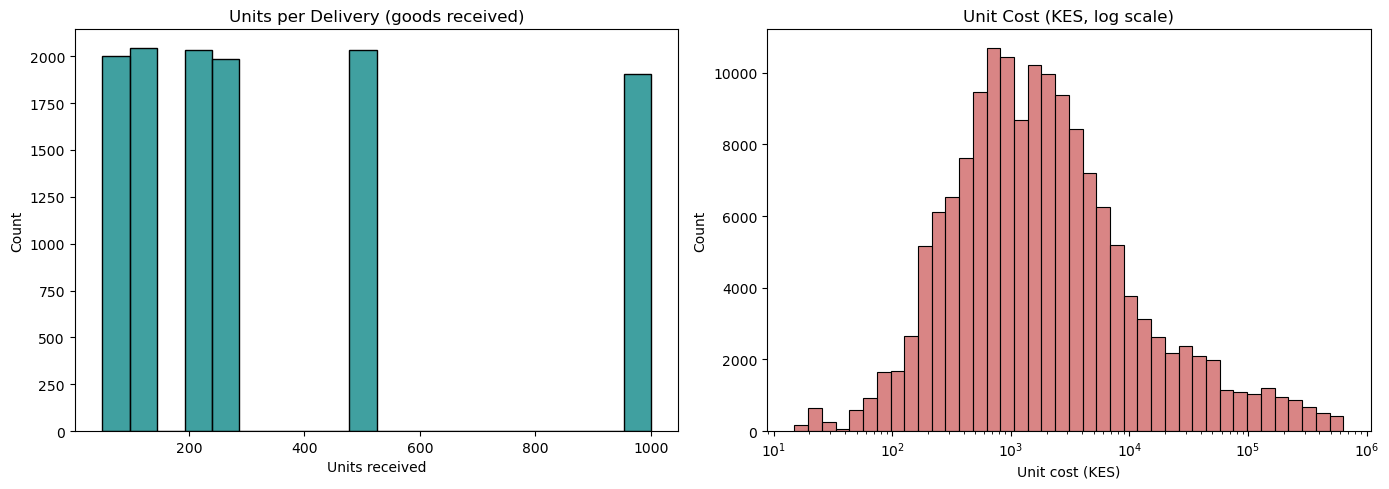

count    12000.0
mean       344.0
std        319.2
min         50.0
25%        100.0
50%        200.0
75%        500.0
max       1000.0
Name: units, dtype: float64


In [586]:
receipts = inventory_eda[inventory_eda["direction"] == "Received"]          # goods-received movements
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                             # two charts side by side
sns.histplot(data=receipts, x="units", bins=20, ax=axes[0], color="teal")   # units per delivery
axes[0].set_title("Units per Delivery (goods received)")                    # left chart title
axes[0].set_xlabel("Units received")                                        # left x-axis label
sns.histplot(data=inventory_eda, x="unit_cost_kes", bins=40, log_scale=True, ax=axes[1], color="indianred")  # cost per unit
axes[1].set_title("Unit Cost (KES, log scale)")                             # right chart title
axes[1].set_xlabel("Unit cost (KES)")                                       # right x-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
print(receipts["units"].describe().round(1))                                # numbers behind the left chart

**Interpretation.**
- **Deliveries** come in a handful of fixed lot sizes: **50, 100, 200, 250, 500 and 1,000 units** (about 2,000 deliveries of each size). The median delivery is **200 units** and the mean **344**. Fixed lot sizes, rather than quantities matched to demand, help explain why stock builds up.
- **Unit cost** has the same skewed shape as price: median **KES 1,550**, from KES 15 up to **KES 635,450**.

## 5.4 Outlier review

#### Production and maintenance

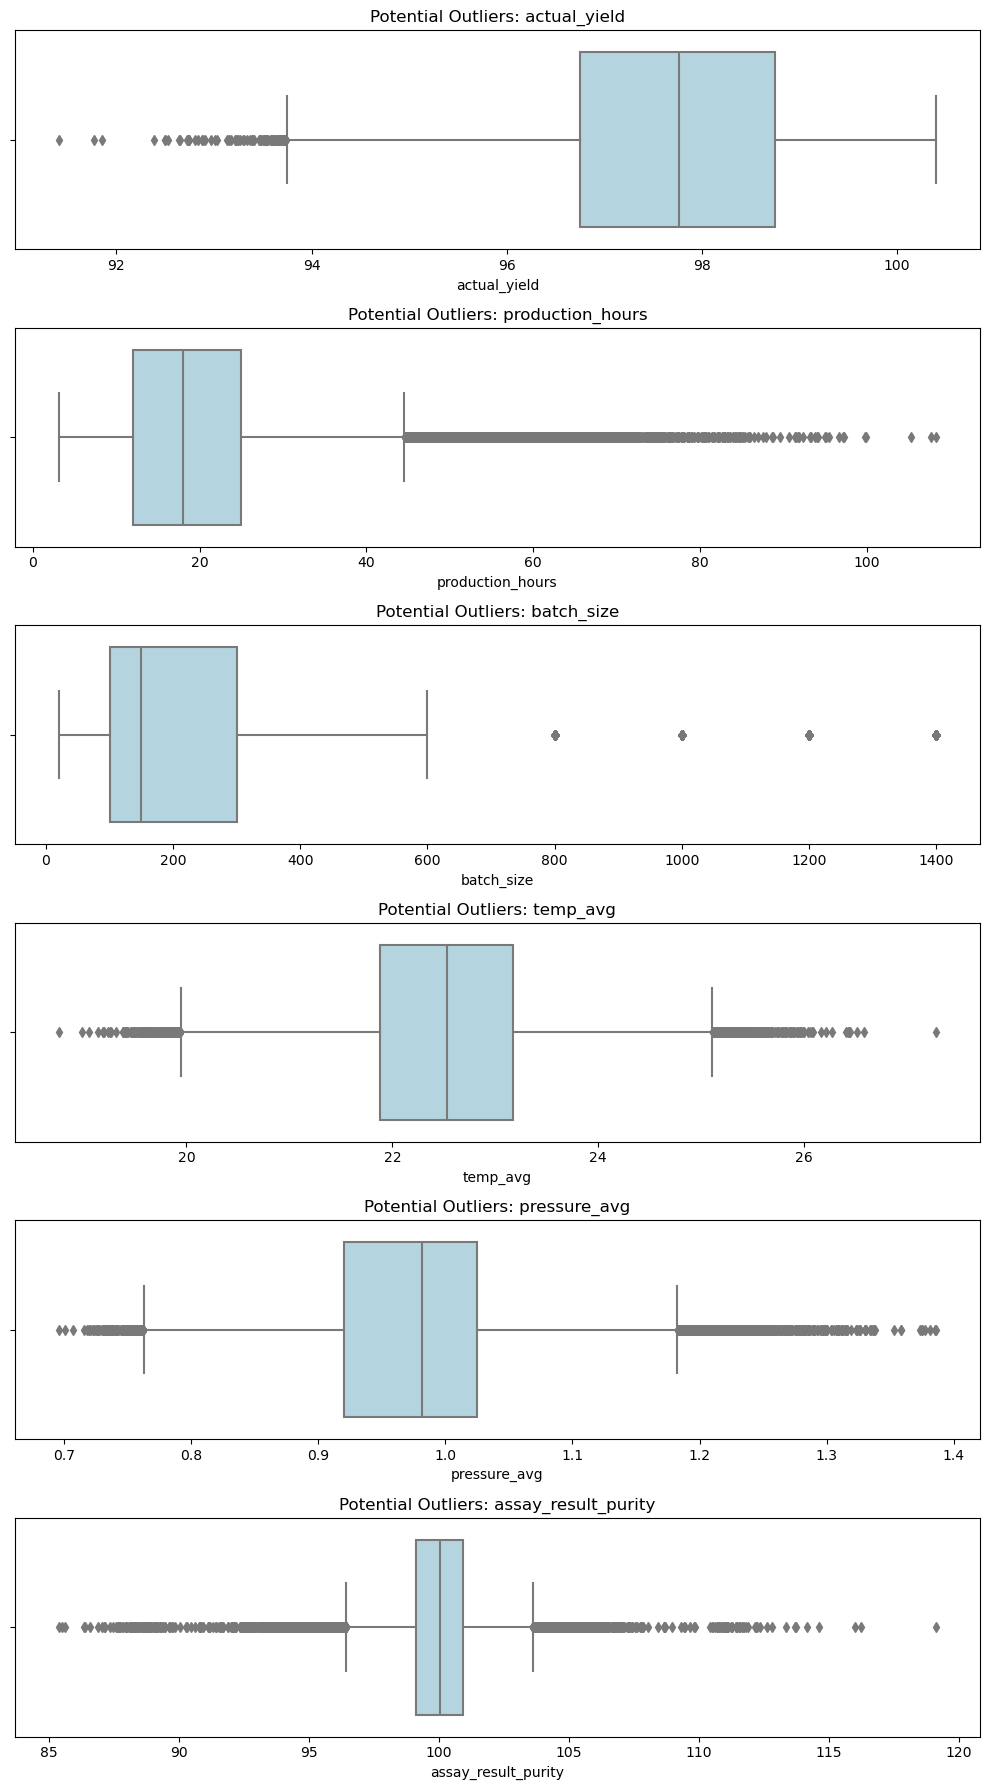

In [590]:
outlier_columns = [                                                         # columns to check for outliers (if present)
    col for col in ["actual_yield", "production_hours", "batch_size",
                    "temp_avg", "pressure_avg", "assay_result_purity"]
    if col in eda_data.columns
]

fig, axes = plt.subplots(len(outlier_columns), 1, figsize=(10, 3 * len(outlier_columns)))  # one chart per column, stacked
if len(outlier_columns) == 1:                                               # with a single column
    axes = [axes]                                                           # wrap the single chart in a list

for ax, col in zip(axes, outlier_columns):                                  # loop over charts and columns
    sns.boxplot(x=eda_data[col], ax=ax, color="lightblue")                  # box plot; points beyond the whiskers are outliers
    ax.set_title(f"Potential Outliers: {col}")                              # chart title
    ax.set_xlabel(col)                                                      # x-axis label

plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.** 

The line in each box is the median, the box is the middle 50% and the dots beyond the whiskers are values outside the 1.5 × IQR fences.

| Variable | Whisker limits | Batches outside | What it means |
|---|---|---|---|
| Actual yield | 93.75 to 101.75 | 97 low (0.2%), none high | a handful of very poor batches, all low |
| Production hours | up to 44.5 h | 2,212 high (3.7%) | genuinely long runs, mostly Oral Solids |
| Batch size | up to 600 | 7,948 high (13.3%) | **not real outliers**: kilograms and litres are mixed in one column (median 120 kg for solids, 800 L for liquids) |
| Average temperature | 19.9 to 25.1 °C | 545 (0.9%) | tightly controlled; both directions |
| Average pressure | 0.76 to 1.18 | 861 (1.4%) | 641 high, 220 low |
| Assay purity | 96.4 to 103.6 | 1,950 (3.3%) | 1,077 low, 873 high |

The most important finding is the **assay purity** outliers: batches with purity below 95 or above 105 fail **79% and 50%** of the time, against only **2.2%** inside 95 to 105. Extreme assay values are therefore real quality signals and must not be deleted as noise. The same reasoning is why the cleaning step flags rather than removes outliers.

#### Sales and inventory

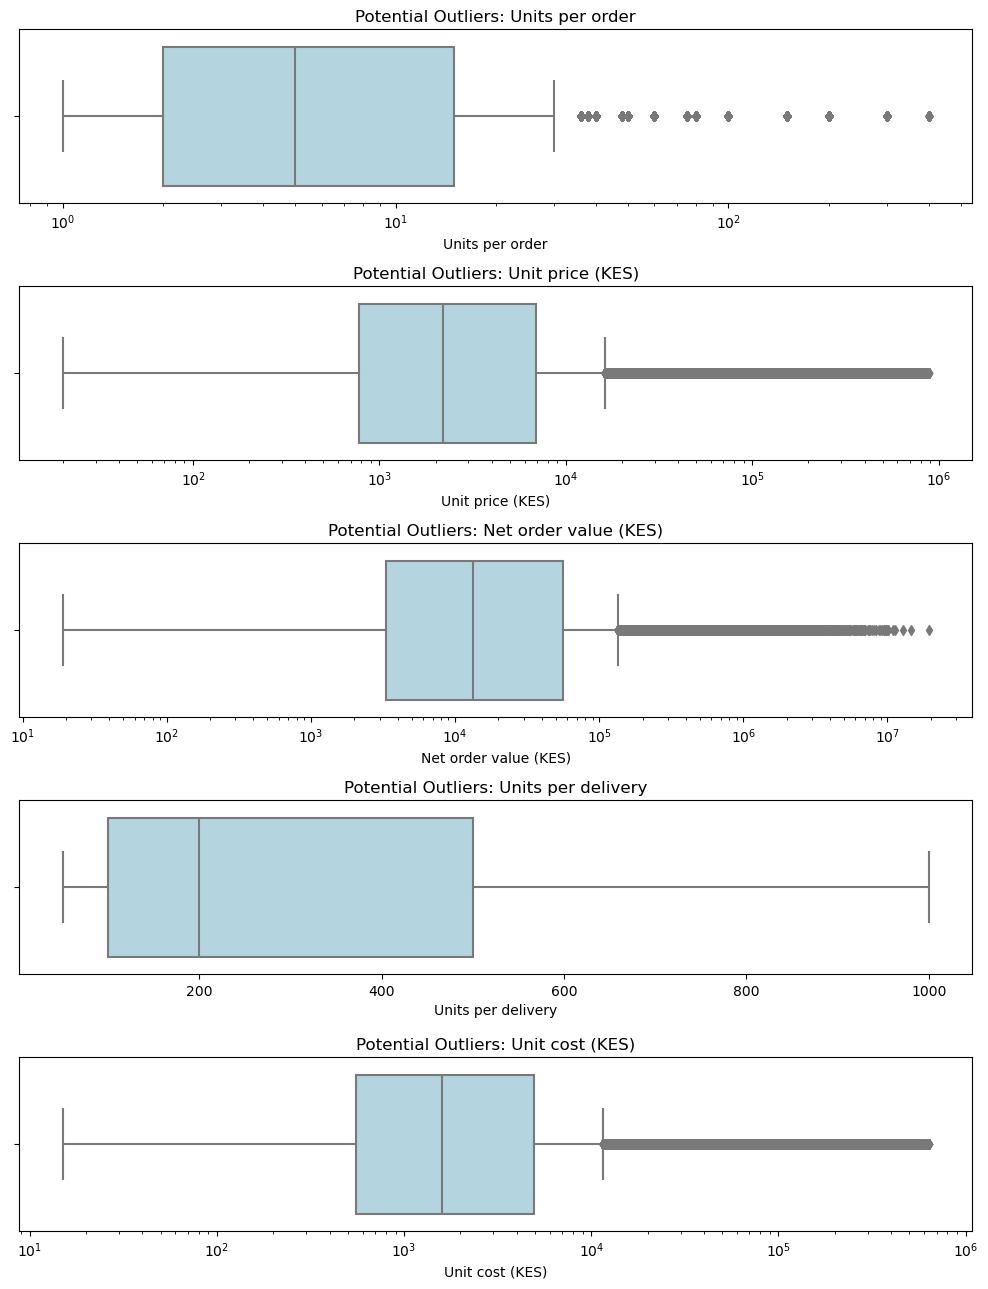

,Variable,Lower limit,Upper limit,Values above,% above
0,Units per order,1.0,34.5,15020,10.4
1,Unit price (KES),20.0,16212.5,20582,14.3
2,Net order value (KES),19.0,135815.6,19180,13.3
3,Units per delivery,50.0,1100.0,0,0.0
4,Unit cost (KES),15.0,11542.5,22331,14.3


In [593]:
outlier_plots = [(valid_sales, "quantity", "Units per order"), (valid_sales, "unit_price_kes", "Unit price (KES)"),
                 (valid_sales, "net_amount_excl_vat_kes", "Net order value (KES)"), (receipts, "units", "Units per delivery"),
                 (inventory_eda, "unit_cost_kes", "Unit cost (KES)")]          # table, column and label for each chart
fig, axes = plt.subplots(len(outlier_plots), 1, figsize=(10, 2.6 * len(outlier_plots)))  # one chart per column, stacked
for ax, (df, col, label) in zip(axes, outlier_plots):                       # loop over charts and columns
    sns.boxplot(x=df[col], ax=ax, color="lightblue")                        # box plot; points beyond the whiskers are outliers
    if col != "units":                                                      # skewed values on a log scale
        ax.set_xscale("log")
    ax.set_title(f"Potential Outliers: {label}")                            # chart title
    ax.set_xlabel(label)                                                    # x-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

rows = []                                                                   # outlier counts behind the charts
for df, col, label in outlier_plots:
    q1, q3 = df[col].quantile([0.25, 0.75])                                 # quartiles
    hi, lo = q3 + 1.5 * (q3 - q1), q1 - 1.5 * (q3 - q1)                     # whisker limits
    rows.append([label, max(lo, df[col].min()), hi, (df[col] > hi).sum(), 100 * (df[col] > hi).mean()])
display(pd.DataFrame(rows, columns=["Variable", "Lower limit", "Upper limit", "Values above", "% above"]).round(1))

**Interpretation.** Boxes are on a log scale where values are skewed; dots beyond the whiskers lie outside the 1.5 × IQR fences.

| Variable | Upper fence | Values above | % above | What it means |
|---|---|---|---|---|
| Units per order | 34.5 | 15,020 | 10.4% | bulk institutional orders (flagged as `bulk_order`) |
| Unit price (KES) | 16,213 | 20,582 | 14.3% | expensive items, mainly Equipment |
| Net order value (KES) | 135,816 | 19,180 | 13.3% | large or expensive orders |
| Units per delivery | 1,100 | 0 | 0% | fixed lot sizes, no unusual delivery |
| Unit cost (KES) | 11,543 | 22,331 | 14.3% | the same expensive items as the price outliers |

About one sale in seven is an "outlier" on price or value. That many outliers means a **product mix of cheap and expensive items**, not data errors, so they are kept. Analyses of price and value should be done **per category** or on a log scale.

## 5.5 Bivariate analysis

#### Production and maintenance

### A. Production hours vs actual yield, by batch outcome

Each point represents a batch. Colour distinguishes Passed and Failed batches. A sample is used for readability when there are many records.

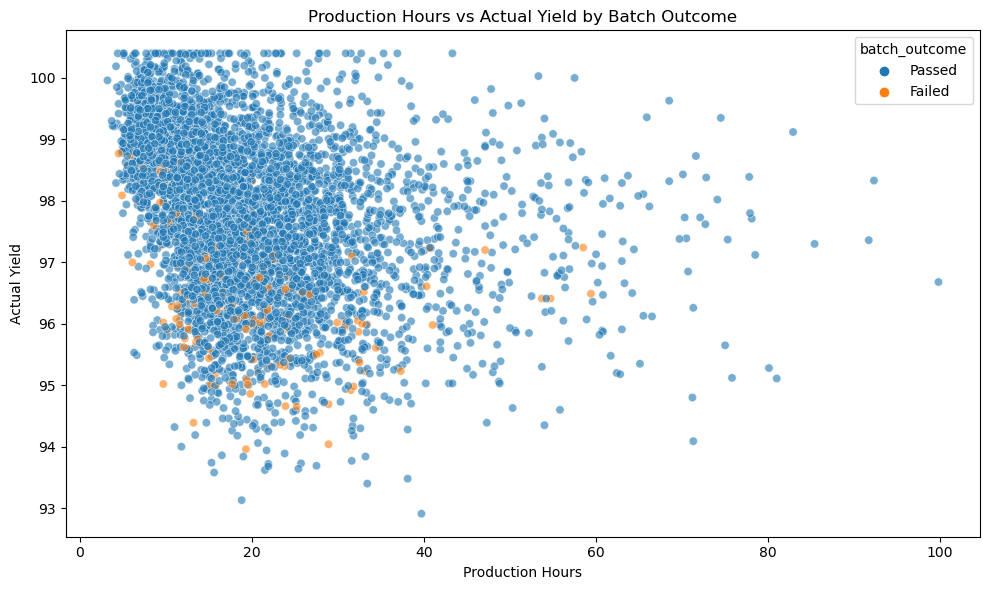

In [598]:
plot_data = eda_data[["production_hours", "actual_yield", "batch_outcome"]].dropna().copy()  # columns for the scatter plot
if len(plot_data) > 5000:                                                   # large data makes plots slow
    plot_data = plot_data.sample(5000, random_state=42)                     # plot a random 5,000-row sample

plt.figure(figsize=(10, 6))                                                 # new chart
sns.scatterplot(data=plot_data, x="production_hours", y="actual_yield",     # scatter of hours vs yield, coloured by outcome
                hue="batch_outcome", alpha=0.6)
plt.title("Production Hours vs Actual Yield by Batch Outcome")              # chart title
plt.xlabel("Production Hours")                                              # x-axis label
plt.ylabel("Actual Yield")                                                  # y-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**

- Across all batches, yield and production hours are **negatively correlated (r = −0.30)**. Average yield falls from **98.83** for runs of 10 hours or less to **97.71** for 10 to 20 hours and about **97.2 to 97.3** beyond 30 hours.
- This is largely **product mix, not a time effect**. Inside each manufacturing section the correlation is almost zero (Oral Solids −0.06, Oral Liquids −0.01, Creams +0.03, Injectables +0.05). Fast oral liquids have high yields; slow oral solids have lower yields; pooling them creates the downward slope.
- The red (Failed) and the blue (Passed) points overlap completely. Failed batches have a slightly lower average yield (**96.57 vs 97.75**) but nearly the same run time (median 17.2 vs 18.0 hours). No duration separates passes from failures, so production time alone cannot predict failure.

### B. Batch size vs actual yield, by batch outcome

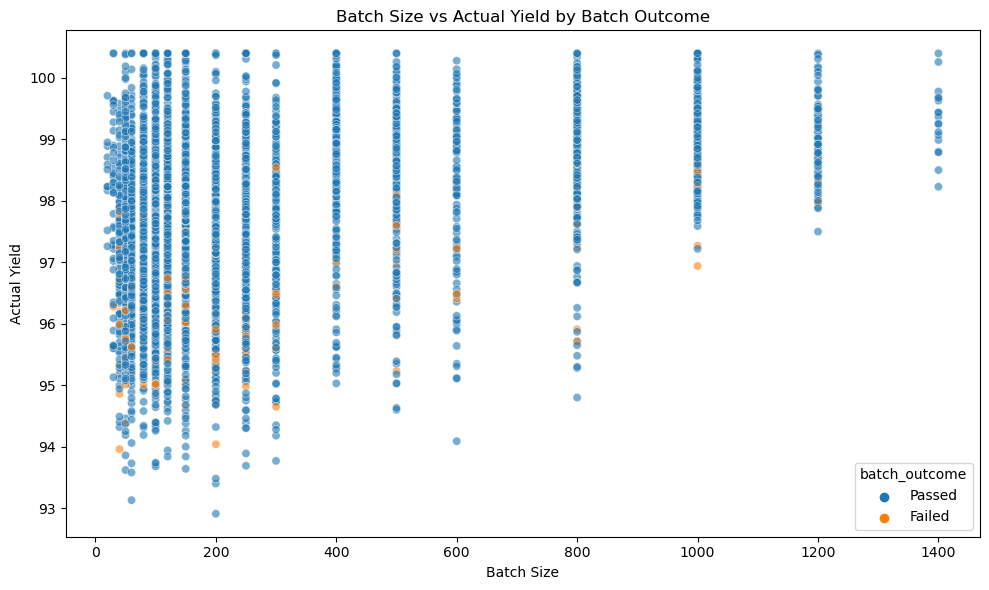

In [601]:
batch_plot = eda_data[["batch_size", "actual_yield", "batch_outcome"]].dropna().copy()  # columns for the scatter plot
if len(batch_plot) > 5000:                                                  # large data makes plots slow
    batch_plot = batch_plot.sample(5000, random_state=42)                   # plot a random 5,000-row sample

plt.figure(figsize=(10, 6))                                                 # new chart
sns.scatterplot(data=batch_plot, x="batch_size", y="actual_yield",          # scatter of batch size vs yield, coloured by outcome
                hue="batch_outcome", alpha=0.6)
plt.title("Batch Size vs Actual Yield by Batch Outcome")                    # chart title
plt.xlabel("Batch Size")                                                    # x-axis label
plt.ylabel("Actual Yield")                                                  # y-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**

- Overall, larger batches have higher yield (**r = +0.39**). Mean yield is **97.4** for batches up to 100, **98.4** for 300 to 600 and about **99.0** above 1,000.
- The columns of points in the chart are separate products and units, not a smooth trend: batch size is stored in **kilograms for solids (median 120 kg) and litres for liquids (median 800 L)**, and liquids have high yields. Within the kg group the correlation is **−0.01**; within litres it is only **+0.10**.
- Failure rate by batch size shows no clear pattern (3.4%, 2.8%, 3.5%, 3.0% and 2.2% from the smallest to the largest band), so batch size is not a reliable warning sign for failure. Compare yield only within one product and unit.

### C. Equipment age vs actual yield

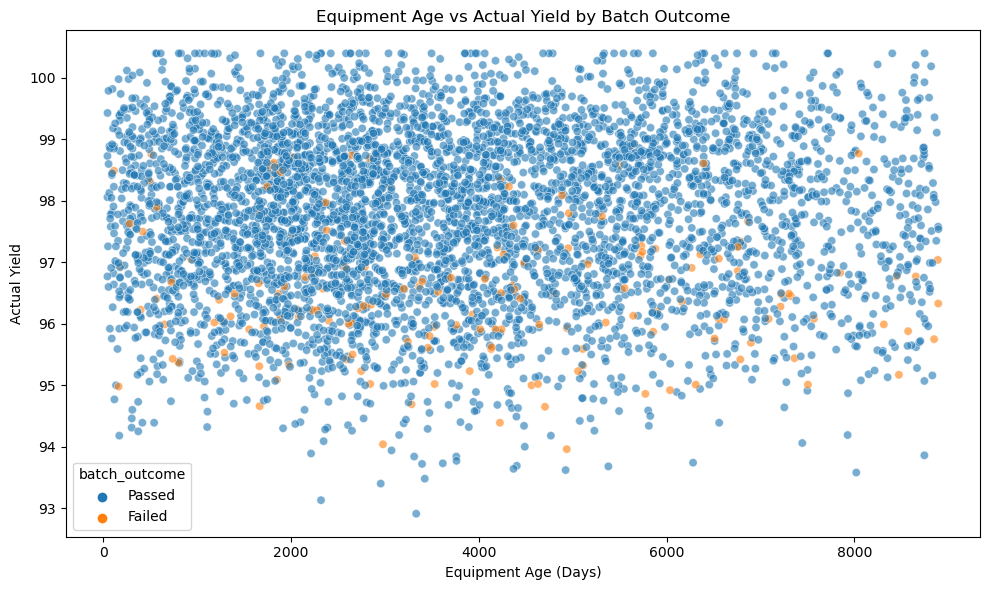

In [604]:
equipment_plot = eda_data[["equipment_age_days", "actual_yield", "batch_outcome"]].dropna().copy()  # columns for the scatter plot
if len(equipment_plot) > 5000:                                              # large data makes plots slow
    equipment_plot = equipment_plot.sample(5000, random_state=42)           # plot a random 5,000-row sample

plt.figure(figsize=(10, 6))                                                 # new chart
sns.scatterplot(data=equipment_plot, x="equipment_age_days", y="actual_yield",  # scatter of equipment age vs yield, coloured by outcome
                hue="batch_outcome", alpha=0.6)
plt.title("Equipment Age vs Actual Yield by Batch Outcome")                 # chart title
plt.xlabel("Equipment Age (Days)")                                          # x-axis label
plt.ylabel("Actual Yield")                                                  # y-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**

- **Equipment age has no relationship with yield (r = 0.003).** Mean yield is 97.70, 97.70, 97.73, 97.78 and 97.61 across the five age bands (0 to 5, 5 to 10, 10 to 15, 15 to 20 and over 20 years). The cloud of points is flat.
- **Age does relate to failure.** The failure rate climbs steadily from **2.55%** (equipment under 5 years) and **2.60%** (5 to 10 years) to **3.30%**, **4.02%** and **4.35%** (over 20 years). Failed batches ran on equipment that was on average **11.6 years** old versus **10.3 years** for passed batches.
- So older machines do not make less product per batch, but a larger share of that product is rejected at the laboratory. This is an association, because age is also correlated with calendar year (r = 0.71), so older records and older equipment overlap; use the maintenance records to confirm.

### D. Actual yield across manufacturing sections

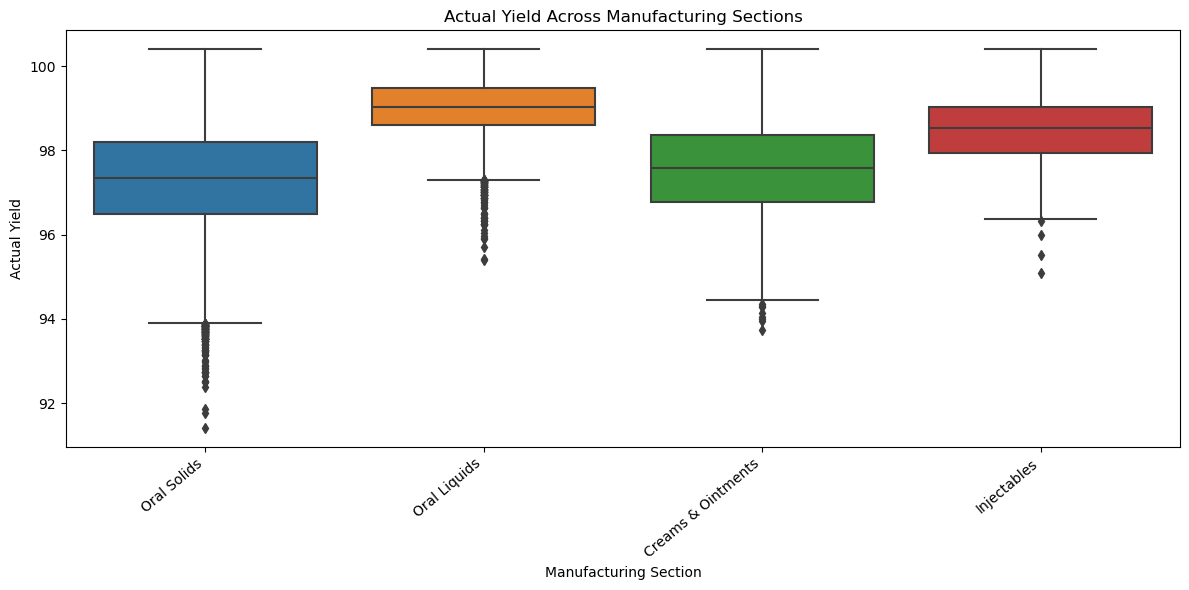

In [607]:
section_yield = eda_data.dropna(subset=["manufacturing_section", "actual_yield"]).copy()  # rows with a section and a yield
top_sections = section_yield["manufacturing_section"].value_counts().head(12).index  # the 12 largest sections
section_yield = section_yield[section_yield["manufacturing_section"].isin(top_sections)]  # keep only those sections

plt.figure(figsize=(12, 6))                                                 # new chart
sns.boxplot(data=section_yield, x="manufacturing_section", y="actual_yield")  # yield distribution per section
plt.title("Actual Yield Across Manufacturing Sections")                     # chart title
plt.xlabel("Manufacturing Section")                                         # x-axis label
plt.ylabel("Actual Yield")                                                  # y-axis label
plt.xticks(rotation=40, ha="right")                                         # tilt the x-axis labels
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.** 

Median yields are **Oral Liquids 99.04** (narrow spread, standard deviation 0.65), **Injectables 98.53** (0.82), **Creams & Ointments 97.57** (1.20) and **Oral Solids 97.35** (1.27, the widest). By dosage form, Syrup, Oral Liquid and Oral Suspension are all about 99.0, Capsule 98.0, Tablet 97.35, Film-coated Tablet 96.85 and **Bolus 96.45** is the lowest.

Do not read a lower box as a worse section: products have different targets (94 to 98), and the low-yield batches (below 95) come almost entirely from Oral Solids. Oral Solids is the section to review first because it combines the **lowest median yield, the widest spread and the most failed batches (1,387)**, although its failure rate (3.06%) is close to the plant average. The failure rate is highest for Injectables (4.78%), where there are few batches.

### E. Batch outcomes by maintenance status

This compares the number of Passed and Failed batches in each maintenance-status category.

batch_outcome,Failed,Passed
maintenance_status,,
Critical,33,443
Current,1687,52553
Due Soon,155,5129


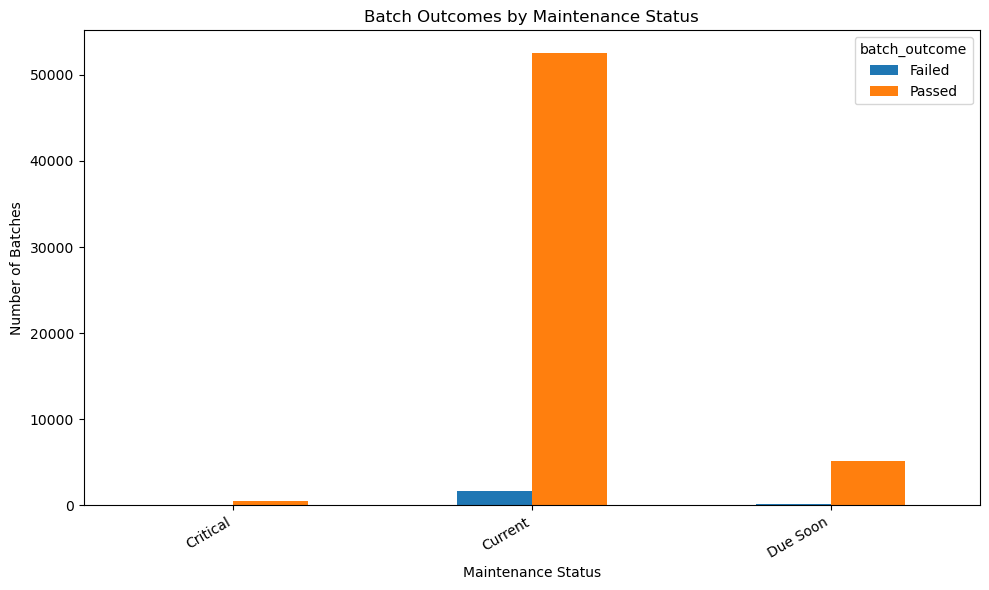

In [610]:
maintenance_plot = eda_data[["maintenance_status", "batch_outcome"]].copy()  # status and outcome columns
maintenance_plot["maintenance_status"] = maintenance_plot["maintenance_status"].fillna("Unknown")  # label missing status as Unknown

maintenance_table = pd.crosstab(                                            # count batches per status and outcome
    maintenance_plot["maintenance_status"],
    maintenance_plot["batch_outcome"]
)
display(maintenance_table)                                                  # show the table

maintenance_table.plot(kind="bar", figsize=(10, 6))                         # grouped bar chart of the table
plt.title("Batch Outcomes by Maintenance Status")                           # chart title
plt.xlabel("Maintenance Status")                                            # x-axis label
plt.ylabel("Number of Batches")                                             # y-axis label
plt.xticks(rotation=30, ha="right")                                         # tilt the x-axis labels
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**

| Maintenance status | Failed | Passed | Failure rate |
|---|---:|---:|---:|
| Critical | 33 | 443 | **6.93%** |
| Current | 1,687 | 52,553 | 3.11% |
| Due Soon | 155 | 5,129 | 2.93% |

- The Current bar is tallest simply because **90.4%** of batches are on Current equipment; counts say nothing about risk, rates do.
- Batches run on **Critical** equipment fail **2.2 times as often** as those on Current equipment (6.9% against 3.1%). With only 476 Critical batches the uncertainty is wide (95% interval about **4.7% to 9.2%**), but even the lower end is above the Current rate, and a chi-square test gives p ≈ 0.000008, so the difference is very unlikely to be chance.
- **Due Soon** (2.9%) is no worse than Current, so the quality risk appears only once equipment has gone past due. That makes clearing the Critical backlog the most direct maintenance lever on quality. This is an association, not proof of cause.

#### Sales and inventory

### F. Unit price vs units per order, by order outcome

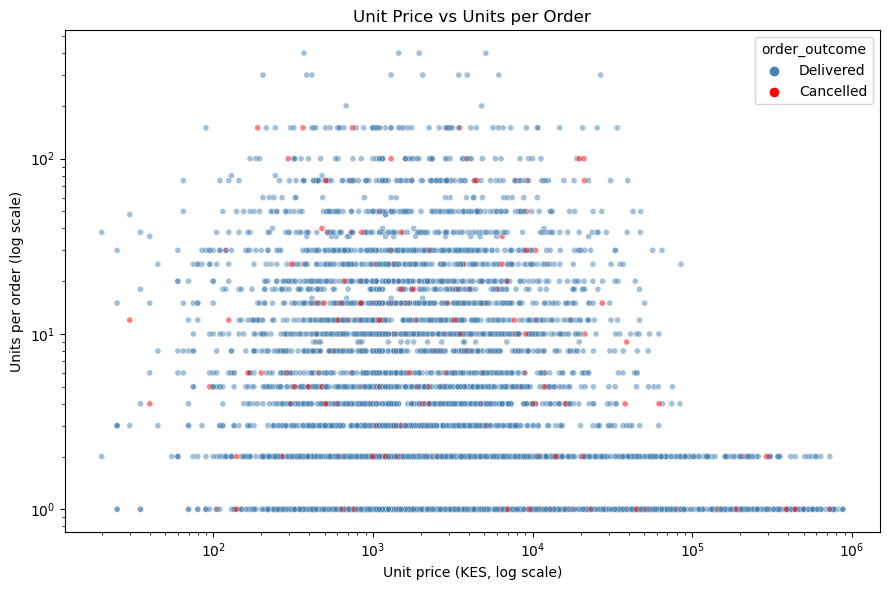

Spearman correlation, price vs quantity: -0.206
unit_price_kes
cheapest 25%    6.0
2nd             5.0
3rd             5.0
dearest 25%     2.0
Name: median units per order, dtype: float64


In [614]:
plot_data = sales_eda.sample(5000, random_state=RANDOM_STATE)               # sample for readability
plt.figure(figsize=(9, 6))                                                  # new chart
sns.scatterplot(data=plot_data, x="unit_price_kes", y="quantity", hue="order_outcome", alpha=0.5, s=18,
                palette={"Delivered": "steelblue", "Cancelled": "red"})     # one dot per order
plt.xscale("log"); plt.yscale("log")                                        # both values are skewed
plt.title("Unit Price vs Units per Order")                                  # chart title
plt.xlabel("Unit price (KES, log scale)"); plt.ylabel("Units per order (log scale)")  # axis labels
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
print("Spearman correlation, price vs quantity:", round(valid_sales["unit_price_kes"].corr(valid_sales["quantity"], method="spearman"), 3))
print(valid_sales.groupby(pd.qcut(valid_sales["unit_price_kes"], 4, labels=["cheapest 25%", "2nd", "3rd", "dearest 25%"]),
                          observed=True)["quantity"].median().rename("median units per order"))  # order size by price band

**Interpretation.**
- The cloud slopes gently downwards: **more expensive items are bought in smaller quantities** (Spearman **−0.21**). The median order is **6 units** for the cheapest quarter of items and **2 units** for the most expensive quarter.
- **Cancelled orders (red)** are spread across the whole cloud, with no cluster of cheap, expensive, small or large orders. Price and order size therefore do not explain cancellations.

### G. Discount level vs units per order

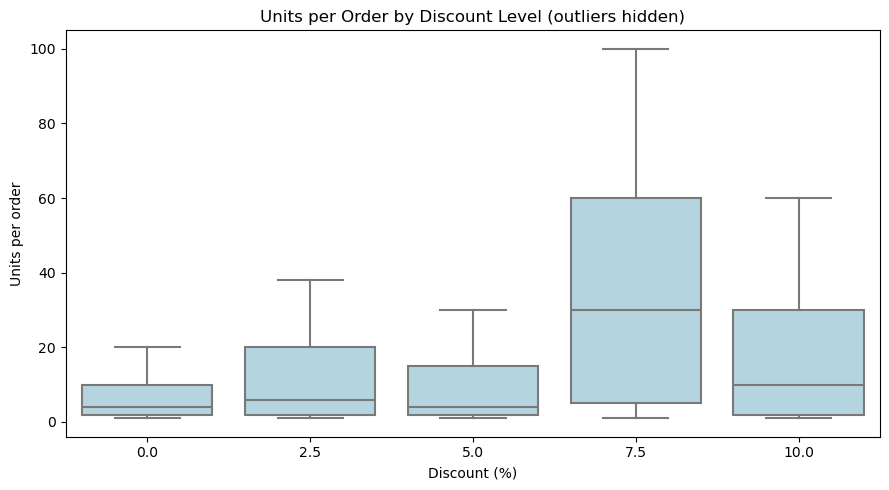

              count  median  mean
discount_pct                     
0.0           65862     4.0   7.8
2.5           35480     6.0  18.7
5.0           29866     4.0  14.3
7.5            5716    30.0  44.2
10.0           7031    10.0  30.4


In [617]:
plt.figure(figsize=(9, 5))                                                  # new chart
sns.boxplot(data=valid_sales, x="discount_pct", y="quantity", color="lightblue", showfliers=False)  # order size per discount level
plt.title("Units per Order by Discount Level (outliers hidden)")            # chart title
plt.xlabel("Discount (%)"); plt.ylabel("Units per order")                   # axis labels
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
print(valid_sales.groupby("discount_pct")["quantity"].agg(["count", "median", "mean"]).round(1))  # numbers behind the chart

**Interpretation.**
- Larger discounts go with **larger orders**. The median order is **4 units at 0% discount**, 6 at 2.5%, **30 units at 7.5%** and 10 at 10%. The 7.5% band holds the biggest orders (mean 44 units).
- This looks like a **volume-discount policy**. Discounts are given for size, not to push slow items, so they are a planned cost rather than a leak.

### H. Cancellation rate by branch, product category and payment method

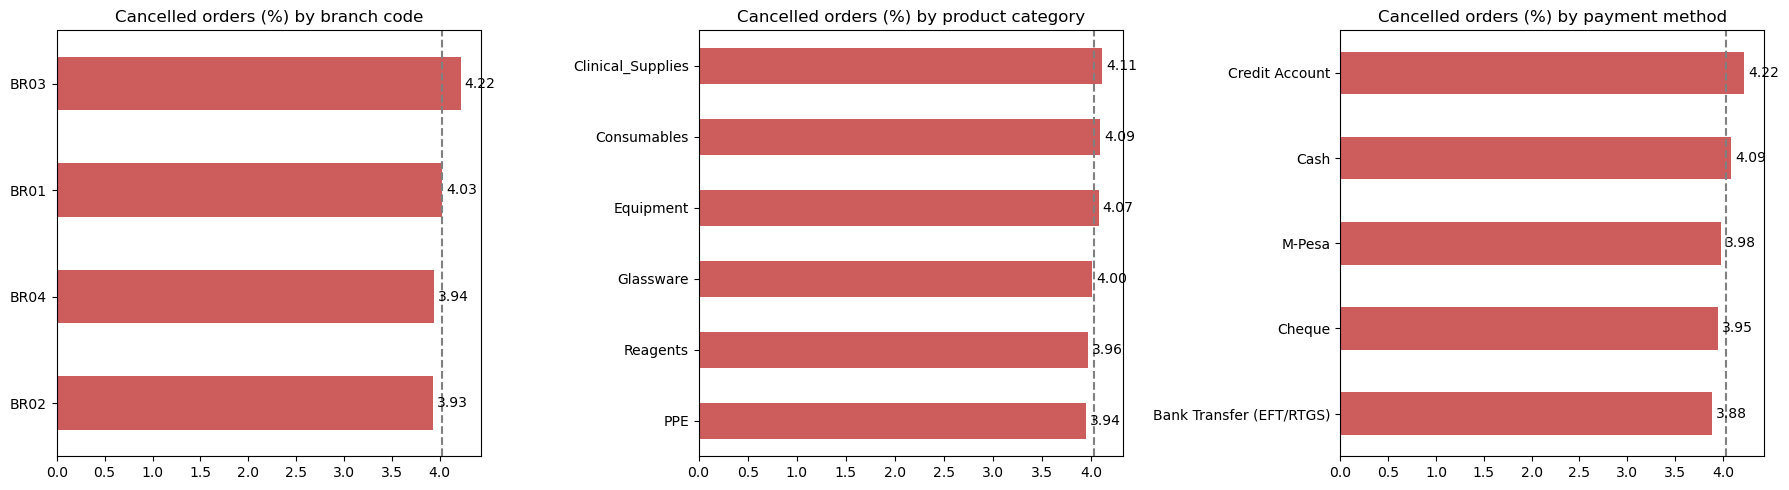

In [620]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))                             # three charts side by side
for ax, col in zip(axes, ["branch_code", "product_category", "payment_method"]):  # one chart per grouping
    rate = (sales_eda.groupby(col)["is_cancelled"].mean() * 100).sort_values()  # % of orders cancelled
    rate.plot.barh(ax=ax, color="indianred")                                # horizontal bar chart
    ax.axvline(sales_eda["is_cancelled"].mean() * 100, ls="--", color="gray")  # overall cancellation rate
    ax.set_title(f"Cancelled orders (%) by {col.replace('_', ' ')}"); ax.set_ylabel("")  # chart title
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)                   # value at the end of each bar
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**
- Cancellation rates are almost **identical everywhere**, close to the overall **4.0%** (dashed line):
  - by branch: **3.93%** (BR02) to **4.22%** (BR03);
  - by category: **3.94%** (PPE) to **4.11%** (Clinical supplies);
  - by payment method: **3.88%** (Bank transfer) to **4.22%** (Credit account).
- No branch, product or payment method stands out, so cancellations look like **random background noise**. There is no single process to fix; keeping them out of demand (Section 4.4) is the right treatment.

### I. Payment status by payment method

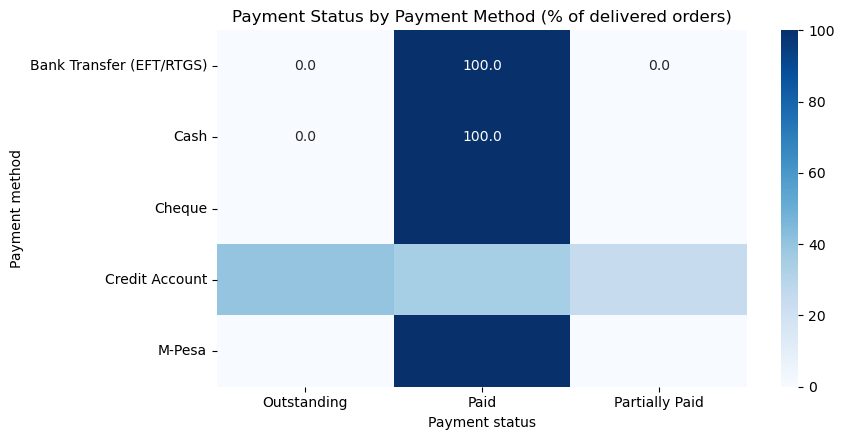

Outstanding balance by payment method (KES m): {'Bank Transfer (EFT/RTGS)': 0.0, 'Cash': 0.0, 'Cheque': 0.0, 'Credit Account': 1804.0, 'M-Pesa': 0.0}


In [623]:
pay = pd.crosstab(valid_sales["payment_method"], valid_sales["payment_status"], normalize="index") * 100  # % per method
plt.figure(figsize=(9, 4.5))                                                # new chart
sns.heatmap(pay, annot=True, fmt=".1f", cmap="Blues")                       # share of each status per method
plt.title("Payment Status by Payment Method (% of delivered orders)")       # chart title
plt.xlabel("Payment status"); plt.ylabel("Payment method")                  # axis labels
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
print("Outstanding balance by payment method (KES m):", (valid_sales.groupby("payment_method")["balance_due_kes"].sum() / 1e6).round(1).to_dict())

**Interpretation.**
- **Bank transfer, cash, cheque and M-Pesa orders are 100% paid.** Every unpaid shilling comes from **Credit account** orders.
- On credit accounts, **40.2%** of orders are still **Outstanding**, **24.7%** are **Partially paid** and only **35.1%** are fully paid.
- The total outstanding balance is **KES 1,804 million**, all on credit accounts. That is a receivables (cash-flow) risk for finance, separate from stock. Credit terms and collections should be reviewed.

### J. Units received vs units sold, by product category

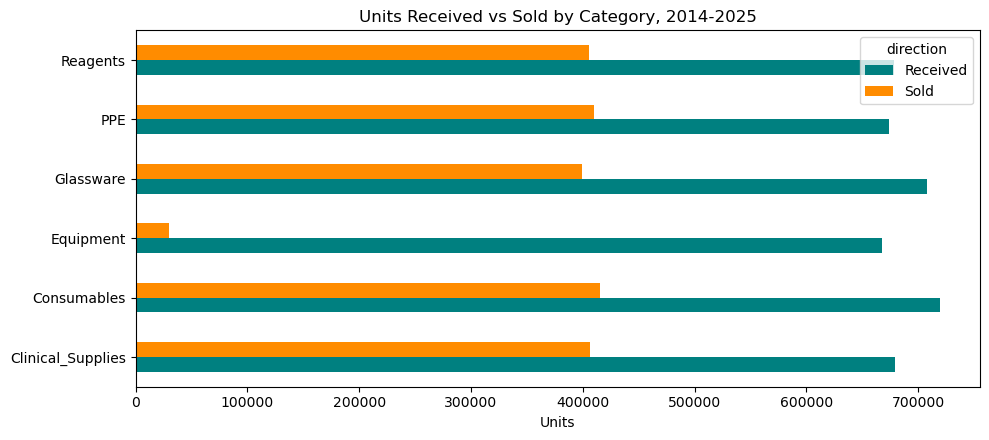

direction,Received,Sold,received / sold
product_id,,,
Clinical_Supplies,679450,406380,1.67
Consumables,719400,415164,1.73
Equipment,668050,29925,22.32
Glassware,708150,398889,1.78
PPE,673850,410399,1.64
Reagents,678650,405484,1.67


In [626]:
category_of = sales_data.groupby("product_id")["product_category"].first()  # product -> category
flow = inventory_eda.pivot_table(index=inventory_eda["product_id"].map(category_of), columns="direction",
                                 values="units", aggfunc="sum")              # units in and out per category
flow["received / sold"] = flow["Received"] / flow["Sold"]                   # how many units bought per unit sold
flow[["Received", "Sold"]].plot.barh(figsize=(10, 4.5), color=["teal", "darkorange"])  # side-by-side bars
plt.title("Units Received vs Sold by Category, 2014-2025")                  # chart title
plt.xlabel("Units"); plt.ylabel("")                                         # axis labels
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
display(flow.round(2))                                                      # numbers behind the chart

**Interpretation.**
- For five categories, about **1.6 to 1.8 units were received for every unit sold** over 2014–2025 (for example Consumables 719,400 received vs 415,164 sold).
- **Equipment is extreme: 668,050 units received against only 29,925 sold, 22 times more.** Equipment is also the most expensive category, which is why it holds most of the stock value (about KES 58 billion, Section 5.8).
- Purchasing is clearly not tied to sales. Before any write-down, confirm the Equipment receipt records with the stores team.

## 5.6 Multivariate analysis

#### Production and maintenance

### A. Correlation heatmap of numeric variables

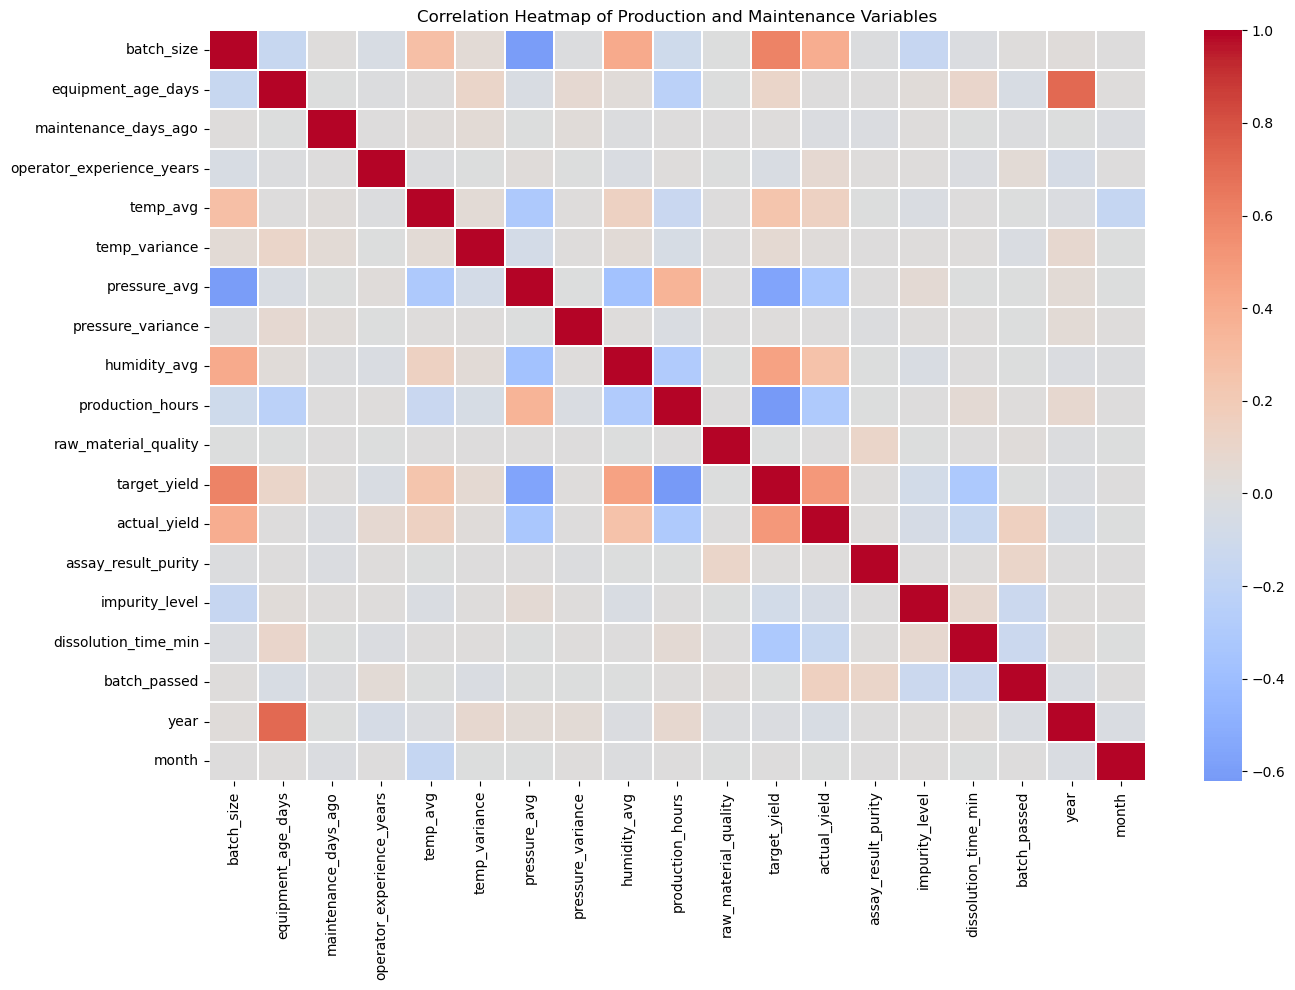

In [631]:
numeric_data = eda_data.select_dtypes(include="number")                     # numeric columns only
correlation = numeric_data.corr()                                           # correlation between every pair of columns

plt.figure(figsize=(14, 10))                                                # new chart
sns.heatmap(correlation, cmap="coolwarm", center=0, annot=False, linewidths=0.3)  # heatmap: red = positive, blue = negative
plt.title("Correlation Heatmap of Production and Maintenance Variables")    # chart title
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.** 

Red means positive, blue negative and the colour strength the size of the correlation.

- **Strongest relationships in the file:** equipment age and calendar year (**+0.71**, equipment gets older as time passes), production hours and target yield (**−0.62**), batch size and pressure (**−0.60**), batch size and target yield (**+0.60**), pressure and target yield (**−0.56**). Several of these come from product mix (different products have different sizes, pressures and targets).
- **With actual yield:** target yield **+0.51**, batch size **+0.39**, pressure **−0.33**, production hours **−0.30**, humidity **+0.26**, dissolution time **−0.15**, temperature **+0.14**.
- **With the pass/fail flag (1 = passed):** only the laboratory-type variables show a visible link: actual yield **+0.15**, impurity **−0.13**, dissolution time **−0.12**, assay purity **+0.11**. Every process variable (temperature, pressure, humidity, variances, operator experience, days since maintenance) has |r| below **0.04**.
- This explains the later modelling result: the fields that relate to failure are measured after production and are excluded from the predictors, while the fields available before testing barely correlate with the outcome. Correlation measures only straight-line links and does not show cause.

### B. Production hours, actual yield, batch outcome and batch size

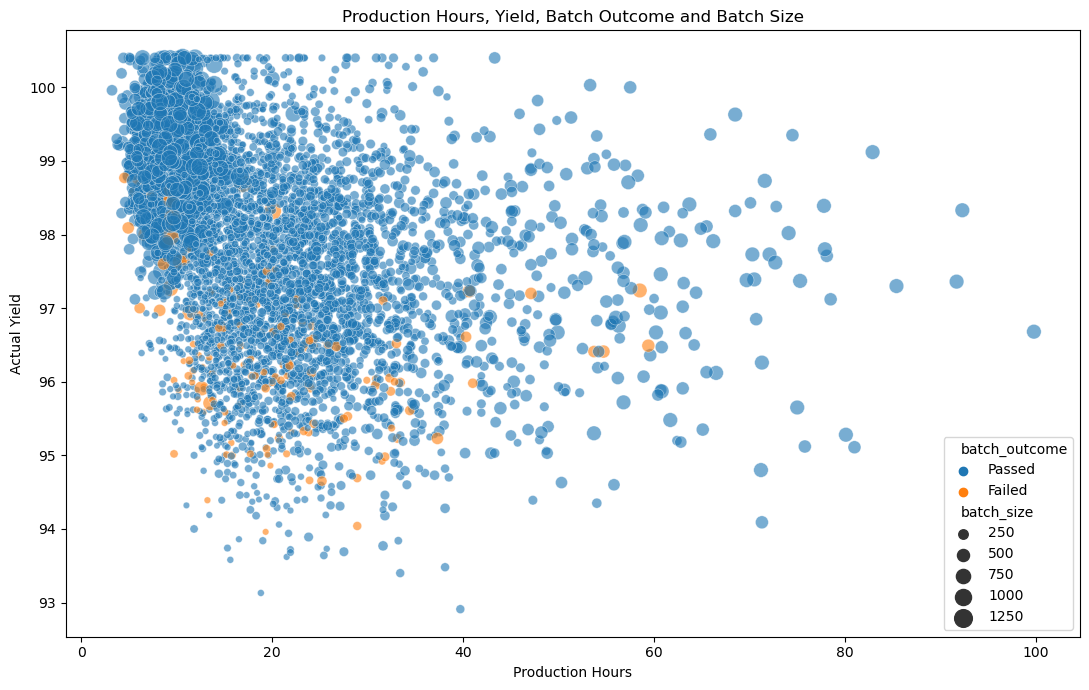

In [634]:
multi_plot = eda_data[["production_hours", "actual_yield", "batch_outcome", "batch_size"]].dropna().copy()  # columns for the chart
if len(multi_plot) > 5000:                                                  # large data makes plots slow
    multi_plot = multi_plot.sample(5000, random_state=42)                   # plot a random 5,000-row sample

plt.figure(figsize=(11, 7))                                                 # new chart
sns.scatterplot(data=multi_plot, x="production_hours", y="actual_yield",    # colour = outcome, size = batch size
                hue="batch_outcome", size="batch_size",
                sizes=(20, 180), alpha=0.6)
plt.title("Production Hours, Yield, Batch Outcome and Batch Size")          # chart title
plt.xlabel("Production Hours")                                              # x-axis label
plt.ylabel("Actual Yield")                                                  # y-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.** 

The chart combines the earlier two patterns: points drift **down** as production hours increase and **up** as batch size grows (bigger dots higher up), reflecting the −0.30 and +0.39 correlations and the product mix behind them. Failed batches (the 165 or so failed points in the 5,000-batch sample) are scattered through the whole cloud, only slightly lower on average (mean yield 96.6 against 97.7), and do not gather in any corner. No combination of run time, size and yield identifies failures on its own.

### C. Temperature, pressure, purity and yield

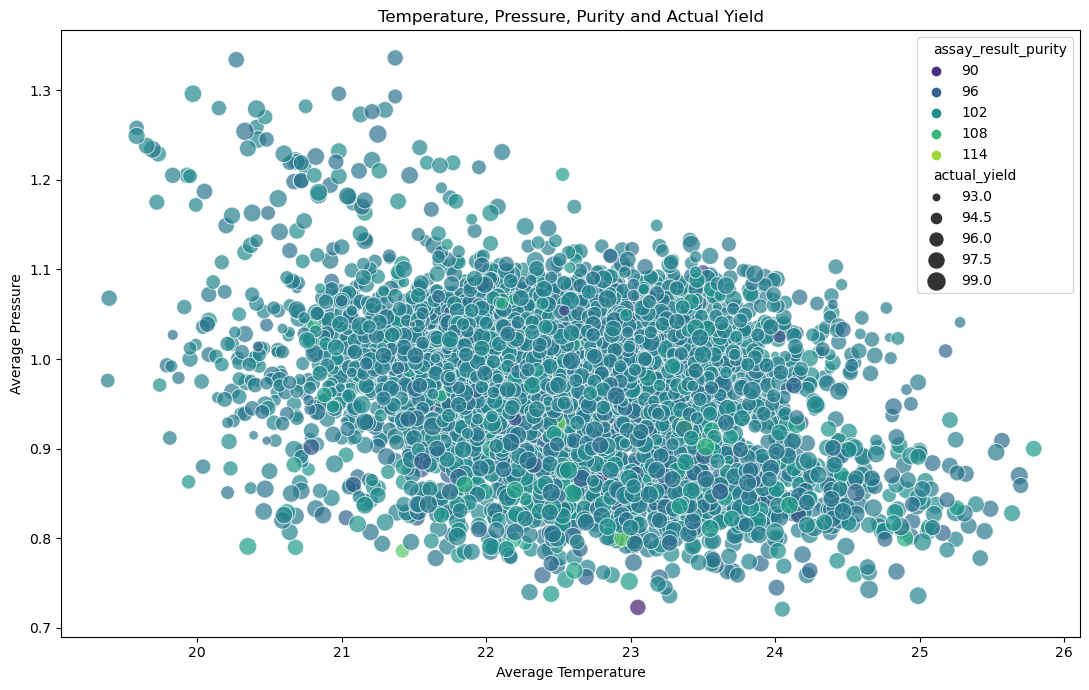

In [637]:
process_plot = eda_data[                                                    # process columns for the chart
    ["temp_avg", "pressure_avg", "assay_result_purity", "actual_yield"]
].dropna().copy()
if len(process_plot) > 5000:                                                # large data makes plots slow
    process_plot = process_plot.sample(5000, random_state=42)               # plot a random 5,000-row sample

plt.figure(figsize=(11, 7))                                                 # new chart
sns.scatterplot(data=process_plot, x="temp_avg", y="pressure_avg",          # colour = purity, size = yield
                hue="assay_result_purity", size="actual_yield",
                palette="viridis", sizes=(20, 180), alpha=0.7)
plt.title("Temperature, Pressure, Purity and Actual Yield")                 # chart title
plt.xlabel("Average Temperature")                                           # x-axis label
plt.ylabel("Average Pressure")                                              # y-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**

- Temperature and pressure are mildly negatively related (**r = −0.31**); pressure is centred at **0.97** (middle 50% between 0.92 and 1.03) and temperature at 22.5 °C. The dots form one compact cloud, so there are no separate operating regions.
- **Assay purity** averages **99.99** (standard deviation 1.65, range 85.4 to 119.1). Its colour is spread randomly across the cloud because purity is uncorrelated with temperature, pressure and yield (all |r| ≤ 0.012). Bubble size (yield) is largest at low pressure: mean yield is **98.8** when pressure is at or below 0.90 against **97.3 to 97.6** between 0.90 and 1.05.
- Failure rates are flat across temperature bands (3.0%, 3.1%, 3.1%, 3.2%, 3.3%) and humidity bands (3.0% to 3.4%), so no temperature or humidity "window" separates good from bad batches. A real operating window can only be set from approved limits and sensor data per product.

### D. Pairplot of selected production variables

The pairplot compares several numeric variables pairwise and shows each variable's distribution on the diagonal. A sample is used to keep rendering manageable.

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before opera

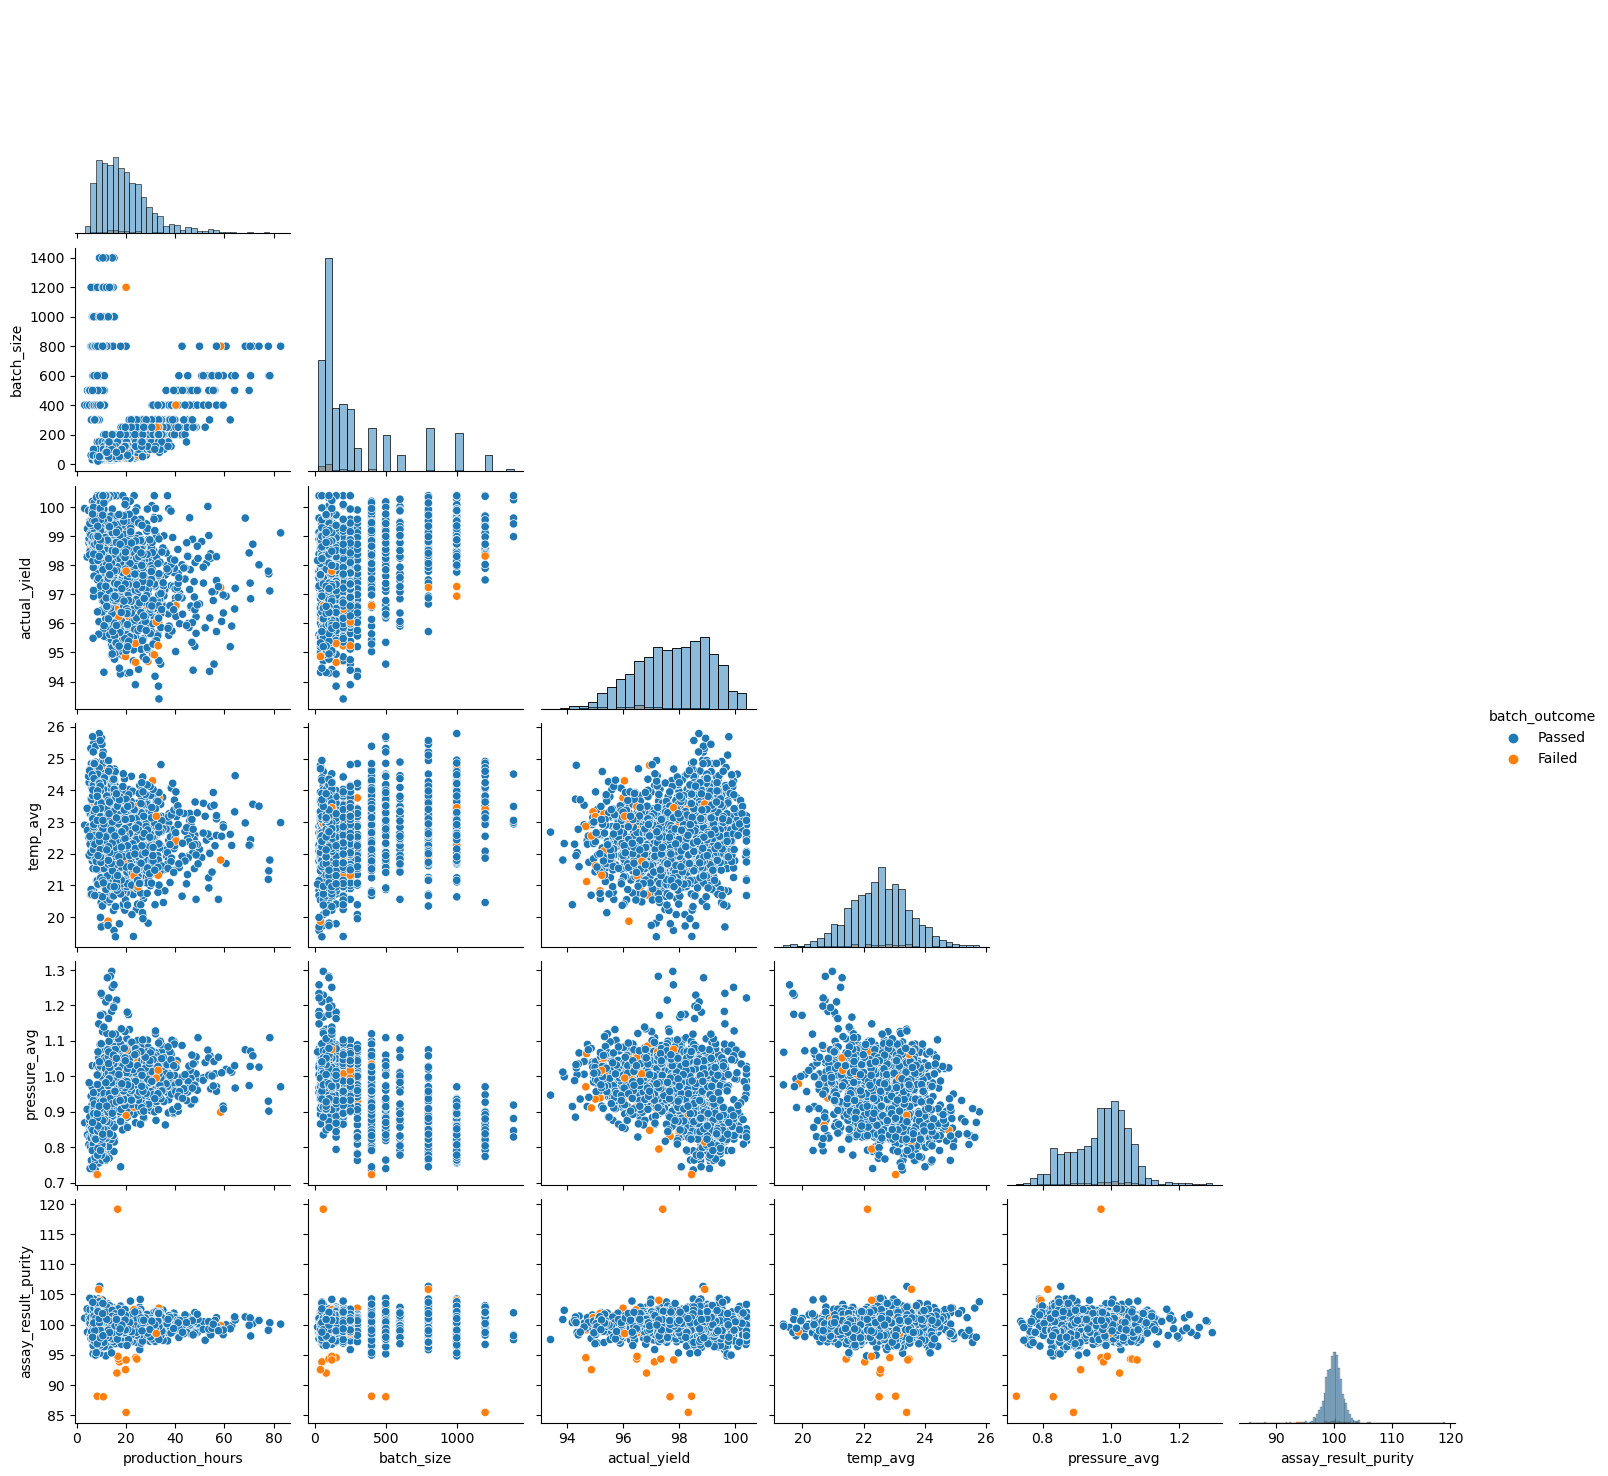

In [640]:
pair_columns = [                                                            # variables for the pair plot
    "production_hours", "batch_size", "actual_yield",
    "temp_avg", "pressure_avg", "assay_result_purity"
]
pair_columns = [col for col in pair_columns if col in eda_data.columns]     # keep only columns that exist

pair_data = eda_data[pair_columns + ["batch_outcome"]].dropna().copy()      # data for the pair plot
if len(pair_data) > 1500:                                                   # pair plots are slow on large data
    pair_data = pair_data.sample(1500, random_state=42)                     # plot a random 1,500-row sample

sns.pairplot(pair_data, vars=pair_columns, hue="batch_outcome",             # scatter of every pair of variables
             diag_kind="hist", corner=True)
plt.show()                                                                  # display the chart

**Interpretation.**

- **Diagonal:** production hours and batch size are skewed (long right tails), temperature and pressure are roughly bell-shaped and yield is slightly left-skewed.
- **Off-diagonal:** the clearest links are batch size with pressure (**−0.60**), production hours with pressure (**+0.36**), batch size with temperature (**+0.29**), batch size with yield (**+0.39**) and hours with yield (**−0.30**). Assay purity has essentially no relationship with any other variable (|r| ≤ 0.012), appearing as a shapeless band.
- **Colour:** the orange (Failed) points sit on top of the blue (Passed) points in every panel. No pair of variables separates the two groups, which foreshadows the weak prediction scores in Section 8. The plot uses 1,500 random batches, so about 47 failed points appear.

#### Sales and inventory

### E. Correlation heatmap of the numeric sales variables

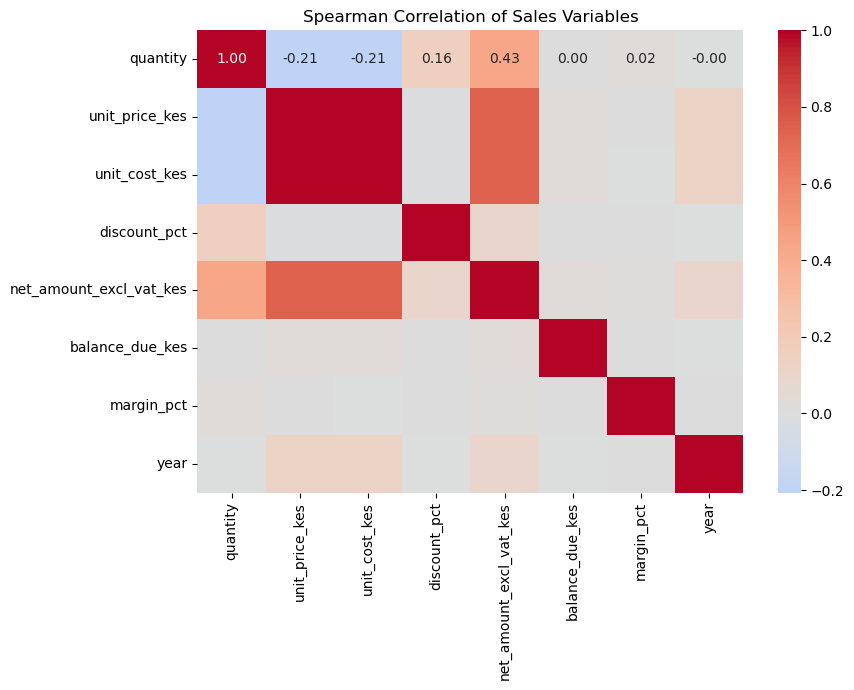

In [644]:
sales_numeric = valid_sales[["quantity", "unit_price_kes", "unit_cost_kes", "discount_pct", "net_amount_excl_vat_kes",
                             "balance_due_kes", "margin_pct", "year"]]      # numeric columns
plt.figure(figsize=(9, 7))                                                  # new chart
sns.heatmap(sales_numeric.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)  # rank correlations
plt.title("Spearman Correlation of Sales Variables")                        # chart title
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation (Spearman rank correlation).**
- **Unit price and unit cost move together perfectly (1.00)**, because cost is a fixed share of price; that is also why the margin is almost constant.
- **Net order value** rises with price (**0.75**) and quantity (**0.43**), as expected.
- **Price and quantity are mildly negative (−0.21):** expensive items are bought in smaller amounts.
- **Discount and quantity: 0.16**, the volume-discount effect.
- **Year** correlates weakly with price (**0.12**): prices rise over time, but order size and discount do not change by year.
- **Margin and balance due** are unrelated to everything else (about 0). Margins do not depend on order size, and unpaid balances depend on the payment method (5.5 I), not on what was bought.

### F. Net sales by branch and product category

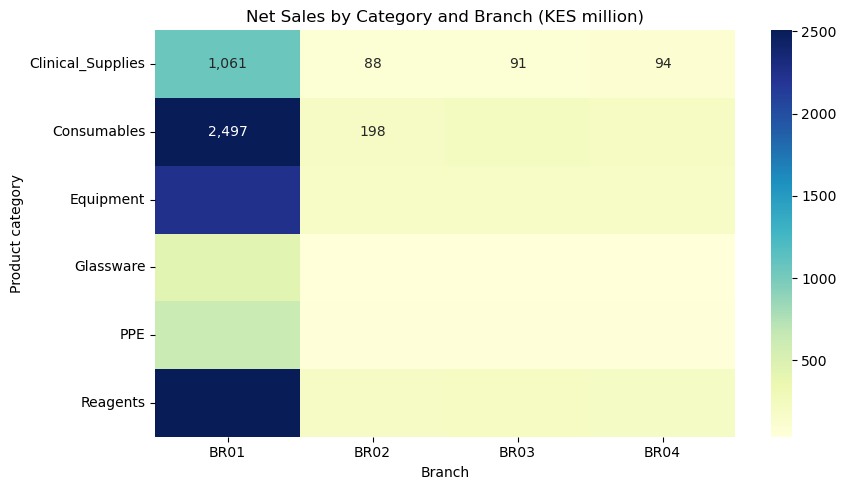

Share of each branch within every category (%):


branch_code,BR01,BR02,BR03,BR04
product_category,,,,
Clinical_Supplies,79.6,6.6,6.8,7.1
Consumables,79.4,6.3,7.4,6.9
Equipment,80.4,6.8,6.6,6.2
Glassware,78.5,7.4,6.4,7.6
PPE,80.3,6.1,7.1,6.5
Reagents,80.4,6.2,7.0,6.4


In [647]:
branch_cat = valid_sales.pivot_table(index="product_category", columns="branch_code",
                                     values="net_amount_excl_vat_kes", aggfunc="sum") / 1e6  # KES million
plt.figure(figsize=(9, 5))                                                  # new chart
sns.heatmap(branch_cat, annot=True, fmt=",.0f", cmap="YlGnBu")              # net sales per branch and category
plt.title("Net Sales by Category and Branch (KES million)")                 # chart title
plt.xlabel("Branch"); plt.ylabel("Product category")                        # axis labels
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
print("Share of each branch within every category (%):")                    # are branches alike?
display((branch_cat.div(branch_cat.sum(axis=1), axis=0) * 100).round(1))

**Interpretation.**
- **BR01 dominates every category**, with **78.5–80.4%** of each category's net sales. The other three branches take about 6–8% each.
- The branch mix is the **same in every category**: no branch specialises. A branch-level stock policy can use the company pattern scaled by branch size.
- The biggest cells are **BR01 Reagents (KES 2,506 m)**, **BR01 Consumables (KES 2,497 m)** and **BR01 Equipment (KES 2,237 m)**, which together are **62%** of all net sales.

### G. Pair plot of price, quantity, discount and value

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before opera

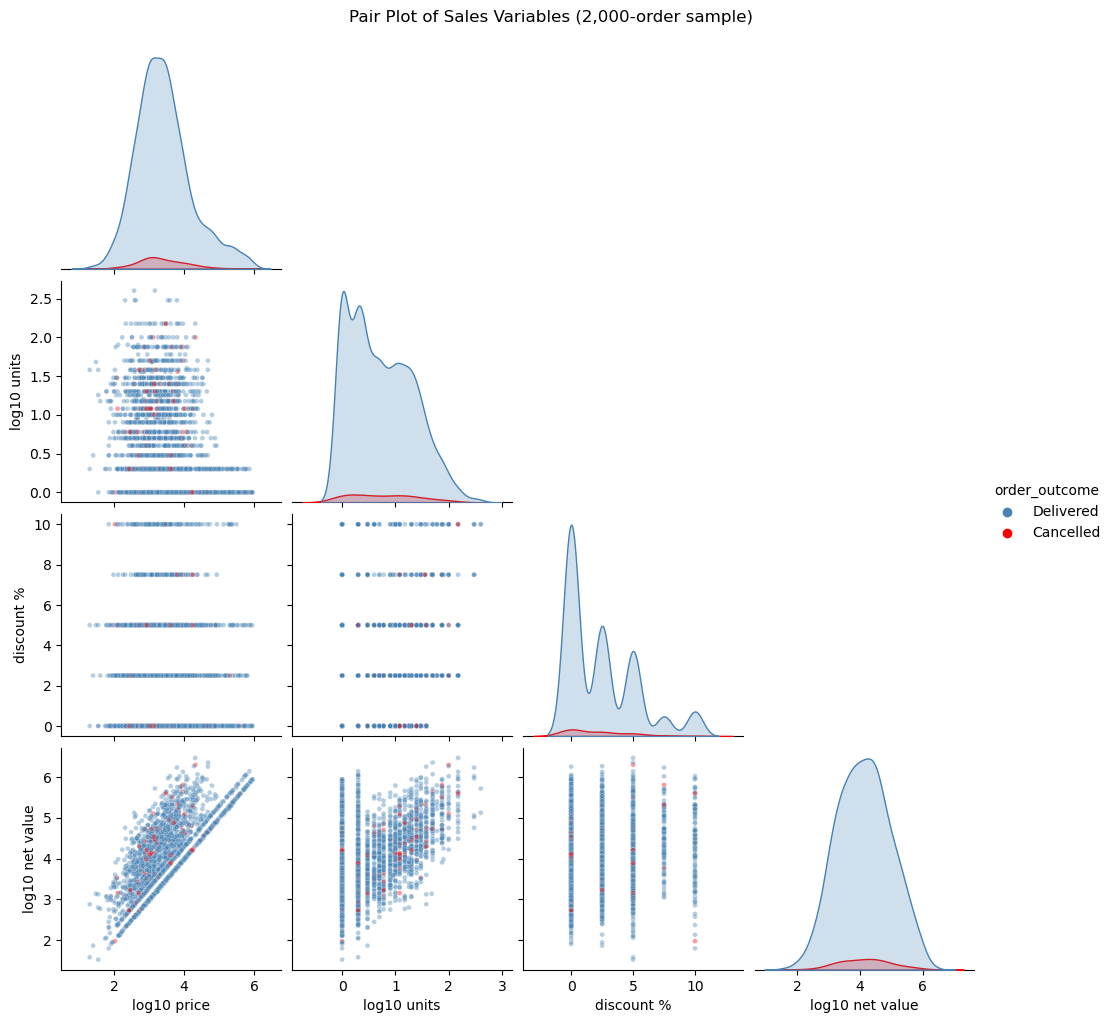

In [650]:
pair_data = sales_eda.sample(2000, random_state=RANDOM_STATE)[["unit_price_kes", "quantity", "discount_pct",
                                                                "net_amount_excl_vat_kes", "order_outcome"]].copy()  # sample
for col in ["unit_price_kes", "quantity", "net_amount_excl_vat_kes"]:       # log of the skewed values
    pair_data[col] = np.log10(pair_data[col])
pair_data.columns = ["log10 price", "log10 units", "discount %", "log10 net value", "order_outcome"]  # readable names
sns.pairplot(pair_data, hue="order_outcome", palette={"Delivered": "steelblue", "Cancelled": "red"},
             plot_kws={"alpha": 0.4, "s": 12}, corner=True)                 # every pair of variables
plt.suptitle("Pair Plot of Sales Variables (2,000-order sample)", y=1.02)   # overall title
plt.show()                                                                  # display the chart

**Interpretation.**
- **log price vs log net value** shows a tight band, and **log units vs log net value** a looser one: order value is driven mainly by **what** is bought, then by **how much**.
- Discount takes only five values, which shows as vertical stripes.
- **Cancelled orders (red)** overlap Delivered orders in every panel. As in 5.5 H, no combination of price, quantity or discount separates them.

## 5.7 Volume over time (all datasets)

### A. Production volume over time

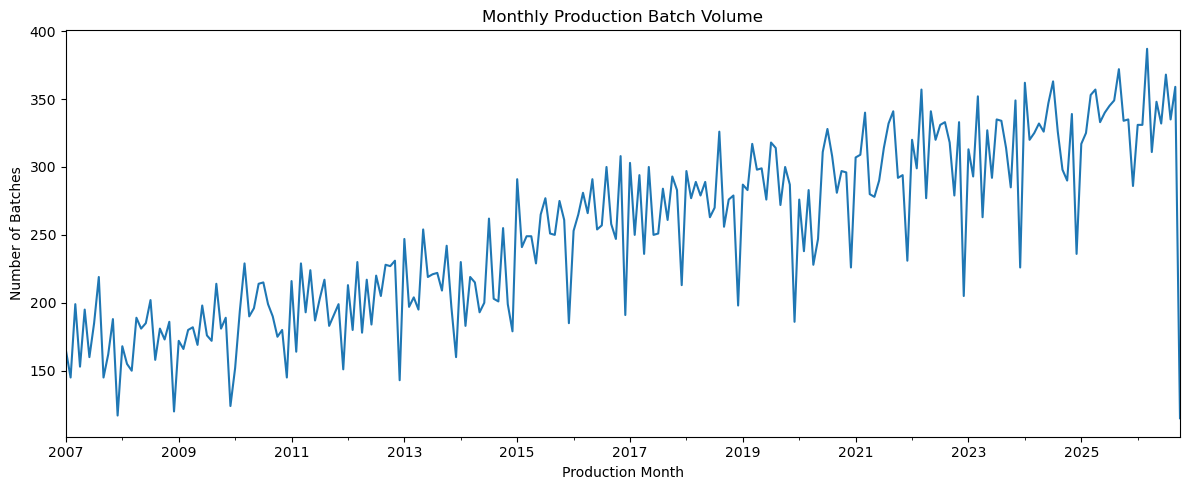

In [654]:
date_data = eda_data.dropna(subset=["production_start"]).copy()             # rows with a production date
date_data["production_start"] = pd.to_datetime(date_data["production_start"], errors="coerce")  # make sure dates are datetime
monthly_batches = (                                                         # number of batches per month
    date_data.dropna(subset=["production_start"])
    .set_index("production_start")
    .resample("MS")["batch_id"]
    .count()
)

plt.figure(figsize=(12, 5))                                                 # new chart
monthly_batches.plot()                                                      # line chart of monthly volume
plt.title("Monthly Production Batch Volume")                                # chart title
plt.xlabel("Production Month")                                              # x-axis label
plt.ylabel("Number of Batches")                                             # y-axis label
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**

- Output has **roughly doubled** over the period: from about **169 batches a month in 2007** (2,033 for the year) to **337 a month in 2025** (4,046 for the year). Growth is steady with a step up in 2015 (about 212 to 252 a month) and a peak of **387 batches in March 2026**.
- There is a clear **December dip**: December averages **185 batches** against about **257** in other months (about 28% lower), consistent with a year-end shutdown.
- The **final point (October 2026: 115 batches) is not a collapse.** The data stop on 9 October, so the month is incomplete. It should be ignored when judging trends, and the forecasting section drops it for the same reason.
- Rising volume matters for quality: the failure rate has risen over the same years (about 2.4% in 2007 to 2012, 2.8% in 2013 to 2018 and **3.7%** from 2019 to 2026), so busier years have also been worse years for quality.

### B. Sales, cancellations and stock received per year

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
orders,8085.00,8456.00,9494.00,9938.00,10711.00,11595.00,12698.00,13503.00,14563.00,15792.00,16908.00,18257.00
cancelled_%,4.23,4.26,4.13,3.73,3.85,3.96,4.25,4.25,4.09,3.84,4.15,3.79
avg_units_per_order,14.54,15.00,14.69,14.07,14.08,13.99,14.09,14.73,14.50,13.93,14.62,14.26
avg_discount_%,2.41,2.49,2.45,2.42,2.41,2.44,2.45,2.47,2.45,2.43,2.45,2.43
units_sold,112596.00,121468.00,133750.00,134579.00,145026.00,155797.00,171327.00,190461.00,202456.00,211510.00,236879.00,250392.00
units_received,336600.00,318400.00,344800.00,340200.00,366300.00,355100.00,328150.00,354700.00,347200.00,333100.00,351950.00,351050.00


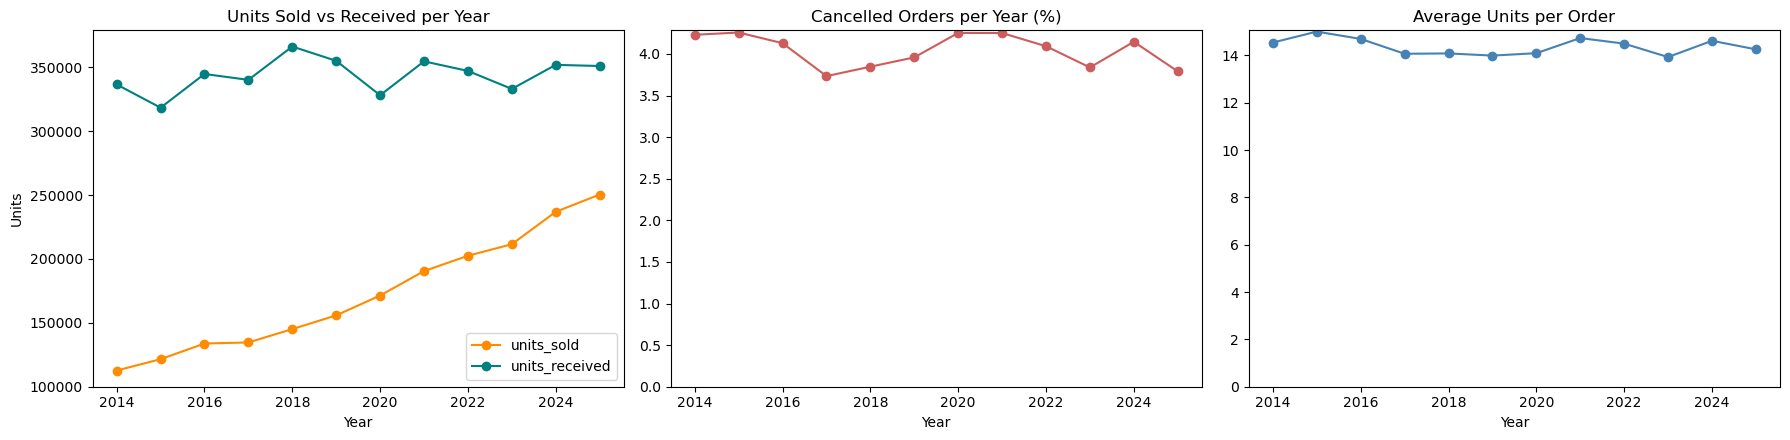

In [657]:
yearly_ops = pd.DataFrame({
    "orders": sales_eda.groupby("year").size(),                             # all orders
    "cancelled_%": sales_eda.groupby("year")["is_cancelled"].mean() * 100,  # cancellation rate
    "avg_units_per_order": valid_sales.groupby("year")["quantity"].mean(),  # order size
    "avg_discount_%": valid_sales.groupby("year")["discount_pct"].mean(),   # discount
    "units_sold": valid_sales.groupby("year")["quantity"].sum(),            # demand
    "units_received": receipts.groupby("year")["units"].sum()})             # supply
display(yearly_ops.round(2).T)                                              # one column per year

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))                           # three charts side by side
yearly_ops[["units_sold", "units_received"]].plot(ax=axes[0], marker="o", color=["darkorange", "teal"])  # demand vs supply
axes[0].set_title("Units Sold vs Received per Year"); axes[0].set_ylabel("Units")
yearly_ops["cancelled_%"].plot(ax=axes[1], marker="o", color="indianred")   # cancellation trend
axes[1].set_title("Cancelled Orders per Year (%)"); axes[1].set_ylim(0, None)
yearly_ops["avg_units_per_order"].plot(ax=axes[2], marker="o", color="steelblue")  # order-size trend
axes[2].set_title("Average Units per Order"); axes[2].set_ylim(0, None)
for ax in axes:                                                             # same x-axis label everywhere
    ax.set_xlabel("Year")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

**Interpretation.**
- **Orders grew steadily**, from **8,085 in 2014 to 18,257 in 2025** (2.3 times), and units sold from **112,596 to 250,392**.
- **Units received stayed flat** at about **318,000–366,000 a year**, above sales in every year. The gap narrows as sales grow (receipts were 3.0 times sales in 2014 and 1.4 times in 2025), but stock keeps building.
- **Cancellations** stay between **3.7% and 4.3%** every year; **order size** stays at about **14–15 units**; the **average discount** at about **2.4–2.5%**. Growth comes from **more orders**, not bigger orders or deeper discounts.
- **Implication:** purchasing has not adjusted to demand. Linking purchases to the demand forecast (Problem 7) and the reorder-point policy (Section 17) would stop the build-up.

### C. Monthly demand trend and seasonality

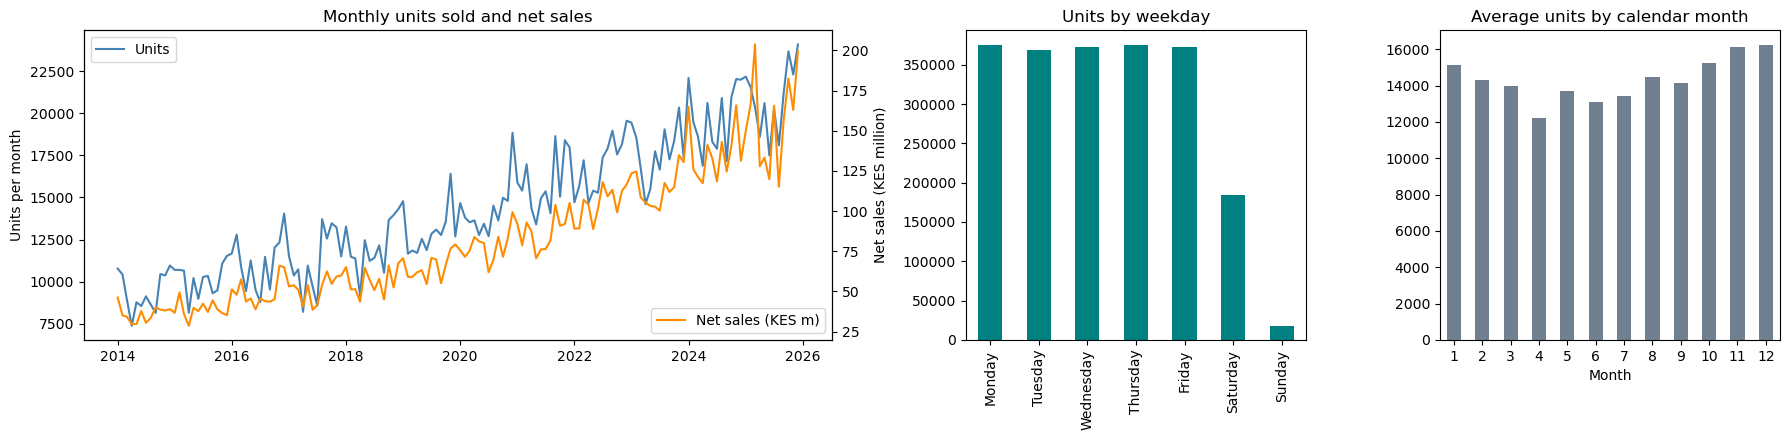

sale_date,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
units,112596.0,121468.0,133750.0,134579.0,145026.0,155797.0,171327.0,190461.0,202456.0,211510.0,236879.0,250392.0
net_sales_kes_m,433.0,463.0,595.0,624.0,673.0,787.0,938.0,1048.0,1249.0,1378.0,1627.0,1884.0
avg_price_kes,12855.0,12878.0,15682.0,14978.0,16436.0,17826.0,19518.0,19173.0,20933.0,22916.0,24262.0,25839.0


In [660]:
# Trend and seasonality of demand.
monthly_units = valid_sales.set_index("sale_date")["quantity"].resample("MS").sum()  # units sold per month
monthly_value = valid_sales.set_index("sale_date")["net_amount_excl_vat_kes"].resample("MS").sum() / 1e6  # KES million per month
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={"width_ratios": [2.2, 1, 1]})  # three charts
ax[0].plot(monthly_units, color="steelblue", label="Units")                 # units trend
ax[0].set_ylabel("Units per month"); ax[0].set_title("Monthly units sold and net sales")
ax2 = ax[0].twinx(); ax2.plot(monthly_value, color="darkorange", label="Net sales (KES m)")  # value trend on a second axis
ax2.set_ylabel("Net sales (KES million)")
ax[0].legend(loc="upper left"); ax2.legend(loc="lower right")               # legends
weekday = valid_sales.groupby(valid_sales["sale_date"].dt.day_name())["quantity"].sum()  # units per weekday
weekday.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).plot.bar(ax=ax[1], color="teal")
ax[1].set_title("Units by weekday"); ax[1].set_xlabel("")
season = monthly_units.groupby(monthly_units.index.month).mean()            # average units per calendar month
season.plot.bar(ax=ax[2], color="slategray", rot=0); ax[2].set_title("Average units by calendar month"); ax[2].set_xlabel("Month")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the charts

yearly = valid_sales.groupby(valid_sales["sale_date"].dt.year).agg(units=("quantity", "sum"), net_sales_kes_m=("net_amount_excl_vat_kes", lambda s: s.sum() / 1e6))
yearly["avg_price_kes"] = valid_sales.groupby(valid_sales["sale_date"].dt.year)["unit_price_kes"].mean()  # average price per year
display(yearly.round(0).T)                                                  # one column per year

### Explanation
- **Trend:**
  - Units sold rise every year, from **112,596 in 2014 to 250,392 in 2025** (2.2 times).
  - Net sales rise faster, from **KES 433 million to 1,884 million** (4.4 times), because the average price also doubled (KES 12,855 to 25,839).
  - Volume and value must be tracked separately, so forecasts are made in **units**.
- **Weekday:** about 370,000–375,000 units are sold on each weekday. Saturday is half that (184,000) and Sunday almost nothing (18,000), so branches mainly trade Monday to Friday.
- **Season:** demand is modestly seasonal. On average a calendar month sells about **16,000 units in November–December and January**, against about **12,200 in April**. The growth trend is stronger than the seasonal swing, so recent levels (rolling averages) matter more than the calendar month.

### D. All four datasets together, by month

Monthly table: (144, 8)


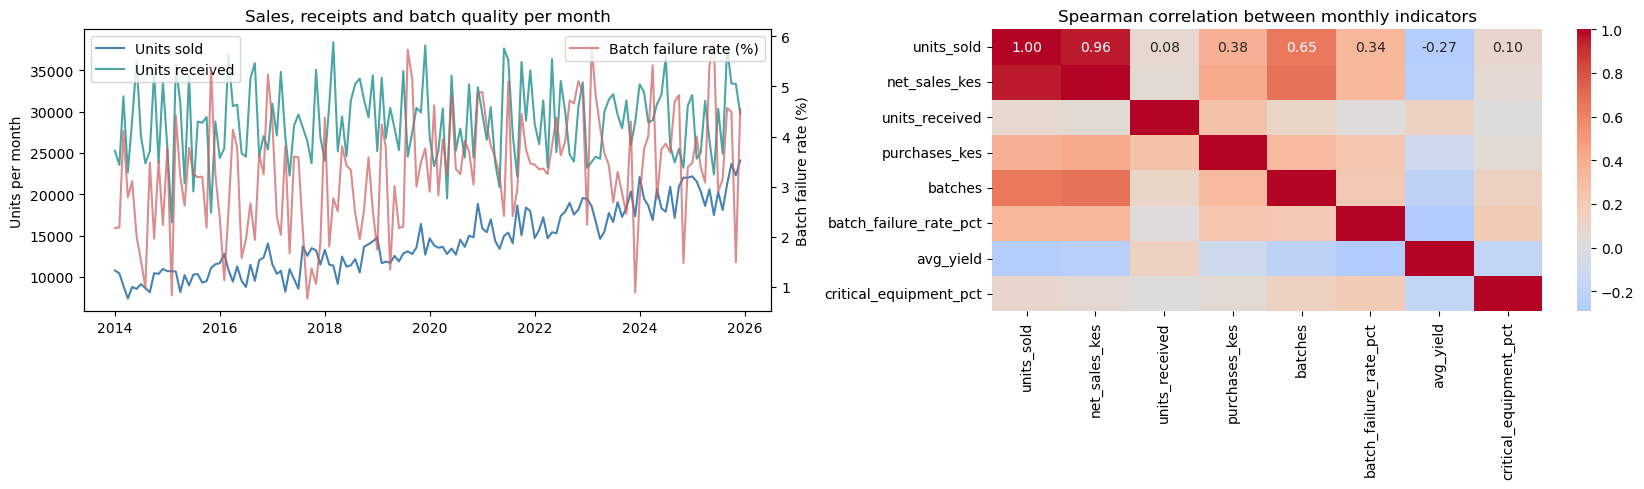

In [663]:
# All four datasets together, by month (pipeline 6.9): monthly totals from each table, joined on the month.
month = lambda dates: pd.to_datetime(dates, errors="coerce").dt.to_period("M")  # date -> calendar month
received = moves[moves["quantity_change"] > 0]                              # goods-received movements
monthly_ops = pd.DataFrame({
    "units_sold": valid_sales.groupby(month(valid_sales["sale_date"]))["quantity"].sum(),  # sales
    "net_sales_kes": valid_sales.groupby(month(valid_sales["sale_date"]))["net_amount_excl_vat_kes"].sum(),
    "units_received": received.groupby(month(received["movement_date"]))["quantity_change"].sum(),  # inventory
    "purchases_kes": received.groupby(month(received["movement_date"]))["movement_value_kes"].sum(),
    "batches": combined_data.groupby(month(combined_data["production_start"])).size(),  # production
    "batch_failure_rate_pct": 100 * (1 - combined_data.groupby(month(combined_data["production_start"]))["batch_passed"].mean()),
    "avg_yield": combined_data.groupby(month(combined_data["production_start"]))["actual_yield"].mean(),
    "critical_equipment_pct": 100 * combined_data["maintenance_status"].eq("Critical").groupby(month(combined_data["production_start"])).mean(),  # maintenance
}).dropna(subset=["units_sold"])                                            # keep the months that have sales (2014-2025)
print("Monthly table:", monthly_ops.shape)                                  # months x indicators

fig, ax = plt.subplots(1, 2, figsize=(17, 5))                               # two charts
t = monthly_ops.index.to_timestamp()                                        # months as dates for plotting
ax[0].plot(t, monthly_ops["units_sold"], color="steelblue", label="Units sold")  # sales volume
ax[0].plot(t, monthly_ops["units_received"], color="teal", alpha=0.7, label="Units received")  # receipts
ax[0].set_ylabel("Units per month"); ax[0].legend(loc="upper left")
axb = ax[0].twinx(); axb.plot(t, monthly_ops["batch_failure_rate_pct"], color="indianred", alpha=0.7, label="Batch failure rate (%)")
axb.set_ylabel("Batch failure rate (%)"); axb.legend(loc="upper right"); ax[0].set_title("Sales, receipts and batch quality per month")
sns.heatmap(monthly_ops.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1])  # correlations
ax[1].set_title("Spearman correlation between monthly indicators")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the charts

### Explanation
- **Sales:** units sold and net sales move almost in step (Spearman about **0.96**), because both follow the growth trend.
- **Receipts do not follow demand:**
  - Units received hardly correlate with units sold (about **0.08**), and purchase value only moderately (about **0.4**).
  - Yearly receipts stay roughly flat at about 330,000–370,000 units, while sales grow from 113,000 to 250,000.
  - Buying is not driven by demand, which is how the overstock in Section 5.8 built up. It is the strongest argument for the reorder-point policy in Section 17.
- **Production indicators** (batch failure rate, average yield, share of batches on Critical equipment): in the heatmap, values near 0 in their rows mean the production side moves independently of sales and stock; values above about ±0.3 would point to a month-level link worth investigating.
- **Caution:** there is no product-level key between batches and sales, so any link here is a **month-level association only**, not cause and effect.

## 5.8 Demand segments, inventory health and suppliers

### A. ABC-XYZ segmentation of products

XYZ,Z,Total
ABC,,
A,85,85
B,84,84
C,131,131
Total,300,300


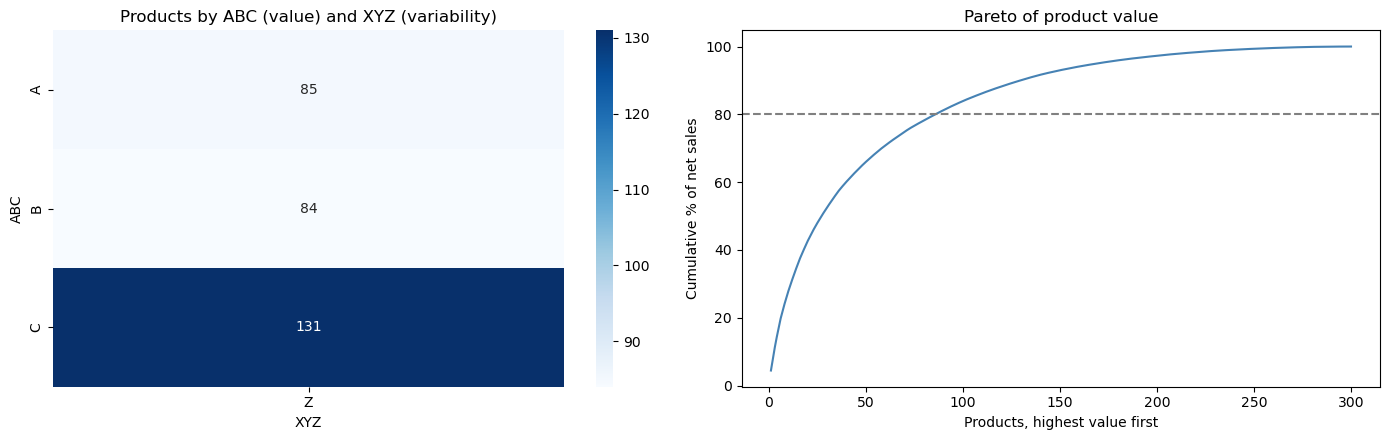

A items: 85 of 300 products give 80% of value; intermittent products: 300; median zero-sale weeks: 48%


In [667]:
# ABC-XYZ segmentation (pipeline 6.3): A/B/C by value, X/Y/Z by how variable weekly demand is.
weekly_product = (valid_sales.assign(week=valid_sales["sale_date"].dt.to_period("W-SUN").dt.start_time)
                  .groupby(["product_id", "week"])["quantity"].sum()
                  .unstack(fill_value=0))                                   # products x weeks, 0 where nothing sold
segments = pd.DataFrame({
    "category": valid_sales.groupby("product_id")["product_category"].first(),
    "net_sales_kes": valid_sales.groupby("product_id")["net_amount_excl_vat_kes"].sum(),
    "mean_weekly_units": weekly_product.mean(axis=1),
    "cv_weekly_units": weekly_product.std(axis=1) / weekly_product.mean(axis=1),  # coefficient of variation
    "zero_weeks_%": 100 * (weekly_product == 0).mean(axis=1)})             # share of weeks with no sale
segments = segments.sort_values("net_sales_kes", ascending=False)          # biggest earners first
cum_share = segments["net_sales_kes"].cumsum() / segments["net_sales_kes"].sum()  # running share of value
segments["ABC"] = np.where(cum_share <= 0.8, "A", np.where(cum_share <= 0.95, "B", "C"))  # 80 / 15 / 5 % of value
segments["XYZ"] = pd.cut(segments["cv_weekly_units"], [0, 0.5, 1.0, np.inf], labels=["X", "Y", "Z"])  # stable / variable / erratic
segments["intermittent"] = segments["zero_weeks_%"] > 30                    # sells in fewer than 70% of weeks

abc_xyz = pd.crosstab(segments["ABC"], segments["XYZ"], margins=True, margins_name="Total")  # products per segment
display(abc_xyz)                                                            # segment counts
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))                             # two charts
sns.heatmap(pd.crosstab(segments["ABC"], segments["XYZ"]), annot=True, fmt="d", cmap="Blues", ax=ax[0])  # heatmap of counts
ax[0].set_title("Products by ABC (value) and XYZ (variability)")
ax[1].plot(np.arange(1, len(cum_share) + 1), 100 * cum_share.values, color="steelblue")  # Pareto curve of value
ax[1].axhline(80, ls="--", color="gray"); ax[1].set_xlabel("Products, highest value first"); ax[1].set_ylabel("Cumulative % of net sales")
ax[1].set_title("Pareto of product value")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the charts
print(f"A items: {(segments['ABC'] == 'A').sum()} of {len(segments)} products give 80% of value; "
      f"intermittent products: {segments['intermittent'].sum()}; median zero-sale weeks: {segments['zero_weeks_%'].median():.0f}%")

### Explanation
- **ABC:**
  - **85 of the 300 products (28%)** produce **80% of net sales**; these are the A items.
  - The next 84 (B items) produce 15%, and the remaining 131 (C items) only 5%.
- **XYZ:**
  - **All 300 products are Z**: weekly demand is erratic, with a coefficient of variation above 1.
  - The median product sells nothing in **48% of weeks**, so every product is **intermittent**.
- **Implications for planning:**
  - A items deserve the closest stock control, because each stock-out or overstock costs the most money.
  - Week-by-week demand for a single product is close to random. Product-level forecast errors will be high, and safety stock matters more than point forecasts. This is why the pipeline suggests Croston-type methods for such items.

### B. Inventory health

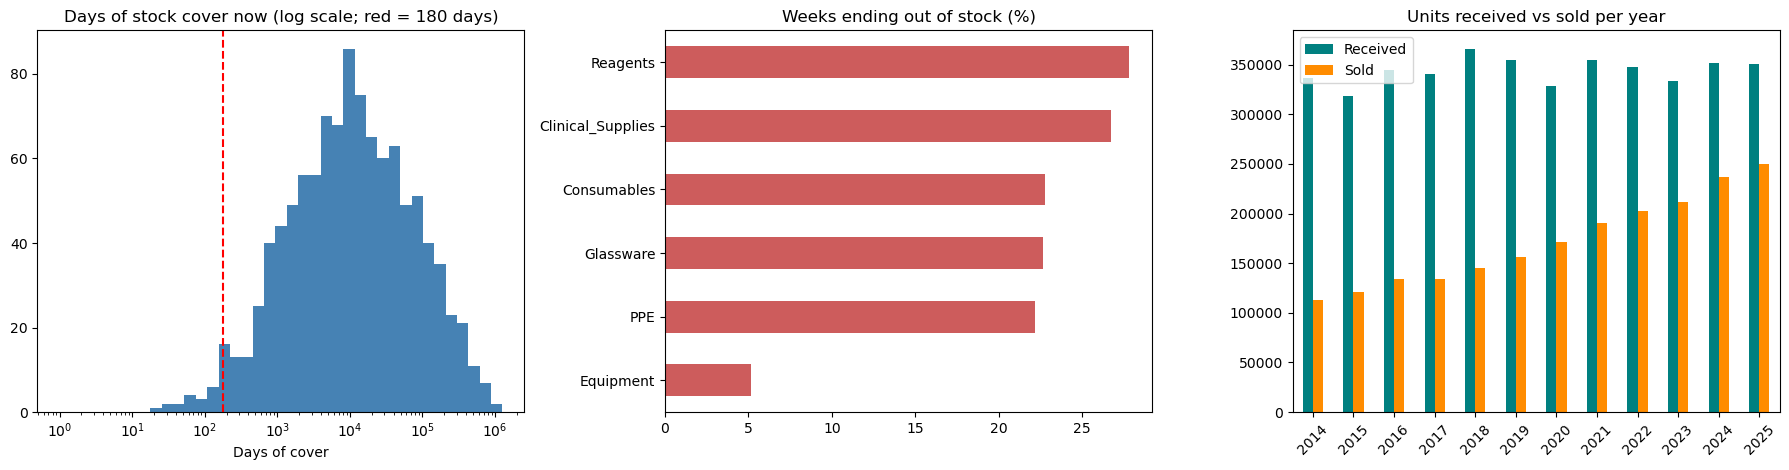

,stock_value_kes_m,median_days_of_cover,items_over_180_days,items_out_of_stock,weeks_out_of_stock_%
category,,,,,
Clinical_Supplies,1079.8,4775.0,166,22,26.8
Consumables,2239.1,5267.0,169,22,22.8
Equipment,57908.2,98828.1,200,0,5.1
Glassware,439.5,5142.1,168,26,22.7
PPE,502.6,4058.1,164,21,22.2
Reagents,2144.6,4183.5,165,31,27.8


Stock value held: KES 64,314 million; inventory turnover in 2025: 0.02 times a year


In [670]:
# Inventory health (pipeline 6.5): stock cover, stock-outs, turnover and receipts vs sales.
last_stock = moves.groupby(["branch_code", "product_id"]).agg(              # latest position per product and branch
    stock=("stock_on_hand", "last"), unit_cost=("unit_cost_kes", "last"))
last_year = moves[moves["movement_date"] > moves["movement_date"].max() - pd.Timedelta(days=365)]  # last 12 months
daily_demand = last_year[last_year["quantity_change"] < 0].groupby(["branch_code", "product_id"])["quantity_change"].sum().abs() / 365
last_stock["daily_demand"] = daily_demand.reindex(last_stock.index).fillna(0)  # average units sold per day
last_stock["days_of_cover"] = last_stock["stock"] / last_stock["daily_demand"].replace(0, np.nan)  # how long stock lasts
last_stock["category"] = last_stock.index.get_level_values("product_id").map(segments["category"])
last_stock["stock_value_kes_m"] = last_stock["stock"].clip(lower=0) * last_stock["unit_cost"] / 1e6  # value of stock held

weekly_end = (moves.assign(week=moves["movement_date"].dt.to_period("W-SUN").dt.start_time)
              .groupby(["branch_code", "product_id", "week"])["stock_on_hand"].last())  # stock at the end of each active week
stockout_by_cat = (weekly_end.le(0).groupby(weekly_end.index.get_level_values("product_id").map(segments["category"])).mean() * 100)

cogs = (-moves.loc[moves["quantity_change"] < 0, "movement_value_kes"]).groupby(moves["movement_date"].dt.year).sum()  # cost of goods sold
received = moves.loc[moves["quantity_change"] > 0].groupby(moves["movement_date"].dt.year)["quantity_change"].sum()  # units received
sold = -moves.loc[moves["quantity_change"] < 0].groupby(moves["movement_date"].dt.year)["quantity_change"].sum()  # units sold

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))                             # three charts
cover = last_stock["days_of_cover"][last_stock["days_of_cover"] > 0]     # items in stock with recent demand
ax[0].hist(cover, bins=np.logspace(0, np.log10(cover.max()), 40), color="steelblue")  # log-spaced bins: days to centuries
ax[0].set_xscale("log"); ax[0].axvline(180, ls="--", color="red")          # 180-day overstock line
ax[0].set_title("Days of stock cover now (log scale; red = 180 days)"); ax[0].set_xlabel("Days of cover")
stockout_by_cat.sort_values().plot.barh(ax=ax[1], color="indianred"); ax[1].set_title("Weeks ending out of stock (%)"); ax[1].set_ylabel("")
pd.DataFrame({"Received": received, "Sold": sold}).plot.bar(ax=ax[2], color=["teal", "darkorange"], rot=45)  # units in vs out
ax[2].set_title("Units received vs sold per year"); ax[2].set_xlabel("")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the charts

health = last_stock.groupby("category").agg(stock_value_kes_m=("stock_value_kes_m", "sum"), median_days_of_cover=("days_of_cover", "median"),
                                            items_over_180_days=("days_of_cover", lambda s: (s > 180).sum()), items_out_of_stock=("stock", lambda s: (s <= 0).sum()))
health["weeks_out_of_stock_%"] = stockout_by_cat                            # history of stock-outs
display(health.round(1))                                                    # inventory health per category
print(f"Stock value held: KES {last_stock['stock_value_kes_m'].sum():,.0f} million; "
      f"inventory turnover in 2025: {cogs.iloc[-1] / (last_stock['stock_value_kes_m'].sum() * 1e6):.2f} times a year")

### Explanation
- **Receipts vs sales:** receipts stay roughly flat at about 330,000–370,000 units a year, while sales grow from 113,000 to 250,000. Over the whole period the branches **received about twice what they sold**, so stock keeps building up.
- **Days of cover (end of 2025):** the median per category is enormous.

  | Category | Median days of cover |
  |---|---|
  | PPE | about 4,100 |
  | Reagents | about 4,200 |
  | Clinical supplies | about 4,800 |
  | Glassware | about 5,100 |
  | Consumables | about 5,300 |
  | Equipment | about 99,000 |

  That is 11–14 years of stock for most categories and **about 270 years for Equipment**. Almost every product–branch pair is past the 180-day line.
- **Value tied up:**
  - The stock is valued at about **KES 64 billion**, of which **KES 58 billion is Equipment**. Yearly net sales are about KES 1.9 billion.
  - Inventory turnover is about **0.02 times a year**.
- **Stock-outs:** even so, **22–28%** of weeks ended out of stock for the non-equipment categories (5% for Equipment), mostly in the early years.
- **Caution:** levels this extreme are not plausible for a real distributor. Recorded receipts appear to be **far larger than what was actually bought or held**, for example because of duplicated or unit-mismatched goods-received records, or a test data feed. **Confirm the goods-received records with the stores team** before acting on the overstock values. The patterns (overstock concentrated in Equipment, early stock-outs) are still useful, but the money values should be treated as indicative.

### C. Suppliers

,deliveries,units_received,purchases_kes_m,net_sales_kes_m,products,share_of_purchases_%
supplier_id,,,,,,
SUP_026,551,185350,11181.6,999.4,13,20.5
SUP_009,539,192150,6296.5,693.9,13,11.5
SUP_022,413,145150,5274.6,452.9,11,9.7
SUP_010,468,150650,4029.1,520.9,11,7.4
SUP_005,632,230900,3519.0,604.9,16,6.4
SUP_004,336,118650,2895.5,395.4,9,5.3
SUP_023,312,111200,2747.9,891.7,8,5.0
SUP_007,359,127250,2291.6,634.0,9,4.2
SUP_017,370,124650,1967.0,279.4,9,3.6


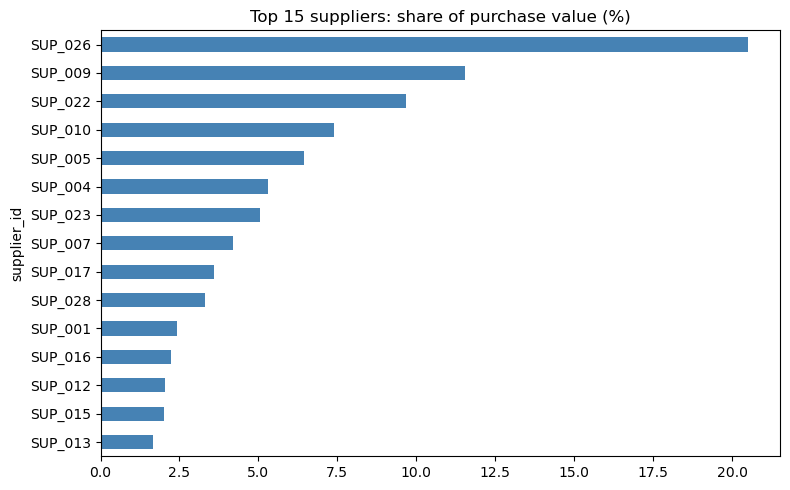

30 suppliers; top 5 = 56% of purchase value


In [673]:
# Suppliers (pipeline 6.6): share of receipts and of sales by supplier.
receipts = moves[moves["movement_type"] == "Goods_Received"]                # goods received only
supplier_view = pd.DataFrame({
    "deliveries": receipts.groupby("supplier_id").size(),                   # number of deliveries
    "units_received": receipts.groupby("supplier_id")["quantity_change"].sum(),
    "purchases_kes_m": receipts.groupby("supplier_id")["movement_value_kes"].sum() / 1e6,
    "net_sales_kes_m": valid_sales.groupby("supplier_id")["net_amount_excl_vat_kes"].sum() / 1e6,
    "products": valid_sales.groupby("supplier_id")["product_id"].nunique()}).sort_values("purchases_kes_m", ascending=False)
supplier_view["share_of_purchases_%"] = 100 * supplier_view["purchases_kes_m"] / supplier_view["purchases_kes_m"].sum()
display(supplier_view.head(10).round(1))                                    # top 10 suppliers by purchases
supplier_view["share_of_purchases_%"].head(15).sort_values().plot.barh(figsize=(8, 5), color="steelblue",
                                                                      title="Top 15 suppliers: share of purchase value (%)")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart
print(f"{len(supplier_view)} suppliers; top 5 = {supplier_view['share_of_purchases_%'].head(5).sum():.0f}% of purchase value")

### Explanation
- **Concentration:**
  - **30 suppliers** deliver all goods, and the **top five supply 56% of purchase value**.
  - **SUP_026** alone supplies **20.5%**, followed by SUP_009 (11.5%) and SUP_022 (9.7%).
  - A disruption at SUP_026 would affect 13 products.
- **Lead time and reliability:** pipeline step 6.6 asks for supplier lead time, fill rate and reliability. The files record only the delivery date, not the order date or quantity ordered, so **lead time and fill rate cannot be measured**. The reorder-point section uses a stated lead-time assumption instead.

## 5.9 EDA findings and operational interpretation

In [676]:
# Create readable batch outcome labels from the batch_passed field.
combined_data["batch_outcome"] = combined_data["batch_passed"].apply(       # add a Passed / Failed / Unknown label
    lambda x: "Passed" if str(x).strip().lower() in ["1", "1.0", "true", "pass", "passed"]
    else "Failed" if str(x).strip().lower() in ["0", "0.0", "false", "fail", "failed"]
    else "Unknown"
)

# Show the number of rows in each outcome category, including missing values.
print(combined_data["batch_outcome"].value_counts(dropna=False))            # count batches per outcome

# Print a separator and report heading for the EDA summary.
print("=" * 55)                                                             # separator line
print("PHARMACEUTICAL OPERATIONS INTELLIGENCE SYSTEM")                      # report heading
print("EXPLORATORY DATA ANALYSIS FINDINGS")                                 # report sub-heading
print("=" * 55)                                                             # separator line

# Summarize actual yield if that field exists.
if "actual_yield" in combined_data.columns:                                 # only if the yield column exists
    print("\n1. PRODUCTION YIELD")                                          # section heading
    print("Average yield:", round(combined_data["actual_yield"].mean(), 2))  # mean yield
    print("Median yield:", round(combined_data["actual_yield"].median(), 2))  # median yield
    print("Minimum yield:", round(combined_data["actual_yield"].min(), 2))  # lowest yield
    print("Maximum yield:", round(combined_data["actual_yield"].max(), 2))  # highest yield

# Display batch outcome counts and calculate the percentage that failed.
print("\n2. BATCH QUALITY")                                                 # section heading
print(combined_data["batch_outcome"].value_counts(dropna=False))            # count batches per outcome

known_outcomes = combined_data["batch_outcome"].dropna()                    # outcomes that are known
if len(known_outcomes) > 0:                                                 # only if there are outcomes
    failure_rate = (known_outcomes == "Failed").mean() * 100                # percentage of failed batches
    print(f"Overall batch failure rate: {failure_rate:.2f}%")               # report the failure rate

# Examine numeric correlations with actual_yield.
print("\n3. FACTORS ASSOCIATED WITH YIELD")                                 # section heading

if "actual_yield" in combined_data.columns:                                 # only if the yield column exists
    numeric_data = combined_data.select_dtypes(include="number")            # numeric columns only
    correlations = numeric_data.corr()["actual_yield"].drop(                # correlation of every column with yield
        labels=["actual_yield"], errors="ignore"
    ).dropna()

    # Print the three largest positive and negative correlations, when available.
    if len(correlations) > 0:                                               # only if correlations were computed
        print("Strongest positive correlations:")                           # heading
        print(correlations.sort_values(ascending=False).head(3))            # three strongest positive

        print("\nStrongest negative correlations:")                         # heading
        print(correlations.sort_values().head(3))                           # three strongest negative
    else:                                                                   # otherwise
        print("Insufficient numerical data to calculate correlations.")     # explain why none are shown

# Summarize maintenance categories and failure rates by category.
print("\n4. MAINTENANCE STATUS")                                            # section heading

# Check maintenance status
if "maintenance_status" in combined_data.columns:                           # only if the status column exists

    print("Maintenance Status Summary:")                                    # heading
    print(combined_data["maintenance_status"].value_counts(dropna=False))   # batches per maintenance status

    # Create batch outcome labels
    maintenance_data = combined_data[                                       # status and pass/fail columns
        ["maintenance_status", "batch_passed"]
    ].dropna().copy()

    maintenance_data["batch_outcome"] = maintenance_data["batch_passed"].map({  # 1 -> Passed, 0 -> Failed
        1: "Passed",
        0: "Failed"
    })

    # Calculate failure rate by maintenance status
    maintenance_summary = pd.crosstab(                                      # % passed / failed within each status
        maintenance_data["maintenance_status"],
        maintenance_data["batch_outcome"],
        normalize="index"
    ) * 100

    if "Failed" in maintenance_summary.columns:                             # only if there are failures
        print("\nFailure rate by maintenance status (%):")                  # heading
        print(maintenance_summary["Failed"].round(2))                       # failure rate per status

else:                                                                       # otherwise
    print("Maintenance status is not available in combined_data.")          # explain why it is skipped

print("\nEDA summary completed.")                                           # confirm the summary finished

batch_outcome
Passed    58125
Failed     1875
Name: count, dtype: int64
PHARMACEUTICAL OPERATIONS INTELLIGENCE SYSTEM
EXPLORATORY DATA ANALYSIS FINDINGS

1. PRODUCTION YIELD
Average yield: 97.71
Median yield: 97.77
Minimum yield: 91.41
Maximum yield: 100.4

2. BATCH QUALITY
batch_outcome
Passed    58125
Failed     1875
Name: count, dtype: int64
Overall batch failure rate: 3.12%

3. FACTORS ASSOCIATED WITH YIELD
Strongest positive correlations:
target_yield    0.504756
batch_size      0.394001
humidity_avg    0.261623
Name: actual_yield, dtype: float64

Strongest negative correlations:
pressure_avg           -0.326155
production_hours       -0.301432
dissolution_time_min   -0.147206
Name: actual_yield, dtype: float64

4. MAINTENANCE STATUS
Maintenance Status Summary:
maintenance_status
Current     54240
Due Soon     5284
Critical      476
Name: count, dtype: Int64

Failure rate by maintenance status (%):
maintenance_status
Critical    6.93
Current     3.11
Due Soon    2.93
Name: Failed,

### Explanation

- **Yield:** mean **97.71**, median **97.77**, minimum **91.41**, maximum **100.4**. The mean is slightly below the median because of a thin tail of poor batches.
- **Batch outcomes:** 58,125 passed and 1,875 failed, an overall **failure rate of 3.12%**. Because failures are a small minority, precision, recall, F1 and PR-AUC are used, not accuracy alone.
- **Correlations with yield:** strongest positive are target yield (**+0.50**), batch size (**+0.39**) and humidity (**+0.26**); strongest negative are pressure (**−0.33**), production hours (**−0.30**) and dissolution time (**−0.15**). Several of these reflect product mix rather than direct causes.
- **Maintenance status:** 54,240 batches on Current equipment (90.4%), 5,284 Due Soon (8.8%) and 476 Critical (0.8%). Failure rates are **6.93% for Critical**, 3.11% for Current and 2.93% for Due Soon, so Critical equipment carries about 2.2 times the failure risk.
- **Operational follow-up:** review Critical equipment first, look at Oral Solids (lowest median yield, most failures), and check the yields above 100 with production. Confirm all findings with production, quality and maintenance staff.

- **Sales (Sections 5.3 to 5.7):** 143,955 delivered orders (4.0% cancelled, evenly across branches, categories and payment methods). BR01 takes 80% of orders. Expensive items sell in smaller quantities, and larger orders get larger discounts (median 30 units at 7.5%). All KES 1,804 million of unpaid balances sit on credit-account orders.
- **Inventory (Sections 5.3 to 5.8):** 4.13 million units received against 2.07 million sold. Deliveries come in fixed lots of 50 to 1,000 units and stay flat at about 330,000–370,000 a year, while sales doubled. Equipment received 22 times what it sold.

**Scope note:** the current files support manufacturing yield, batch quality, process conditions and equipment-maintenance analysis. Sales and inventory are explored alongside production in every step (Sections 5.1 to 5.8). None of the files contain patient-level activity, employee performance or expiry dates, so those areas cannot be concluded.

**Sales and inventory findings**

| Question | Finding |
|---|---|
| What sells? | Six categories with about 25,000 orders each. Value comes from Consumables (27%), Reagents (27%) and Equipment (24%). |
| Where? | **BR01** earns 80% of net sales. |
| Trend | Units sold rose 2.2 times from 2014 to 2025, and net sales 4.4 times, as prices doubled. |
| Pattern | Weekday trading; modest seasonal peak in November–January; **all products have intermittent demand**. |
| Value concentration | 85 of 300 products (A items) give 80% of net sales. |
| Stock | Recorded receipts are about twice sales, giving **extreme overstock** (KES 64 billion, mostly Equipment), which needs checking with the stores team. Stock-out weeks still occur, mainly early on. |
| Suppliers | Top five supply 56% of purchase value. Lead times cannot be measured. |
| Data gaps | No expiry dates, opening stock, order dates or lead times. |

# 6. Feature Engineering

Feature engineering creates or transforms input variables so that analysis and machine-learning models can use relevant patterns in the data.

This section will create calendar features, quality-related indicators, and maintenance-related features from the available production and maintenance fields. It also checks which fields required by the wider project pipeline are missing.

Before modeling, we verify that each feature would be available at the time a prediction is meant to be made. Variables measured only after a batch is completed may leak the outcome into a prediction task.

**Step 1: Create a copy of the data and convert date columns**

In [681]:
clean_data = combined_data.copy()                                           # working copy for feature engineering

**Step 2: Create calendar features**

In [683]:
if 'production_start' in clean_data.columns:                                # only if the date column exists
    date = clean_data['production_start']                                   # production date
    clean_data['production_year'] = date.dt.year                            # year
    clean_data['production_month'] = date.dt.month                          # month (1-12)
    clean_data['production_week'] = date.dt.isocalendar().week              # ISO week number
    clean_data['production_weekday'] = date.dt.dayofweek                    # weekday (0 = Monday)
    clean_data['production_month_end'] = date.dt.is_month_end.astype('int8')  # 1 on the last day of the month
    clean_data['production_quarter'] = date.dt.quarter                      # quarter (1-4)
print('Calendar features created.')                                         # confirm the step finished

Calendar features created.


### Interpretation

`Calendar features created.` confirms that the cell ran; it does not display the values of the new columns. The code adds year, month, ISO week number, weekday, month-end indicator, and quarter based on `production_start`.

These fields let later analysis group batches by time period. For example, `production_weekday` uses Monday = 0 through Sunday = 6, and `production_month_end` uses 1 for the last calendar day of the month and 0 otherwise. They describe the calendar, not the cause of a production result.

Also these hels us determine;

- Compare batch pass rates across months.
- Identify seasonal production patterns.
- Analyze production performance by weekday or quarter.
- Investigate whether production outcomes vary at month-end.

**Step 3: Create quality features**

In [687]:
# Temperature and pressure variability
for col in ["temp_variance", "pressure_variance"]:                          # the two variability columns
    if col in clean_data:                                                   # only if the column exists
        clean_data[col + "_high"] = (                                       # 1 when variability is above its average
            clean_data[col] > clean_data[col].mean()
        ).astype("int8")

# Yield difference
if {"actual_yield", "target_yield"}.issubset(clean_data.columns):           # only if both yield columns exist
    clean_data["yield_difference"] = (                                      # actual minus target yield
        clean_data["actual_yield"] - clean_data["target_yield"]
    )

# Missing-measurement flags
for col in [                                                                # measurement columns
    "temp_avg", "temp_variance", "pressure_avg",
    "pressure_variance", "humidity_avg",
    "assay_result_purity", "impurity_level",
    "dissolution_time_min"
]:
    if col in clean_data:                                                   # only if the column exists
        clean_data[col + "_missing"] = clean_data[col].isna().astype("int8")  # 1 when the measurement is missing

print("Quality features created.")                                          # confirm the step finished

Quality features created.


# Explanation

This cell creates quality-related features to help investigate possible relationships between process conditions, yield, and batch quality.

**1. Temperature and pressure variability**

For each available variance column, it marks values above that column's **mean** as `1`; values at or below the mean are marked `0`. These are relative flags for this dataset, not validated manufacturing safety limits.

**2. Yield difference**

`yield_difference` is calculated as actual yield minus target yield. Positive values mean actual yield is above target; negative values mean it is below target; zero means the values match.

**3. Missing-measurement flags**

For each available measurement, the new flag is `1` when the value is missing and `0` when it is present. Create these flags before imputing missing values if you want them to represent the original missingness.

**Prediction caution:** Actual yield and post-production quality measurements may not be available before a batch is produced. Exclude them when building a model intended to predict batch success in advance.

**Step 4: Create maintenance features**

In [691]:
# Maintenance urgency
if "maintenance_status" in clean_data:                                      # only if the status column exists
    clean_data["maintenance_urgency"] = (                                   # Current = 0, Due Soon = 1, Critical = 2
        clean_data["maintenance_status"]
        .astype("string").str.strip().str.lower()
        .map({"current": 0, "due soon": 1, "critical": 2})
    )

# Equipment age group
if "equipment_age_days" in clean_data:                                      # only if the age column exists
    clean_data["equipment_age_group"] = pd.cut(                             # New / Medium Age / Old
        clean_data["equipment_age_days"],
        bins=[-1, 365, 1825, float("inf")],
        labels=["New", "Medium Age", "Old"]
    )

# Days since maintenance

# Convert maintenance_production_date column to datetime
clean_data["maintenance_production_date"] = pd.to_datetime(                 # convert to datetime
    clean_data["maintenance_production_date"], errors="coerce"
)
# Calculate days since maintenance
clean_data["days_since_maintenance"] = (                                    # days between maintenance and production
    clean_data["production_start"]
    - clean_data["maintenance_production_date"]
).dt.days

print("Maintenance features created.")                                      # confirm the step finished

Maintenance features created.


# Explanation

**1. Maintenance urgency:** `Current` = 0, `Due Soon` = 1, `Critical` = 2.

**2. Equipment age group:** `New` (up to 365 days), `Medium Age` (366–1,825 days) and `Old` (more than 1,825 days).

**3. Days since maintenance:** the preview in Step 7 shows **negative values (−30, −57)**.
- They are a **date-format problem**, not real gaps. `maintenance_production_date` is the batch's production date written day-first (`02/01/2007` = 2 January 2007), but pandas reads it month-first (1 February 2007). 2 January minus 1 February gives −30 days.
- Read correctly (`dayfirst=True`), the two dates are the same, so the difference would be **0 for every batch** and the feature carries no information.
- The real time since service is already in `maintenance_days_ago` (average 46 days).
- Treat `days_since_maintenance` as unreliable. Before deployment, drop it or fix the date format.

**Prediction caution:** only use maintenance information that would have been known at the prediction time.

**Step 5: Check which proposal fields are available across the four datasets**

In [695]:
# Check which proposal fields exist in any of the cleaned tables.
pipeline_fields = {"Demand and inventory": ["sale_date", "quantity", "unit_price_kes", "unit_cost_kes", "movement_type", "expiry_date", "lead_time_days", "opening_stock"],
                   "Quality and compliance": ["batch_passed", "rejection_reason", "deviation_type", "audit_score", "capa_status"],
                   "Maintenance": ["maintenance_status", "maintenance_days_ago", "failure_date", "downtime_hours", "maintenance_type"]}
all_columns = set(clean_data.columns) | set(sales_data.columns) | set(inventory_data.columns)  # every field we have
for module, fields in pipeline_fields.items():                             # one proposal module at a time
    print(f"{module}\n  Available: {[f for f in fields if f in all_columns]}\n  Missing:   {[f for f in fields if f not in all_columns]}")

Demand and inventory
  Available: ['sale_date', 'quantity', 'unit_price_kes', 'unit_cost_kes', 'movement_type']
  Missing:   ['expiry_date', 'lead_time_days', 'opening_stock']
Quality and compliance
  Available: ['batch_passed', 'rejection_reason']
  Missing:   ['deviation_type', 'audit_score', 'capa_status']
Maintenance
  Available: ['maintenance_status', 'maintenance_days_ago']
  Missing:   ['failure_date', 'downtime_hours', 'maintenance_type']


### Explanation
- **Demand and inventory:**
  - **Available:** sale date, quantity, price, cost and movement type, so demand forecasting, stock-outs and reorder points can be built (Problems 7 and 8, Section 17).
  - **Missing:** expiry dates, lead times and opening stock. Expiry risk and the back-test cannot be scored, and reorder points use an assumed lead time.
- **Quality and compliance:**
  - **Available:** batch pass/fail and rejection reasons (Problems 1, 2, 4, 5 and 6).
  - **Missing:** deviation types, audit scores and CAPA status.
- **Maintenance:**
  - **Available:** maintenance status and days since service (Problem 3).
  - **Missing:** failure dates, downtime hours and maintenance type, so MTBF, MTTR and failure prediction cannot be calculated.

Missing fields are not invented; they are listed as data to collect in Section 21.

**Step 6: Prepare features for modeling**

The code in the next cell:

1. Defines the target `batch_failed` (1 = failed, 0 = passed) from `batch_passed`. Following the proposal's compliance-risk classification, the model flags batches at risk of failing, so the rare and costly outcome, a failed batch, is the positive class that recall, precision and F1 measure.
2. Removes rows where the target is missing.
3. Excludes the target, identifiers, and selected outcome-related fields from the input features.
4. Separates numerical and categorical columns.
5. creates a random 80/20 train-test split while preserving the pass/fail proportions.
6. Fits missing-value imputation and one-hot encoding on the training data, then applies the same transformations to the test data.

Fitting preprocessing on training data only helps prevent information from the test set leaking into model preparation. Review the excluded fields carefully to ensure that all remaining predictors are available at the intended prediction time.

In [698]:
# Define the column the classifier will try to predict.
# As in the proposal, the classifier flags batches at risk, so the target is "batch failed".
target = "batch_failed"                                                     # column to predict: 1 = failed, 0 = passed

# Remove records where the outcome is unknown, then create the target.
model_data = clean_data.dropna(subset=["batch_passed"]).copy()              # rows with a known outcome
model_data[target] = (model_data["batch_passed"] == 0).astype(int)         # 1 = failed, 0 = passed

# Identify columns that should not be used as input features.
# This excludes the target, identifiers, and fields that may reveal the outcome.
exclude = [                                                                 # columns not used as predictors (IDs, outcome, leakage)
    "batch_failed", "batch_passed", "batch_outcome",
    "batch_id", "equipment_id", "rejection_reason",
    "actual_yield", "yield_difference",
    "assay_result_purity", "impurity_level",
    "dissolution_time_min", "production_rate",
    "production_start", "maintenance_production_date"
]

# Build X (input features) and y (target labels).
X = model_data.drop(                                                        # predictor columns
    columns=[col for col in exclude if col in model_data.columns]
)
y = model_data[target]                                                      # target: 1 = failed, 0 = passed

# Remove any remaining raw datetime columns from the feature matrix.
datetime_columns = X.select_dtypes(                                         # remaining raw date columns
    include=["datetime", "datetimetz"]
).columns.tolist()
X = X.drop(columns=datetime_columns)                                        # remove them

# Separate numerical columns from categorical/text columns.
numeric_columns = X.select_dtypes(                                          # numeric predictors
    include=np.number
).columns.tolist()
categorical_columns = X.select_dtypes(                                      # text/category predictors
    include=["object", "string", "category"]
).columns.tolist()

# Randomly split the data: 80% for training and 20% for testing.
# Stratification keeps the pass/fail proportions similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(                        # 80% training / 20% test, same pass/fail mix
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=model_data["batch_passed"]                                     # same pass/fail mix in both sets (keeps the reported split)
)

# Fill missing numeric values with the mean learned from training data.
numeric_pipeline = Pipeline([                                               # fill missing numbers with the training mean
    ("imputer", SimpleImputer(strategy="mean"))
])

# Fill missing categories with the most frequent value and one-hot encode them.
categorical_pipeline = Pipeline([                                           # fill missing categories, then one-hot encode
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature type.
preprocessor = ColumnTransformer([                                          # numeric and categorical steps together
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Learn imputation values and category levels from training data only.
# Apply the fitted transformations to both training and test data.
X_train_encoded = preprocessor.fit_transform(X_train)                       # learn the steps on training data and apply
X_test_encoded = preprocessor.transform(X_test)                             # apply the same steps to the test data

# Report the encoded feature shapes and class counts for both sets.
print("Training features:", X_train_encoded.shape)                          # training rows x encoded columns
print("Testing features:", X_test_encoded.shape)                            # test rows x encoded columns

print("\nTraining target distribution:")                                    # heading
print(y_train.value_counts())                                               # 0 = passed, 1 = failed counts in training

print("\nTesting target distribution:")                                     # heading
print(y_test.value_counts())                                                # 0 = passed, 1 = failed counts in test


Training features: (48000, 331)
Testing features: (12000, 331)

Training target distribution:
batch_failed
0    46500
1     1500
Name: count, dtype: int64

Testing target distribution:
batch_failed
0    11625
1      375
Name: count, dtype: int64


### Explanation
`Training features: (48000, 331)` means the training input matrix has **48,000 rows and 331 encoded input columns**. `Testing features: (12000, 331)` means the test matrix has **12,000 rows and the same 331 input columns**. The 80/20 split preserves 60,000 labelled records across the two sets. The 331 columns are not 331 original dataset fields: one-hot encoding expands categorical fields (for example 202 separate operator IDs) into many binary columns.

The target counts are stratified (in the printout, 1 = failed and 0 = passed):
- Training: **46,500 passed**, **1,500 failed**.
- Testing: **11,625 passed**, **375 failed**.

Both sets therefore retain approximately 96.875% passed and 3.125% failed. This is expected with `stratify=y`, and it means the test set contains only 375 failures, so failure-class metrics may be sensitive to a relatively small number of predictions.

The output confirms that preprocessing and splitting ran. It does not show model performance because no classifier has been trained or evaluated in this cell. The random split is suitable for practice, but for predicting future batches it may produce an optimistic estimate compared with a time-based test.

**Step 7: Review the final engineered dataset**

This review displays the dimensions, names, and first few rows of `clean_data`. Use it to confirm that the expected engineered columns were added and that the dataset still contains the records and fields needed for the next steps.

In [701]:
# Report the number of rows and columns in the engineered dataset.
print("Final clean_data shape:", clean_data.shape)                          # rows and columns after feature engineering

# List all fields, including the newly engineered features.
print("\nColumns in clean_data:")                                           # heading
print(clean_data.columns.tolist())                                          # list all columns

# Preview the first five rows.
display(clean_data.head())                                                  # preview the first five rows


Final clean_data shape: (60000, 55)

Columns in clean_data:
['batch_id', 'drug_name', 'dosage_form', 'manufacturing_section', 'production_start', 'batch_size', 'batch_size_unit', 'equipment_id', 'equipment_name', 'equipment_age_days', 'maintenance_days_ago', 'upstream_equipment_id', 'downstream_equipment_id', 'ahu_id', 'operator_id', 'operator_experience_years', 'temp_avg', 'temp_variance', 'pressure_avg', 'pressure_variance', 'humidity_avg', 'production_hours', 'raw_material_quality', 'target_yield', 'actual_yield', 'assay_result_purity', 'impurity_level', 'dissolution_time_min', 'batch_passed', 'rejection_reason', 'maintenance_status', 'maintenance_production_date', 'year', 'month', 'batch_outcome', 'production_year', 'production_month', 'production_week', 'production_weekday', 'production_month_end', 'production_quarter', 'temp_variance_high', 'pressure_variance_high', 'yield_difference', 'temp_avg_missing', 'temp_variance_missing', 'pressure_avg_missing', 'pressure_variance_missing

,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,...,temp_variance_missing,pressure_avg_missing,pressure_variance_missing,humidity_avg_missing,assay_result_purity_missing,impurity_level_missing,dissolution_time_min_missing,maintenance_urgency,equipment_age_group,days_since_maintenance
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,...,0,0,0,0,0,0,0,0,Medium Age,-30.0
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,0,0,0,0,0,0,0,0,Medium Age,-57.0
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,...,0,0,0,0,0,0,0,0,Medium Age,-57.0
3,ALS-07-0001,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,500,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,0,0,0,0,0,0,0,0,Medium Age,-57.0
4,ALS-07-0002,Altoa Suspension,Oral Suspension,Oral Liquids,2007-01-03,300,L,LAL/LIQ/003,Liquids Mfg Tank (500 L),1633,...,0,0,0,0,0,0,0,0,Medium Age,-57.0


### Interpretation

`Final clean_data shape: (60000, 55)` means there are still 60,000 records and now 55 columns. The displayed column list includes the original production and maintenance fields plus calendar, quality, and maintenance-derived features, such as `production_week`, `yield_difference`, `maintenance_urgency`, and `equipment_age_group`.

The first five rows are only a preview. Use the column list to confirm that the expected features were added, and inspect value ranges and missingness if a feature will be used in a model.

Two important limitations are visible from the workflow: the missing-value flags were created after imputation, so they may no longer indicate original missing measurements; and fields such as `yield_difference` use `actual_yield`, which is not available before the batch yield is known. Feature availability must match the intended prediction time.

**Step 8: Select relevant production and maintenance features**

The next cell defines a list of candidate predictors and keeps only those columns that actually exist in `clean_data`. This makes the selection robust when some fields are absent from the current dataset.

Check the final list for target leakage and confirm that each feature is appropriate for the timing of the prediction. The list itself does not train a model.

In [704]:
# List plausible production and maintenance predictors for batch quality.
candidate_features = [                                                      # possible predictors
    "drug_name",
    "dosage_form",
    "manufacturing_section",
    "equipment_id",
    "equipment_age_days",
    "maintenance_days_ago",
    "operator_experience_years",
    "temp_avg",
    "temp_variance",
    "pressure_avg",
    "pressure_variance",
    "humidity_avg",
    "raw_material_quality",
    "batch_size",
    "production_hours",
    "yield_difference",
    "production_rate",
    "maintenance_urgency"
]

# Keep only candidate fields that are actually present in clean_data.
selected_features = [                                                       # keep the ones that exist
    col for col in candidate_features
    if col in clean_data.columns
]

# Display the selected fields and their count.
print("Selected features:")                                                 # heading
print(selected_features)                                                    # list them
print("Number of selected features:", len(selected_features))               # how many


Selected features:
['drug_name', 'dosage_form', 'manufacturing_section', 'equipment_id', 'equipment_age_days', 'maintenance_days_ago', 'operator_experience_years', 'temp_avg', 'temp_variance', 'pressure_avg', 'pressure_variance', 'humidity_avg', 'raw_material_quality', 'batch_size', 'production_hours', 'yield_difference', 'maintenance_urgency']
Number of selected features: 17


### Interpreting the selected-feature output

The code finds **17 candidate features** that are present in `clean_data`. These include product and manufacturing categories, equipment age and maintenance information, operator experience, environmental measurements, batch size, production hours, and engineered features.

`Number of selected features: 17` means 17 raw columns passed the availability check. It does **not** mean the model will have only 17 encoded inputs: categorical fields can expand into many one-hot columns during preprocessing. It also does not mean all 17 are automatically safe to use. In the earlier model-preparation cell, `yield_difference` (which uses actual yield) is explicitly excluded because they may reveal information available only after production. Always check feature timing and target leakage before fitting a model.

**Step 9: Build weekly demand and stock features (sales and inventory)**

Two model-ready weekly tables are built (pipeline steps 4.13 and 7.1–7.4 and 7.11). Every feature uses **only information available at the end of the week**, so the models never see the future.

| Table | One row is | Features | Target |
|---|---|---|---|
| `demand_panel` | product × week (all branches) | demand lags (1, 2, 4 and 52 weeks), 4- and 12-week rolling mean, 12-week rolling standard deviation, average price, week of year, month, category | **units sold that week** (Problem 7) |
| `stock_panel` | branch × product × week | stock at week end, units sold, 4- and 12-week average demand, units received in the last 4 weeks, weeks of cover, weeks since the last delivery, branch, category | **out of stock at any point in the next 2 weeks** (Problem 8, the proposal's 14-day look-ahead) |

Weeks with no sales are filled with 0 only **after** checking that the product was in the catalogue: these are real zero-demand weeks, not missing data.

In [707]:
# Weekly demand table: one row per product and week, with lags and rolling statistics (no future information).
valid_sales["week"] = valid_sales["sale_date"].dt.to_period("W-SUN").dt.start_time  # week starting Monday
weekly_units = valid_sales.groupby(["product_id", "week"]).agg(units=("quantity", "sum"), price=("unit_price_kes", "mean")).reset_index()
all_weeks = pd.date_range(weekly_units["week"].min(), weekly_units["week"].max(), freq="7D")  # complete weekly calendar
demand_panel = (pd.MultiIndex.from_product([segments.index, all_weeks], names=["product_id", "week"]).to_frame(index=False)
                .merge(weekly_units, how="left", on=["product_id", "week"]))  # every product in every week
demand_panel["units"] = demand_panel["units"].fillna(0)                     # no sale that week = zero demand
demand_panel["price"] = demand_panel.groupby("product_id")["price"].transform(lambda s: s.ffill().bfill())  # last known price
g = demand_panel.groupby("product_id")["units"]                             # per-product series
for lag in (1, 2, 4, 52):                                                   # demand 1, 2, 4 and 52 weeks earlier
    demand_panel[f"lag{lag}"] = g.shift(lag)
demand_panel["roll4"] = g.transform(lambda s: s.shift(1).rolling(4).mean())  # average of the previous 4 weeks
demand_panel["roll12"] = g.transform(lambda s: s.shift(1).rolling(12).mean())  # average of the previous 12 weeks
demand_panel["std12"] = g.transform(lambda s: s.shift(1).rolling(12).std())  # variability of the previous 12 weeks
demand_panel["week_of_year"] = demand_panel["week"].dt.isocalendar().week.astype(int)  # calendar features
demand_panel["month"] = demand_panel["week"].dt.month
demand_panel["category"] = demand_panel["product_id"].map(segments["category"])  # product category
# Croston-SBA forecast for intermittent demand (pipeline 9.1): smooths order size and the gap between orders, past weeks only.
def croston_sba(units, alpha=0.1):                                          # returns one forecast per week
    size = gap = None                                                       # smoothed order size and gap (weeks)
    weeks_since, out = 1, []                                                # weeks since the last sale; forecasts
    for u in units:
        out.append(np.nan if size is None else (1 - alpha / 2) * size / gap)  # forecast made before seeing this week
        if u > 0:                                                           # a sale this week: update size and gap
            size, gap = (u, weeks_since) if size is None else (size + alpha * (u - size), gap + alpha * (weeks_since - gap))
            weeks_since = 1
        else:
            weeks_since += 1                                                # no sale: the gap grows
    return out

demand_panel["sba"] = demand_panel.groupby("product_id")["units"].transform(lambda s: pd.Series(croston_sba(s.to_numpy()), index=s.index))
print("Croston-SBA forecast added to demand_panel (column 'sba').")         # confirm
print("demand_panel:", demand_panel.shape, "| share of zero-demand weeks:", f"{(demand_panel['units'] == 0).mean():.1%}")  # size and zero weeks
display(demand_panel.dropna().head())                                       # preview with full history

Croston-SBA forecast added to demand_panel (column 'sba').
demand_panel: (188100, 15) | share of zero-demand weeks: 47.6%


,product_id,week,units,price,lag1,lag2,lag4,lag52,roll4,roll12,std12,week_of_year,month,category,sba
52,LAB_PROD_00124,2014-12-29,53.0,46883.333333,18.0,33.0,0.0,0.0,15.75,8.416667,11.040902,1,12,Reagents,9.885920
53,LAB_PROD_00124,2015-01-05,9.0,47950.000000,53.0,18.0,12.0,0.0,29.00,12.833333,16.579469,2,1,Reagents,11.505929
54,LAB_PROD_00124,2015-01-12,0.0,47950.000000,9.0,53.0,33.0,0.0,28.25,13.583333,16.144002,3,1,Reagents,11.380038
55,LAB_PROD_00124,2015-01-19,0.0,47950.000000,0.0,9.0,18.0,10.0,20.00,12.333333,16.598649,4,1,Reagents,11.380038
56,LAB_PROD_00124,2015-01-26,0.0,47950.000000,0.0,0.0,53.0,0.0,15.50,12.333333,16.598649,5,1,Reagents,11.380038


In [708]:
# Weekly stock table: one row per branch, product and week, with stock position and the 2-week stock-out target.
weekly_moves = (moves.assign(week=moves["movement_date"].dt.to_period("W-SUN").dt.start_time,
                             sold=(-moves["quantity_change"]).clip(lower=0), received=moves["quantity_change"].clip(lower=0))
                .groupby(["branch_code", "product_id", "week"])[["sold", "received"]].sum().reset_index())
pairs = weekly_moves[["branch_code", "product_id"]].drop_duplicates()       # product-branch pairs that trade
stock_panel = (pairs.merge(pd.DataFrame({"week": all_weeks}), how="cross")  # every pair in every week
               .merge(weekly_moves, how="left", on=["branch_code", "product_id", "week"])
               .fillna({"sold": 0, "received": 0})
               .sort_values(["branch_code", "product_id", "week"]).reset_index(drop=True))
gs = stock_panel.groupby(["branch_code", "product_id"])                     # per-pair series
stock_panel["stock"] = (stock_panel["received"] - stock_panel["sold"]).groupby([stock_panel["branch_code"], stock_panel["product_id"]]).cumsum()  # stock at week end
stock_panel["roll4"] = gs["sold"].transform(lambda s: s.rolling(4, min_periods=1).mean())  # recent weekly demand
stock_panel["roll12"] = gs["sold"].transform(lambda s: s.rolling(12, min_periods=1).mean())
stock_panel["rec4"] = gs["received"].transform(lambda s: s.rolling(4, min_periods=1).sum())  # units received in the last 4 weeks
stock_panel["cover_weeks"] = stock_panel["stock"] / (stock_panel["roll12"] + 1)  # weeks the stock would last (+1 avoids division by 0)
last_delivery = stock_panel["week"].where(stock_panel["received"] > 0).groupby([stock_panel["branch_code"], stock_panel["product_id"]]).ffill()
stock_panel["weeks_since_receipt"] = ((stock_panel["week"] - last_delivery).dt.days / 7).fillna(999)  # 999 = never received yet
next1, next2 = gs["stock"].shift(-1), gs["stock"].shift(-2)                 # stock at the end of the next two weeks
stock_panel["stockout_2w"] = ((next1 <= 0) | (next2 <= 0)).astype(float)    # target: out of stock within 14 days
stock_panel.loc[next2.isna(), "stockout_2w"] = np.nan                       # unknown at the end of the data
stock_panel["category"] = stock_panel["product_id"].map(segments["category"])

print("stock_panel:", stock_panel.shape, "| weeks ending out of stock:", f"{(stock_panel['stock'] <= 0).mean():.1%}")
display(stock_panel.head())                                                 # preview

stock_panel: (752400, 13) | weeks ending out of stock: 22.9%


,branch_code,product_id,week,sold,received,stock,roll4,roll12,rec4,cover_weeks,weeks_since_receipt,stockout_2w,category
0,BR01,LAB_PROD_00001,2013-12-30,0.0,0.0,0.0,0.00,0.00,0.0,0.000000,999.0,1.0,PPE
1,BR01,LAB_PROD_00001,2014-01-06,15.0,0.0,-15.0,7.50,7.50,0.0,-1.764706,999.0,1.0,PPE
2,BR01,LAB_PROD_00001,2014-01-13,0.0,0.0,-15.0,5.00,5.00,0.0,-2.500000,999.0,1.0,PPE
3,BR01,LAB_PROD_00001,2014-01-20,18.0,0.0,-33.0,8.25,8.25,0.0,-3.567568,999.0,1.0,PPE
4,BR01,LAB_PROD_00001,2014-01-27,35.0,0.0,-68.0,17.00,13.60,0.0,-4.657534,999.0,1.0,PPE


### Explanation
- **`demand_panel`:** **188,100 rows** (300 products × 627 weeks).
  - **47.6% of product-weeks have zero sales**, confirming intermittent demand.
  - The first 52 weeks of each product have no year-ago lag, so they are dropped before modelling.
- **`stock_panel`:** **752,400 rows** (1,200 branch–product pairs × 627 weeks).
  - Stock is the running balance from the reconciled movements.
  - **22.9% of weeks end at or below zero stock**, mostly early in the period.
  - `stockout_2w` = 1 if the stock is at or below zero at the end of either of the next two weeks.
- **Leakage control (pipeline 8.3):** all demand features use past weeks only (shifted by one week), and the stock target looks only forward.

# 7. Predictive modelling

The problems follow the proposal's modules and objectives (O1–O7), using the four LAL datasets.

| # | Question | Proposal module / objective | Models | Metric used to choose |
|---|---|---|---|---|
| 1 | Which batches are at risk of failing QC? | B. Quality – compliance-risk classification (O4) | Baseline, Logistic Regression, Random Forest, ANN | PR-AUC (+ recall, precision, F1, confusion matrix) |
| 2 | What yield will a batch achieve? | B. Quality – batch performance (O4) | Baseline, Random Forest, ANN | MAE (+ RMSE, R²) |
| 3 | What maintenance state is the equipment in? | C. Preventive maintenance – maintenance compliance (O5) | Baseline, Logistic Regression, Random Forest, ANN | Macro F1 (+ Critical recall) |
| 4 | Are monthly quality indicators deteriorating? | B. Quality – trend detection (O4) | Seasonal-naive, Moving average, Linear Regression, GRU | WAPE vs seasonal-naive |
| 5 | Which batches ran under abnormal process conditions? | B. Quality – process control (O4) | Random score, Z-score, PCA, KNN distance | PR-AUC |
| 6 | What are the main failure causes? | B. Quality – Pareto of deviation causes (O4) | NLP: TF-IDF + K-Means | Silhouette score |
| 7 | What will weekly demand be? | A. Inventory – demand forecasting (O2) | Seasonal-naive, Moving average, Croston-SBA, Linear Regression | WAPE vs seasonal-naive (bias within ±10%) |
| 8 | Which items will run out of stock in the next 14 days? | A. Inventory – stock-out risk (O3) | Baseline, Logistic Regression, Random Forest, Gradient Boosting | PR-AUC (+ recall at 0.80) |
| 9 | Which product groups need different stock policies? | A. Inventory – segmentation (O2, O3) | K-Means (k = 2–6), PCA view | Silhouette score (held-out products) |
| – | Safety stock, reorder points and overstock (Section 17) | A. Inventory – optimisation (O3) | Pipeline formulas | – |

**At most four models per problem** (baseline included). **How each problem is laid out:** Step 1 prepares the data, each model then runs in its own cell and prints its metrics with a plain explanation, and a final cell compares the models. **Choice (proposal 7.5):** the model with the best score on the deciding metric is chosen; the baseline is shown for reference and cannot be chosen. **Train/test split:** every problem uses `train_test_split`.
- **Problems 1, 2, 3 and 5** reuse the Section 6 split (80% train / 20% test, stratified).
- **Problem 4** uses `train_test_split(shuffle=False)`, so the last 36 months are the test period.
- **Problems 7 and 8** use `train_test_split(shuffle=False)` on weekly data, so the last 20% of weeks are the test period (pipeline 8.1).
- **Problems 6 and 9** fit the clustering on 80% of the rows (failed batches; products) and score it on the held-out 20%.
- **Neural networks** take their validation set from the training data with `train_test_split`, so the test set stays unseen.

**Neural-network design (from the neural-network recap notes)**

| Choice | Applied here |
|---|---|
| Inputs | Standardised in Problem 1 (Step 1) and reused by Problems 2, 3 and 5 |
| Hidden layers (ANN) | Dense 64 → 32 (powers of 2), He initialisation, BatchNorm → ReLU → Dropout 0.2 |
| Output / loss | Binary: 1 sigmoid + binary cross-entropy · Multi-class: softmax + sparse categorical cross-entropy · Regression: linear + MSE |
| Training | Adam with gradient clipping (clipnorm 1.0), class weights for rare classes, EarlyStopping (best epoch restored), ReduceLROnPlateau |
| Checks | `model.summary()` before training; learning curve and train–validation gap after |
| Time series (P4) | A GRU (recurrent network) over the previous 12 months; `train_test_split(shuffle=False)` keeps time order |
| Not used | BERT (rejection reasons are six fixed phrases, so TF-IDF is enough) and GANs (no generation task) |

# 8. Problem 1: Will a batch fail quality control?


# Problem 1 models: Baseline | Logistic Regression | Random Forest | ANN

In [713]:
# Step 1 - Data: reuse the Section 6 split and encoded features, standardise them (reused by Problems 2, 3 and 5).
import tensorflow as tf                                                   # deep-learning library
from tensorflow import keras                                              # Keras API for neural networks
from tensorflow.keras import layers                                       # neural-network layers
from sklearn.dummy import DummyClassifier                                 # baseline model
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay        # accuracy and confusion-matrix plot
from sklearn.utils.class_weight import compute_class_weight               # weights for the rare Failed class

dense = lambda m: m.toarray() if hasattr(m, "toarray") else np.asarray(m)  # convert a sparse matrix to a dense array
scaler = StandardScaler().fit(dense(X_train_encoded))                     # learn mean and std from the training rows only
Xtr = scaler.transform(dense(X_train_encoded)).astype("float32")          # standardised training features
Xte = scaler.transform(dense(X_test_encoded)).astype("float32")           # standardised test features
feature_names = list(preprocessor.get_feature_names_out())                # names of the encoded features
y1_train = y_train.to_numpy()                                             # training target: 1 = Failed, 0 = Passed
y1_test = y_test.to_numpy()                                               # test target: 1 = Failed, 0 = Passed
rate = y1_test.mean()                                                     # failure rate = PR-AUC of random guessing
print(f"Training {Xtr.shape}, testing {Xte.shape}; failure rate {rate:.1%}")  # data summary

p1_results, p1_prob = {}, {}                                              # metrics and P(Failed) for each model


def evaluate_p1(name, prob):                                              # computes and explains the metrics of one model
    pred = (prob >= 0.5).astype(int)                                      # flag a batch as Failed when P(Failed) >= 0.5
    m = {"Model": name,
         "Accuracy": accuracy_score(y1_test, pred),                       # share of all batches labelled correctly
         "Precision": precision_score(y1_test, pred, zero_division=0),    # share of flagged batches that really failed
         "Recall": recall_score(y1_test, pred),                           # share of failed batches caught
         "F1": f1_score(y1_test, pred, zero_division=0),                  # balance of precision and recall
         "ROC-AUC": roc_auc_score(y1_test, prob),                         # ranking quality (0.5 = random)
         "PR-AUC": average_precision_score(y1_test, prob)}                # ranking quality for the rare Failed class
    p1_results[name], p1_prob[name] = m, prob                             # store the results
    print(pd.Series(m).drop("Model").astype(float).round(3).to_string())  # show the metric values
    print(f"-> Correct on {m['Accuracy']:.0%} of batches; catches {m['Recall']:.0%} of failures; "
          f"{m['Precision']:.0%} of its alerts are real (random {rate:.0%}); "
          f"PR-AUC {m['PR-AUC']:.3f} = {m['PR-AUC'] / rate:.1f}x random; ROC-AUC {m['ROC-AUC']:.2f} (0.5 = random).")  # plain explanation

Training (48000, 331), testing (12000, 331); failure rate 3.1%


### Model 1: Baseline (always "Passed")

In [715]:
baseline1 = DummyClassifier(strategy="most_frequent").fit(Xtr, y1_train)  # learns the most common class (Passed)
evaluate_p1("Baseline (always Passed)", baseline1.predict_proba(Xte)[:, 1])  # P(Failed) is always 0

Accuracy     0.969
Precision    0.000
Recall       0.000
F1           0.000
ROC-AUC      0.500
PR-AUC       0.031
-> Correct on 97% of batches; catches 0% of failures; 0% of its alerts are real (random 3%); PR-AUC 0.031 = 1.0x random; ROC-AUC 0.50 (0.5 = random).


### Model 2: Logistic Regression

In [717]:
logreg1 = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, y1_train)  # linear model; rare failures weighted up
evaluate_p1("Logistic Regression", logreg1.predict_proba(Xte)[:, 1])      # metrics on the test set

Accuracy     0.603
Precision    0.040
Recall       0.515
F1           0.075
ROC-AUC      0.570
PR-AUC       0.047
-> Correct on 60% of batches; catches 51% of failures; 4% of its alerts are real (random 3%); PR-AUC 0.047 = 1.5x random; ROC-AUC 0.57 (0.5 = random).


### Model 3: Random Forest

In [719]:
rf1 = RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=30,  # 150 trees, each up to 10 levels
                             class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, y1_train)  # rare failures weighted up
evaluate_p1("Random Forest", rf1.predict_proba(Xte)[:, 1])                # metrics on the test set

Accuracy     0.785
Precision    0.053
Recall       0.347
F1           0.092
ROC-AUC      0.600
PR-AUC       0.045
-> Correct on 79% of batches; catches 35% of failures; 5% of its alerts are real (random 3%); PR-AUC 0.045 = 1.5x random; ROC-AUC 0.60 (0.5 = random).


### Model 4: ANN (neural network)

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_10 (Dense)            (None, 64)                21184     
                                                                 
 batch_normalization_6 (Bat  (None, 64)                256       
 chNormalization)                                                
                                                                 
 activation_6 (Activation)   (None, 64)                0         
                                                                 
 dropout_6 (Dropout)         (None, 64)                0         
                                                                 
 dense_11 (Dense)            (None, 32)                2048      
                                                                 
 batch_normalization_7 (Bat  (None, 32)                128       
 chNormalization)                                     

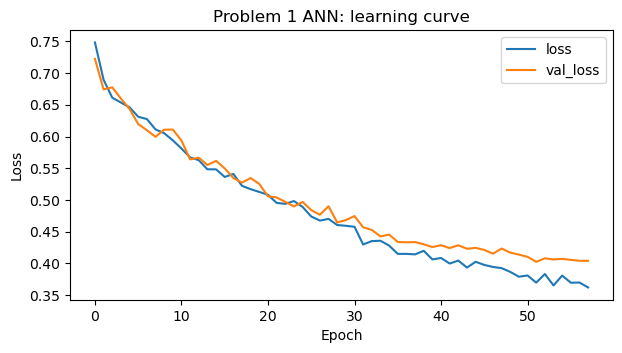

Best epoch 52: train loss 0.369, validation loss 0.402 (gap +0.033; large positive = overfitting)
Accuracy     0.805
Precision    0.035
Recall       0.197
F1           0.059
ROC-AUC      0.524
PR-AUC       0.037
-> Correct on 80% of batches; catches 20% of failures; 3% of its alerts are real (random 3%); PR-AUC 0.037 = 1.2x random; ROC-AUC 0.52 (0.5 = random).


In [721]:
w1 = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=y1_train)))  # give rare failures more weight
tf.keras.utils.set_random_seed(RANDOM_STATE)                              # reproducible starting weights
ann1 = keras.Sequential([layers.Input(shape=(Xtr.shape[1],))])                 # input layer
for units in (64, 32):                                                    # two hidden layers: 64 then 32 neurons
    ann1.add(layers.Dense(units, kernel_initializer="he_normal", use_bias=False))  # fully connected layer, He initialisation
    ann1.add(layers.BatchNormalization())                                # normalise outputs for stable training
    ann1.add(layers.Activation("relu"))                                  # ReLU activation
    ann1.add(layers.Dropout(0.2))                                        # drop 20% of neurons to reduce overfitting
ann1.add(layers.Dense(1, activation="sigmoid"))              # output layer matched to the task
ann1.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),  # Adam with gradient clipping
             loss="binary_crossentropy", metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])                             # loss matched to the task
ann1.summary()                                                           # print layers and parameter counts
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),  # keep the best epoch
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]  # halve the learning rate on a plateau
Xa, Xv, ya, yv = train_test_split(Xtr, y1_train, test_size=0.15,          # 85% to fit, 15% to validate
                                  stratify=y1_train, random_state=RANDOM_STATE)  # same failure mix in both parts
hist = ann1.fit(Xa, ya, validation_data=(Xv, yv), epochs=60, batch_size=256,  # train and check on the validation part
                 class_weight=w1, callbacks=callbacks, verbose=2)                   # one line per epoch
h = pd.DataFrame(hist.history)                                            # loss per epoch
h[["loss", "val_loss"]].plot(title="Problem 1 ANN: learning curve", xlabel="Epoch", ylabel="Loss", figsize=(7, 3.5))  # training vs validation loss
plt.show()                                                                # display the chart
b = int(h["val_loss"].idxmin())                                           # best epoch
print(f"Best epoch {b + 1}: train loss {h['loss'][b]:.3f}, validation loss {h['val_loss'][b]:.3f} (gap {h['val_loss'][b] - h['loss'][b]:+.3f}; large positive = overfitting)")
evaluate_p1("ANN", ann1.predict(Xte, verbose=0).ravel())                  # metrics on the test set

### Model comparison and choice

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
1,Logistic Regression,0.603,0.040,0.515,0.075,0.570,0.047
2,Random Forest,0.785,0.053,0.347,0.092,0.600,0.045
3,ANN,0.805,0.035,0.197,0.059,0.524,0.037
0,Baseline (always Passed),0.969,0.000,0.000,0.000,0.500,0.031


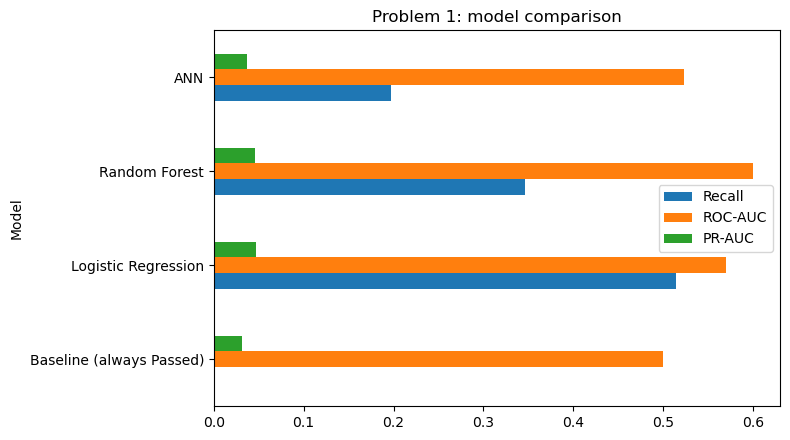

Chosen model: Logistic Regression - highest PR-AUC (0.047) against 0.031 for random guessing; PR-AUC decides because only about 3% of batches fail.


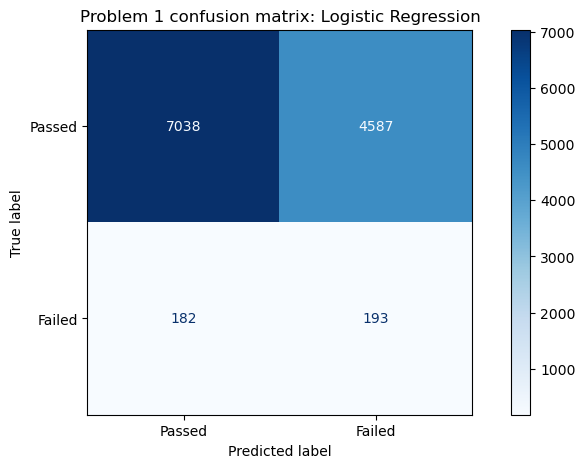

              precision    recall  f1-score   support

      Passed      0.975     0.605     0.747     11625
      Failed      0.040     0.515     0.075       375

    accuracy                          0.603     12000
   macro avg      0.508     0.560     0.411     12000
weighted avg      0.946     0.603     0.726     12000



In [723]:
classification_results = pd.DataFrame(p1_results.values())                # one row per model
display(classification_results.sort_values("PR-AUC", ascending=False).round(3))  # models from best to worst PR-AUC
classification_results.set_index("Model")[["Recall", "ROC-AUC", "PR-AUC"]].plot.barh(figsize=(8, 4.5), title="Problem 1: model comparison")  # bar chart
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the chart

candidates = classification_results[~classification_results["Model"].str.startswith("Baseline")]  # the baseline cannot be chosen
best1 = candidates.loc[candidates["PR-AUC"].idxmax(), "Model"]           # model with the highest PR-AUC
print(f"Chosen model: {best1} - highest PR-AUC ({candidates['PR-AUC'].max():.3f}) against {rate:.3f} for random guessing; "
      "PR-AUC decides because only about 3% of batches fail.")           # the choice and why

ConfusionMatrixDisplay.from_predictions(y1_test, (p1_prob[best1] >= 0.5).astype(int),  # confusion matrix of the chosen model
                                        display_labels=["Passed", "Failed"], cmap="Blues")
plt.title(f"Problem 1 confusion matrix: {best1}")                         # chart title
plt.show()                                                                # display the chart
print(classification_report(y1_test, (p1_prob[best1] >= 0.5).astype(int), target_names=["Passed", "Failed"],  # precision, recall, F1 per class
                            digits=3, zero_division=0))

# Map every encoded column back to its original variable (used by the feature importance below).
cats = sorted(categorical_columns, key=len, reverse=True)                 # categorical names, longest first
var = [next((c for c in cats if f.split("__", 1)[1].startswith(c + "_")), f.split("__", 1)[1]) for f in feature_names]  # one-hot column -> variable

**Results (test set: 12,000 batches, 375 failed = 3.1%)**
- **Comparison (PR-AUC):** Logistic Regression 0.047 > Random Forest 0.045 > ANN 0.037 > baseline 0.031.
- **Chosen: Logistic Regression.** It has the highest PR-AUC (1.5× random) and is the simplest and most explainable model.
- **Confusion matrix (threshold 0.5):** it catches **193 of the 375 failed batches (recall 51.5%)**. It also flags about 4,590 passed batches, so only **4.0%** of its alerts are real failures (about 1 in 25).
- **Random Forest** ranks slightly better overall (ROC-AUC 0.60 vs 0.57) but catches fewer failures (34.7%). The **ANN** catches only 19.7%; it is not overfitting (gap +0.033), but the data carries little failure signal.
- **Business implication:** production data gives only a weak early warning. QA can use the ranking to target extra in-process checks, but laboratory release testing must stay.

**Metric analysis (Problem 1, threshold 0.5)**

| Metric | What it measures | Logistic Regression (chosen) | Random Forest | Baseline | Reading |
|---|---|---|---|---|---|
| Accuracy | Share of all batches labelled correctly | 0.603 | 0.785 | 0.969 | Misleading: the baseline scores highest by calling every batch Passed |
| Precision | Share of flagged batches that really failed | 0.040 | 0.053 | 0.000 | About 1 real failure per 25 alerts (random: 3.1%) |
| Recall | Share of failed batches caught | 0.515 | 0.347 | 0.000 | Logistic Regression catches half of all failures |
| F1 | Balance of precision and recall | 0.075 | 0.092 | 0.000 | Low for every model, because precision is low |
| ROC-AUC | Ranks failed above passed (0.5 = random) | 0.570 | 0.600 | 0.500 | Weak separation for all models |
| PR-AUC | Ranking quality for the rare Failed class (random = 0.031) | 0.047 | 0.045 | 0.031 | Deciding metric: 1.5× random |

**Trade-off:** Logistic Regression flags about 40% of batches to catch 52% of failures; Random Forest flags about 20% and catches 35%. Raising the threshold cuts alerts but also cuts recall.

### Feature importance (Problem 1)
Which variables does the chosen model rely on? **Permutation importance** shuffles one variable at a time on the test set (all of its one-hot columns together) and measures how much PR-AUC drops. A large drop means the model depends on that variable; a drop near zero means it adds little. It works for any model, so it is used for the chosen model in Problems 1, 2 and 3.

,Drop in PR-AUC,Share of importance (%)
operator_experience_years,0.0183,26.9652
production_year,0.0121,17.9140
year,0.0120,17.6669
drug_name,0.0037,5.4860
production_week,0.0037,5.4423
batch_size,0.0037,5.4266
raw_material_quality,0.0021,3.0579
temp_variance,0.0017,2.4962
maintenance_status,0.0016,2.3433
ahu_id,0.0009,1.3914


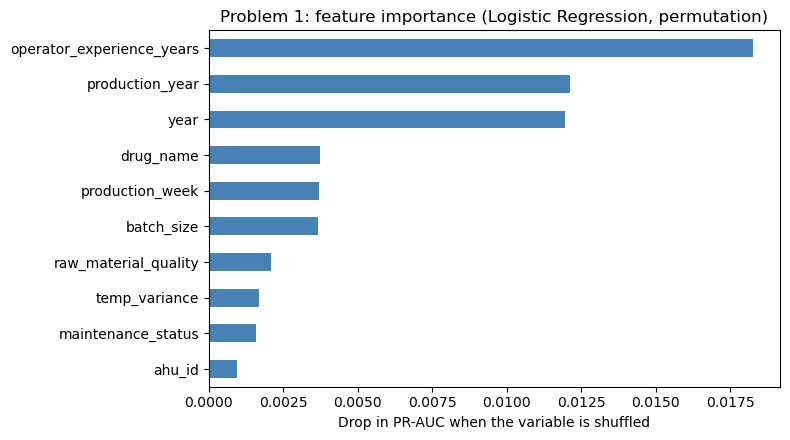

-> Top drivers: operator_experience_years, production_year, year. Shuffling the top one lowers PR-AUC by 0.0183; 15 of 43 variables add nothing (drop at or below zero).


In [727]:
# Permutation importance: shuffle one original variable at a time on the test set and measure how much the score drops.
def variable_importance(predict, X, y, names, score, higher=True, repeats=3):  # importance of each original variable
    rng = np.random.default_rng(RANDOM_STATE)                             # reproducible shuffles
    names = np.array(names)                                               # variable name for each encoded column
    base = score(y, predict(X))                                           # score with nothing shuffled
    drops = {}                                                            # score lost per variable
    for name in pd.unique(names):                                         # one original variable at a time
        cols = np.where(names == name)[0]                                 # all of its encoded columns (e.g. one-hot)
        lost = []                                                         # score lost in each repeat
        for _ in range(repeats):                                          # repeat to smooth out chance
            Xs = X.copy()                                                 # copy of the test features
            Xs[:, cols] = X[rng.permutation(len(X))][:, cols]             # shuffle this variable's columns together
            s = score(y, predict(Xs))                                     # score after shuffling
            lost.append(base - s if higher else s - base)                 # how much worse it got
        drops[name] = np.mean(lost)                                       # average loss
    return pd.Series(drops).sort_values(ascending=False)                  # most important first


models1 = {"Logistic Regression": logreg1, "Random Forest": rf1}    # models that give P(Failed)
fi1 = best1 if best1 in models1 else "Logistic Regression"                # the chosen model (if it is one of these)
imp1 = variable_importance(lambda X: models1[fi1].predict_proba(X)[:, 1], Xte, y1_test, var, average_precision_score)
top1 = imp1.head(10).rename("Drop in PR-AUC").to_frame()                  # the 10 most important variables
top1["Share of importance (%)"] = 100 * top1["Drop in PR-AUC"] / imp1.clip(lower=0).sum()  # share of all positive importance
display(top1.round(4))                                                    # show the table
top1["Drop in PR-AUC"].sort_values().plot.barh(figsize=(8, 4.5), color="steelblue",  # bar chart
                                                title=f"Problem 1: feature importance ({fi1}, permutation)")
plt.xlabel("Drop in PR-AUC when the variable is shuffled")                # x-axis label
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the chart
print(f"-> Top drivers: {', '.join(imp1.index[:3])}. Shuffling the top one lowers PR-AUC by {imp1.iloc[0]:.4f}; "
      f"{(imp1 <= 0).sum()} of {len(imp1)} variables add nothing (drop at or below zero).")  # plain explanation

**How to read it.** Each bar is how much PR-AUC falls when that variable is scrambled; longer bars are the variables the model leans on most.
- **Top drivers:**
  - **Operator experience** has the largest drop (0.018, 27% of all importance).
  - Next come **production year** and **year** (0.012 each, about 18% each). They are the same information twice and reflect the failure rate rising over the years (Section 5.7).
  - Drug name, production week and batch size follow (about 5% each). Raw-material quality, temperature variance and maintenance status are smaller (2–3%).
- **What adds nothing:** 15 of the 43 variables have a drop at or below zero and could be removed without losing accuracy.
- **Reading:** the drops are small because the model is weak overall (PR-AUC 0.047 against 0.031 for random guessing). Read the list as "conditions most linked to failure risk", not as causes. Supervising less experienced operators is the most practical lever it points to.

# 9. Problem 2: What yield will a batch achieve?
Same rows and features as Problem 1; target `actual_yield` (errors in yield points).

# Problem 2 models: Baseline | Random Forest | ANN

In [731]:
# Step 1 - Data: same rows and standardised features as Problem 1; the target is the actual yield.
from sklearn.dummy import DummyRegressor                                  # baseline model

y2_train = model_data.loc[X_train.index, "actual_yield"].to_numpy()       # training target: actual yield
y2_test = model_data.loc[X_test.index, "actual_yield"].to_numpy()         # test target: actual yield
p2_results, p2_pred = {}, {}                                              # metrics and predictions for each model


def evaluate_p2(name, pred):                                              # computes and explains the metrics of one model
    m = {"Model": name,
         "MAE": mean_absolute_error(y2_test, pred),                       # average miss in yield points
         "RMSE": np.sqrt(mean_squared_error(y2_test, pred)),              # like MAE but penalises large misses
         "R2": r2_score(y2_test, pred)}                                   # share of yield variation explained
    p2_results[name], p2_pred[name] = m, pred                             # store the results
    print(pd.Series(m).drop("Model").astype(float).round(3).to_string())  # show the metric values
    print(f"-> Misses actual yield by {m['MAE']:.2f} points on average (RMSE {m['RMSE']:.2f}); "
          f"explains {max(m['R2'], 0):.0%} of yield variation.")          # plain explanation

### Model 1: Baseline (mean yield)

In [733]:
baseline2 = DummyRegressor(strategy="mean").fit(Xtr, y2_train)           # always predicts the average training yield
evaluate_p2("Baseline (mean yield)", baseline2.predict(Xte))              # metrics on the test set

MAE     1.102
RMSE    1.338
R2     -0.000
-> Misses actual yield by 1.10 points on average (RMSE 1.34); explains 0% of yield variation.


### Model 2: Random Forest

In [735]:
rf2 = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5,  # 100 regression trees, up to 12 levels
                            n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, y2_train)  # train on the training rows
evaluate_p2("Random Forest", rf2.predict(Xte))                            # metrics on the test set

MAE     0.858
RMSE    1.095
R2      0.330
-> Misses actual yield by 0.86 points on average (RMSE 1.10); explains 33% of yield variation.


### Model 3: ANN (neural network)

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_13 (Dense)            (None, 64)                21184     
                                                                 
 batch_normalization_8 (Bat  (None, 64)                256       
 chNormalization)                                                
                                                                 
 activation_8 (Activation)   (None, 64)                0         
                                                                 
 dropout_8 (Dropout)         (None, 64)                0         
                                                                 
 dense_14 (Dense)            (None, 32)                2048      
                                                                 
 batch_normalization_9 (Bat  (None, 32)                128       
 chNormalization)                                     

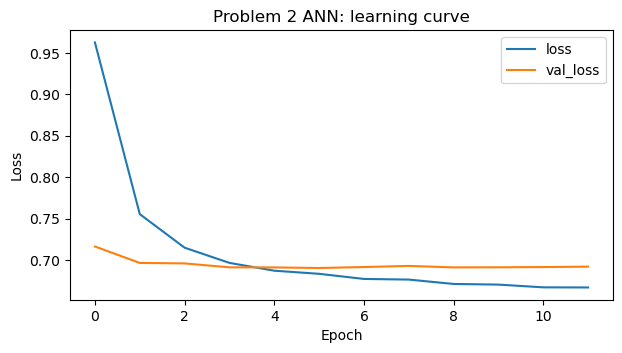

Best epoch 6: train loss 0.683, validation loss 0.690 (gap +0.007; large positive = overfitting)
MAE     0.859
RMSE    1.096
R2      0.328
-> Misses actual yield by 0.86 points on average (RMSE 1.10); explains 33% of yield variation.


In [737]:
mu, sd = y2_train.mean(), y2_train.std()                                  # the ANN learns the standardised yield
tf.keras.utils.set_random_seed(RANDOM_STATE)                              # reproducible starting weights
ann2 = keras.Sequential([layers.Input(shape=(Xtr.shape[1],))])                 # input layer
for units in (64, 32):                                                    # two hidden layers: 64 then 32 neurons
    ann2.add(layers.Dense(units, kernel_initializer="he_normal", use_bias=False))  # fully connected layer, He initialisation
    ann2.add(layers.BatchNormalization())                                # normalise outputs for stable training
    ann2.add(layers.Activation("relu"))                                  # ReLU activation
    ann2.add(layers.Dropout(0.2))                                        # drop 20% of neurons to reduce overfitting
ann2.add(layers.Dense(1, activation="linear"))              # output layer matched to the task
ann2.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),  # Adam with gradient clipping
             loss="mse", metrics=["mae"])                             # loss matched to the task
ann2.summary()                                                           # print layers and parameter counts
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),  # keep the best epoch
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]  # halve the learning rate on a plateau
Xa, Xv, ya, yv = train_test_split(Xtr, (y2_train - mu) / sd, test_size=0.15,  # 85% to fit, 15% to validate
                                  random_state=RANDOM_STATE)              # reproducible split
hist = ann2.fit(Xa, ya, validation_data=(Xv, yv), epochs=60, batch_size=256,  # train and check on the validation part
                 callbacks=callbacks, verbose=2)                   # one line per epoch
h = pd.DataFrame(hist.history)                                            # loss per epoch
h[["loss", "val_loss"]].plot(title="Problem 2 ANN: learning curve", xlabel="Epoch", ylabel="Loss", figsize=(7, 3.5))  # training vs validation loss
plt.show()                                                                # display the chart
b = int(h["val_loss"].idxmin())                                           # best epoch
print(f"Best epoch {b + 1}: train loss {h['loss'][b]:.3f}, validation loss {h['val_loss'][b]:.3f} (gap {h['val_loss'][b] - h['loss'][b]:+.3f}; large positive = overfitting)")
evaluate_p2("ANN", ann2.predict(Xte, verbose=0).ravel() * sd + mu)        # predictions back in yield points

### Model comparison and choice

,Model,MAE,RMSE,R2
1,Random Forest,0.858,1.095,0.330
2,ANN,0.859,1.096,0.328
0,Baseline (mean yield),1.102,1.338,-0.000


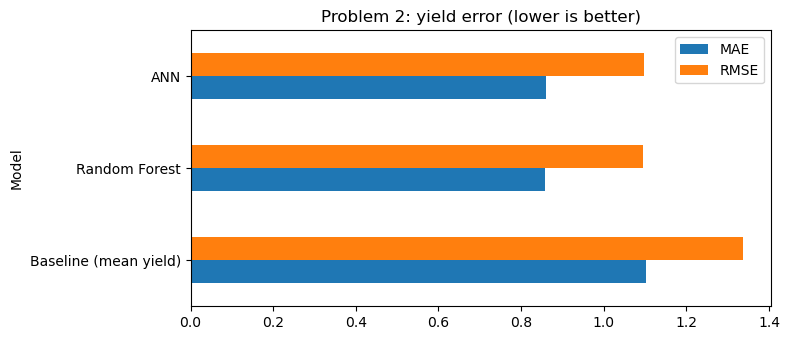

Chosen model: Random Forest - lowest MAE (0.858), 22% better than the baseline (1.102).


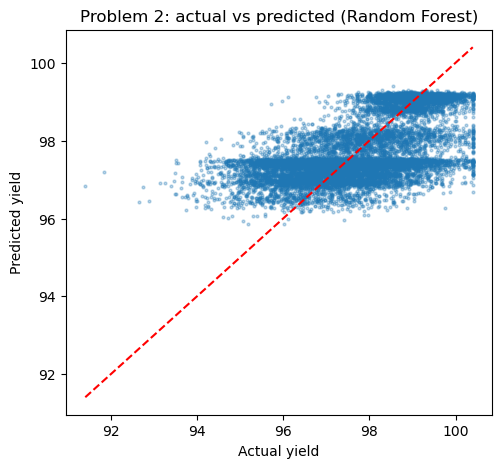

In [739]:
yield_results = pd.DataFrame(p2_results.values())                         # one row per model
display(yield_results.sort_values("MAE").round(3))                        # models from lowest to highest error
yield_results.set_index("Model")[["MAE", "RMSE"]].plot.barh(figsize=(8, 3.5), title="Problem 2: yield error (lower is better)")  # bar chart
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the chart

candidates = yield_results[~yield_results["Model"].str.startswith("Baseline")]  # the baseline cannot be chosen
best2 = candidates.loc[candidates["MAE"].idxmin(), "Model"]              # model with the lowest MAE
base_mae = p2_results["Baseline (mean yield)"]["MAE"]                     # baseline error
gain2 = 100 * (1 - candidates["MAE"].min() / base_mae)                    # % improvement over the baseline
print(f"Chosen model: {best2} - lowest MAE ({candidates['MAE'].min():.3f}), {abs(gain2):.0f}% "
      f"{'better' if gain2 >= 0 else 'worse'} than the baseline ({base_mae:.3f}).")  # the choice and why

plt.figure(figsize=(5.5, 5))                                              # new chart
plt.scatter(y2_test, p2_pred[best2], s=4, alpha=0.3)                      # actual vs predicted yield per batch
plt.plot([y2_test.min(), y2_test.max()], [y2_test.min(), y2_test.max()], "r--")  # perfect-prediction line
plt.xlabel("Actual yield")                                                # x-axis label
plt.ylabel("Predicted yield")                                             # y-axis label
plt.title(f"Problem 2: actual vs predicted ({best2})")                    # chart title
plt.show()                                                                # display the chart

**Results (test set: 12,000 batches)**
- **Comparison (MAE, yield points):** Random Forest 0.858 < ANN 0.859 < baseline 1.102.
- **Chosen: Random Forest.** It has the lowest error, 22% below the baseline (RMSE 1.10 vs 1.34), and explains 33% of yield variation (R² 0.330).
- **ANN:** practically level (MAE 0.859, R² 0.328) and not overfitting (best epoch 6, gap +0.007). Random Forest is kept because it scores best and its drivers are easier to explain.
- **Actual vs predicted chart:** the points follow the red line but are spread around it. Predictions are pulled toward the average, so very high and very low yields are under-forecast.
- **Business implication:** planners can forecast batch yield to within about ±0.9 points and flag batches likely to miss target. About two-thirds of yield variation comes from factors not recorded in the data.

**Metric analysis (Problem 2)**

| Metric | What it measures | Random Forest (chosen) | ANN | Baseline | Reading |
|---|---|---|---|---|---|
| MAE | Average miss, in yield points | 0.858 | 0.859 | 1.102 | 22% smaller error than the baseline |
| RMSE | Like MAE but penalises large misses | 1.095 | 1.096 | 1.338 | RMSE ≈ 1.3 × MAE, so errors are even and there are few large misses |
| R² | Share of yield variation explained (0 = baseline) | 0.330 | 0.328 | 0.000 | One third explained; the rest comes from unrecorded factors |

### Feature importance (Problem 2)
The same permutation method for the yield model: how much the average error (MAE) rises when each variable is shuffled.

,Rise in MAE (yield points),Share of importance (%)
batch_size_unit,0.3280,79.7240
dosage_form,0.0448,10.8919
ahu_id,0.0172,4.1728
operator_experience_years,0.0112,2.7126
manufacturing_section,0.0030,0.7216
maintenance_days_ago,0.0016,0.3926
pressure_avg,0.0012,0.2987
batch_size,0.0008,0.2045
downstream_equipment_id,0.0006,0.1355
production_hours,0.0006,0.1340


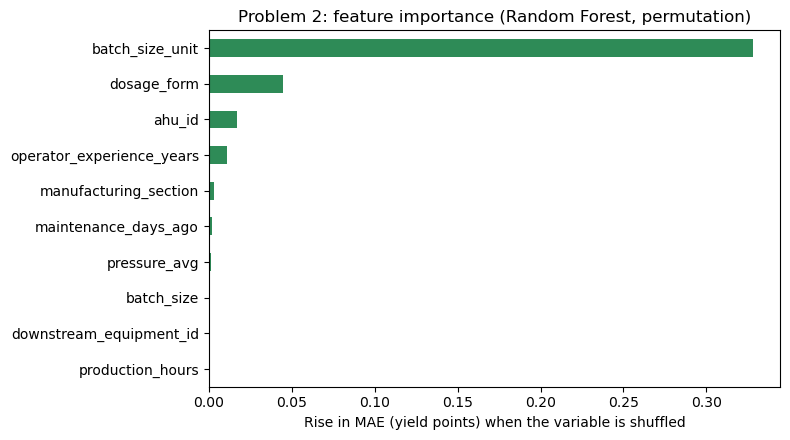

-> Top drivers of yield: batch_size_unit, dosage_form, ahu_id. Shuffling the top one raises the average error by 0.328 points (from 0.858).


In [743]:
# Permutation importance for the yield model: how much MAE rises when each variable is shuffled.
models2 = {"Random Forest": rf2}                                          # model that predicts from Xte directly
fi2 = best2 if best2 in models2 else "Random Forest"                      # the chosen model
imp2 = variable_importance(models2[fi2].predict, Xte, y2_test, var, mean_absolute_error, higher=False)  # higher MAE = worse
top2 = imp2.head(10).rename("Rise in MAE (yield points)").to_frame()      # the 10 most important variables
top2["Share of importance (%)"] = 100 * top2.iloc[:, 0] / imp2.clip(lower=0).sum()  # share of all positive importance
display(top2.round(4))                                                    # show the table
top2.iloc[:, 0].sort_values().plot.barh(figsize=(8, 4.5), color="seagreen",  # bar chart
                                        title=f"Problem 2: feature importance ({fi2}, permutation)")
plt.xlabel("Rise in MAE (yield points) when the variable is shuffled")    # x-axis label
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the chart
print(f"-> Top drivers of yield: {', '.join(imp2.index[:3])}. Shuffling the top one raises the average error by "
      f"{imp2.iloc[0]:.3f} points (from {mean_absolute_error(y2_test, models2[fi2].predict(Xte)):.3f}).")  # plain explanation

**How to read it.** The longest bars are the variables that drive the yield forecast.
- **`batch_size_unit` dominates:** shuffling it raises the error by **0.328 points** (from 0.858), **80%** of all importance. The unit separates kilograms (solids) from litres (liquids), and liquids have much higher yields (median 99.0 against 97.4 for Oral Solids). It therefore stands in for the product type.
- **Next:** dosage form (11%), air-handling unit (`ahu_id`, 4%) and operator experience (3%). Section, days since service, pressure, batch size and production hours each add under 1%.
- **Reading:** yield is driven mainly by **what is made**, not by process settings. **For planners:** compare a batch's yield with the forecast for its own product and dosage form. The process variables explain little extra.

# 10. Problem 3: What maintenance state is the equipment in?
The status is set by days since the last service, so those columns are removed from the features. Macro F1 treats Current, Due Soon and Critical equally.

# Problem 3 models: Baseline | Logistic Regression | Random Forest | ANN

In [747]:
# Step 1 - Data: same rows as Problem 1, minus the maintenance columns that give away the answer.
from sklearn.metrics import balanced_accuracy_score                      # average recall over the classes

leaky = ("maintenance_status", "maintenance_urgency", "maintenance_days_ago", "days_since_maintenance")  # columns that reveal the status
keep = [i for i, f in enumerate(feature_names) if not f.split("__", 1)[1].startswith(leaky)]  # positions of the other features
X3tr, X3te = Xtr[:, keep], Xte[:, keep]                                  # training and test features without them
levels = ["Current", "Due Soon", "Critical"]                              # the three maintenance states
codes = {name: i for i, name in enumerate(levels)}                        # state name -> 0, 1, 2
y3_train = model_data.loc[X_train.index, "maintenance_status"].map(codes).to_numpy()  # training target
y3_test = model_data.loc[X_test.index, "maintenance_status"].map(codes).to_numpy()    # test target
print(f"Removed {Xtr.shape[1] - len(keep)} maintenance columns; {len(keep)} features used; "
      f"{(y3_test == 0).mean():.1%} of test records are Current.")      # data summary
p3_results, p3_pred = {}, {}                                              # metrics and predictions for each model


def evaluate_p3(name, pred):                                              # computes and explains the metrics of one model
    m = {"Model": name,
         "Accuracy": accuracy_score(y3_test, pred),                       # share of all records labelled correctly
         "Balanced accuracy": balanced_accuracy_score(y3_test, pred),     # average recall over the three states
         "Macro F1": f1_score(y3_test, pred, average="macro", zero_division=0),  # average F1 over the three states
         "Recall Critical": recall_score(y3_test, pred, labels=[2], average="macro", zero_division=0),  # share of Critical found
         "Precision Critical": precision_score(y3_test, pred, labels=[2], average="macro", zero_division=0)}  # share of Critical alerts that are right
    p3_results[name], p3_pred[name] = m, pred                             # store the results
    print(pd.Series(m).drop("Model").astype(float).round(3).to_string())  # show the metric values
    print(f"-> Correct on {m['Accuracy']:.0%} of records; finds {m['Balanced accuracy']:.0%} of each state on average; "
          f"macro F1 {m['Macro F1']:.2f}; finds {m['Recall Critical']:.0%} of Critical equipment (target 75%), "
          f"and {m['Precision Critical']:.0%} of its Critical alerts are right.")  # plain explanation

Removed 6 maintenance columns; 325 features used; 90.3% of test records are Current.


### Model 1: Baseline (always "Current")

In [749]:
baseline3 = DummyClassifier(strategy="most_frequent").fit(X3tr, y3_train)  # always predicts the most common state
evaluate_p3("Baseline (always Current)", baseline3.predict(X3te))         # metrics on the test set

Accuracy              0.903
Balanced accuracy     0.333
Macro F1              0.316
Recall Critical       0.000
Precision Critical    0.000
-> Correct on 90% of records; finds 33% of each state on average; macro F1 0.32; finds 0% of Critical equipment (target 75%), and 0% of its Critical alerts are right.


### Model 2: Logistic Regression

In [751]:
logreg3 = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X3tr, y3_train)  # linear model; rare states weighted up
evaluate_p3("Logistic Regression", logreg3.predict(X3te))                 # metrics on the test set

Accuracy              0.549
Balanced accuracy     0.620
Macro F1              0.354
Recall Critical       0.563
Precision Critical    0.022
-> Correct on 55% of records; finds 62% of each state on average; macro F1 0.35; finds 56% of Critical equipment (target 75%), and 2% of its Critical alerts are right.


### Model 3: Random Forest

In [753]:
rf3 = RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=5,  # 150 trees, up to 12 levels
                             class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE).fit(X3tr, y3_train)  # rare states weighted up
evaluate_p3("Random Forest", rf3.predict(X3te))                           # metrics on the test set

Accuracy              0.818
Balanced accuracy     0.734
Macro F1              0.557
Recall Critical       0.690
Precision Critical    0.239
-> Correct on 82% of records; finds 73% of each state on average; macro F1 0.56; finds 69% of Critical equipment (target 75%), and 24% of its Critical alerts are right.


### Model 4: ANN (neural network)

Model: "sequential_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_16 (Dense)            (None, 64)                20800     
                                                                 
 batch_normalization_10 (Ba  (None, 64)                256       
 tchNormalization)                                               
                                                                 
 activation_10 (Activation)  (None, 64)                0         
                                                                 
 dropout_10 (Dropout)        (None, 64)                0         
                                                                 
 dense_17 (Dense)            (None, 32)                2048      
                                                                 
 batch_normalization_11 (Ba  (None, 32)                128       
 tchNormalization)                                    

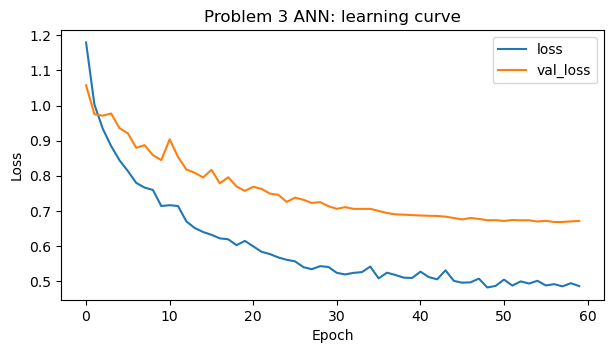

Best epoch 57: train loss 0.492, validation loss 0.669 (gap +0.177; large positive = overfitting)
Accuracy              0.632
Balanced accuracy     0.503
Macro F1              0.362
Recall Critical       0.207
Precision Critical    0.030
-> Correct on 63% of records; finds 50% of each state on average; macro F1 0.36; finds 21% of Critical equipment (target 75%), and 3% of its Critical alerts are right.


In [755]:
w3 = dict(enumerate(compute_class_weight("balanced", classes=np.arange(3), y=y3_train)))  # give rare states more weight
tf.keras.utils.set_random_seed(RANDOM_STATE)                              # reproducible starting weights
ann3 = keras.Sequential([layers.Input(shape=(X3tr.shape[1],))])                 # input layer
for units in (64, 32):                                                    # two hidden layers: 64 then 32 neurons
    ann3.add(layers.Dense(units, kernel_initializer="he_normal", use_bias=False))  # fully connected layer, He initialisation
    ann3.add(layers.BatchNormalization())                                # normalise outputs for stable training
    ann3.add(layers.Activation("relu"))                                  # ReLU activation
    ann3.add(layers.Dropout(0.2))                                        # drop 20% of neurons to reduce overfitting
ann3.add(layers.Dense(3, activation="softmax"))              # output layer matched to the task
ann3.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),  # Adam with gradient clipping
             loss="sparse_categorical_crossentropy", metrics=["accuracy"])                             # loss matched to the task
ann3.summary()                                                           # print layers and parameter counts
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),  # keep the best epoch
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]  # halve the learning rate on a plateau
Xa, Xv, ya, yv = train_test_split(X3tr, y3_train, test_size=0.15,         # 85% to fit, 15% to validate
                                  stratify=y3_train, random_state=RANDOM_STATE)  # same state mix in both parts
hist = ann3.fit(Xa, ya, validation_data=(Xv, yv), epochs=60, batch_size=256,  # train and check on the validation part
                 class_weight=w3, callbacks=callbacks, verbose=2)                   # one line per epoch
h = pd.DataFrame(hist.history)                                            # loss per epoch
h[["loss", "val_loss"]].plot(title="Problem 3 ANN: learning curve", xlabel="Epoch", ylabel="Loss", figsize=(7, 3.5))  # training vs validation loss
plt.show()                                                                # display the chart
b = int(h["val_loss"].idxmin())                                           # best epoch
print(f"Best epoch {b + 1}: train loss {h['loss'][b]:.3f}, validation loss {h['val_loss'][b]:.3f} (gap {h['val_loss'][b] - h['loss'][b]:+.3f}; large positive = overfitting)")
evaluate_p3("ANN", ann3.predict(X3te, verbose=0).argmax(axis=1))          # most likely state; metrics on the test set

### Model comparison and choice

,Model,Accuracy,Balanced accuracy,Macro F1,Recall Critical,Precision Critical
2,Random Forest,0.818,0.734,0.557,0.690,0.239
3,ANN,0.632,0.503,0.362,0.207,0.030
1,Logistic Regression,0.549,0.620,0.354,0.563,0.022
0,Baseline (always Current),0.903,0.333,0.316,0.000,0.000


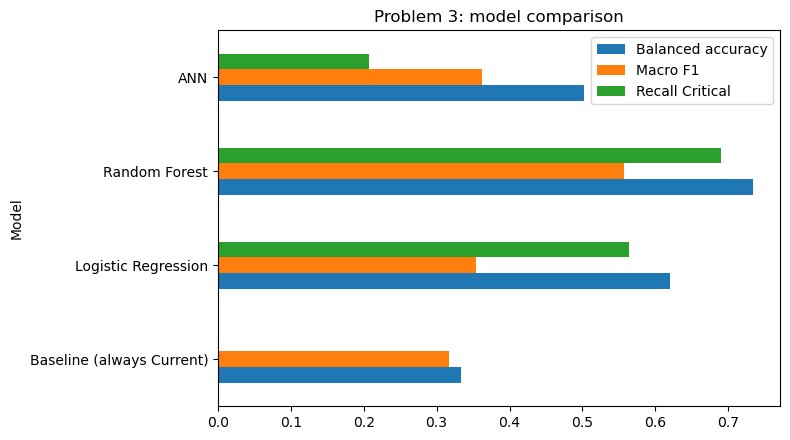

Chosen model: Random Forest - highest macro F1 (0.557) against 0.316 for the baseline; macro F1 decides because it treats the three states equally.


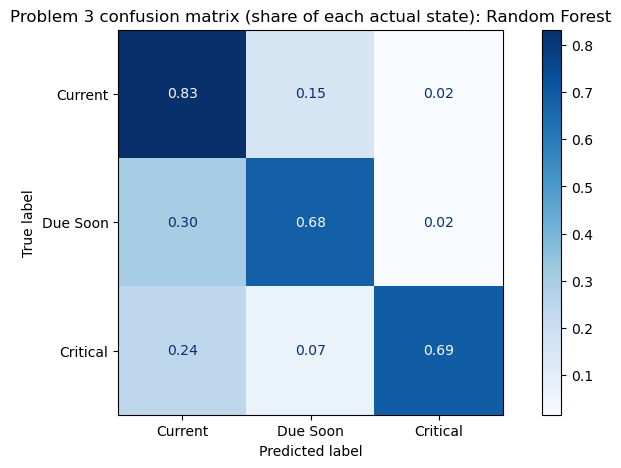

              precision    recall  f1-score   support

     Current      0.963     0.833     0.893     10836
    Due Soon      0.308     0.681     0.424      1077
    Critical      0.239     0.690     0.355        87

    accuracy                          0.818     12000
   macro avg      0.503     0.734     0.557     12000
weighted avg      0.899     0.818     0.847     12000



In [757]:
maintenance_results = pd.DataFrame(p3_results.values())                   # one row per model
display(maintenance_results.sort_values("Macro F1", ascending=False).round(3))  # models from best to worst macro F1
maintenance_results.set_index("Model")[["Balanced accuracy", "Macro F1", "Recall Critical"]].plot.barh(  # bar chart
    figsize=(8, 4.5), title="Problem 3: model comparison")
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the chart

candidates = maintenance_results[~maintenance_results["Model"].str.startswith("Baseline")]  # the baseline cannot be chosen
best3 = candidates.loc[candidates["Macro F1"].idxmax(), "Model"]          # model with the highest macro F1
print(f"Chosen model: {best3} - highest macro F1 ({candidates['Macro F1'].max():.3f}) against "
      f"{p3_results['Baseline (always Current)']['Macro F1']:.3f} for the baseline; macro F1 decides because "
      "it treats the three states equally.")                             # the choice and why

ConfusionMatrixDisplay.from_predictions(y3_test, p3_pred[best3], display_labels=levels,  # confusion matrix of the chosen model
                                        normalize="true", values_format=".2f", cmap="Blues")  # share of each actual state
plt.title(f"Problem 3 confusion matrix (share of each actual state): {best3}")  # chart title
plt.show()                                                                # display the chart
print(classification_report(y3_test, p3_pred[best3], target_names=levels, digits=3, zero_division=0))  # precision, recall, F1 per state

# Map every encoded column back to its original variable (used by the feature importance below).
cats = sorted(categorical_columns, key=len, reverse=True)                 # categorical names, longest first
var3 = [next((c for c in cats if feature_names[i].split("__", 1)[1].startswith(c + "_")),  # one-hot column -> variable
             feature_names[i].split("__", 1)[1]) for i in keep]

**Results (test set: 12,000 records: 10,836 Current, 1,077 Due Soon, 87 Critical)**
- **Comparison (macro F1):** Random Forest 0.557 > ANN 0.362 > Logistic Regression 0.354 > baseline 0.316.
- **Chosen: Random Forest.** It is clearly the best on every balanced measure (balanced accuracy 0.734).
- **Confusion matrix:** it finds **60 of the 87 Critical records (69%)**, just below the proposal's 0.75 target, plus 68% of Due Soon and 83% of Current records. About 1 in 4 Critical alerts is truly Critical; the rest are mostly machines close to their service date, a cheap mistake.
- **Other models:** Logistic Regression finds 56% of Critical equipment but only 2% of its Critical alerts are right. The ANN finds only 21% and overfits (gap +0.177). The baseline's 90.3% accuracy finds nothing.
- **Business implication:** Facilities can flag most overdue equipment from routine production data. Use it alongside the service calendar until recall reaches 0.75.

**Metric analysis (Problem 3)**

| Metric | What it measures | Random Forest (chosen) | ANN | Logistic Regression | Baseline | Reading |
|---|---|---|---|---|---|---|
| Accuracy | Share of all records labelled correctly | 0.818 | 0.632 | 0.549 | 0.903 | Misleading: 90% of records are Current |
| Balanced accuracy | Average recall over the three states | 0.734 | 0.503 | 0.620 | 0.333 | Random Forest finds 73% of each state on average |
| Macro F1 | Average F1 over the three states | 0.557 | 0.362 | 0.354 | 0.316 | Random Forest is far ahead |
| Recall (Critical) | Share of Critical equipment found | 0.690 | 0.207 | 0.563 | 0.000 | Just below the proposal target of 0.75 |
| Precision (Critical) | Share of Critical alerts that are right | 0.239 | 0.030 | 0.022 | 0.000 | About 1 in 4 alerts for Random Forest |

**Per state (Random Forest):** Current recall 0.833 and precision 0.963; Due Soon 0.681 and 0.308; Critical 0.690 and 0.239.

### Feature importance (Problem 3)
The same method for the maintenance-status model: how much macro F1 falls when each variable is shuffled. The service-date columns were already removed, so this shows what else in routine production data points to overdue equipment.

,Drop in macro F1,Share of importance (%)
equipment_age_days,0.0429,28.1232
production_year,0.0289,18.9358
year,0.0258,16.9502
production_week,0.0225,14.7880
equipment_age_group,0.0129,8.4802
operator_experience_years,0.0042,2.7348
temp_avg,0.0037,2.4179
temp_variance,0.0026,1.7045
production_quarter,0.0017,1.1207
month,0.0014,0.9482


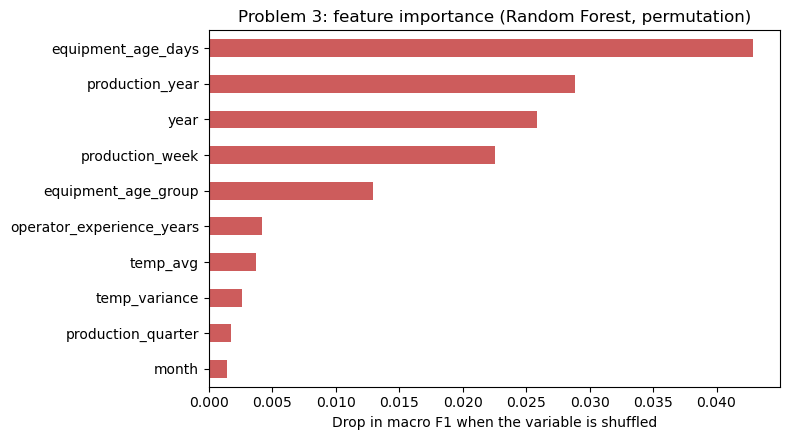

-> Top drivers of maintenance status: equipment_age_days, production_year, year. Shuffling the top one lowers macro F1 by 0.043 (from 0.557).


In [761]:
# Permutation importance for the maintenance-status model: how much macro F1 falls when each variable is shuffled.
models3 = {"Random Forest": rf3, "Logistic Regression": logreg3}          # models that predict from X3te directly
fi3 = best3 if best3 in models3 else "Random Forest"                      # the chosen model
macro_f1 = lambda y, p: f1_score(y, p, average="macro", zero_division=0)  # deciding metric
imp3 = variable_importance(models3[fi3].predict, X3te, y3_test, var3, macro_f1)  # higher F1 = better
top3_fi = imp3.head(10).rename("Drop in macro F1").to_frame()             # the 10 most important variables
top3_fi["Share of importance (%)"] = 100 * top3_fi.iloc[:, 0] / imp3.clip(lower=0).sum()  # share of all positive importance
display(top3_fi.round(4))                                                 # show the table
top3_fi.iloc[:, 0].sort_values().plot.barh(figsize=(8, 4.5), color="indianred",  # bar chart
                                           title=f"Problem 3: feature importance ({fi3}, permutation)")
plt.xlabel("Drop in macro F1 when the variable is shuffled")              # x-axis label
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the chart
print(f"-> Top drivers of maintenance status: {', '.join(imp3.index[:3])}. Shuffling the top one lowers macro F1 by "
      f"{imp3.iloc[0]:.3f} (from {macro_f1(y3_test, models3[fi3].predict(X3te)):.3f}).")  # plain explanation

**How to read it.**
- **Top drivers:**
  - **Equipment age** is the strongest (drop of **0.043** in macro F1, 28% of importance).
  - Next come **production year** (19%), **year** (17%), **production week** (15%) and **equipment age group** (8%). Operator experience and temperature add under 3% each.
- **Reading:** the model recognises overdue equipment mainly from **how old the machine is and when the batch was made**, which places the machine in its service cycle. It is tracking the service calendar, not a physical sign of wear.
- **For Facilities:** recording actual service dates would make this prediction unnecessary, because the status could be read directly.

# 11. Problem 4: Are monthly quality indicators deteriorating?
Next month's yield, failure rate, temperature, pressure and batch volume are forecast from earlier months only (`train_test_split` with `shuffle=False`: the last 36 months are the test period). As in the proposal, models are judged by WAPE against a seasonal-naive baseline (same month last year).

# Problem 4 models: Seasonal-naive | Moving average | Linear Regression | GRU

In [765]:
# Step 1 - Data: monthly indicators; the last 36 months are the test period (time-based split).
from sklearn.linear_model import LinearRegression                         # linear regression model

monthly =(clean_data.assign(failed=(clean_data["batch_passed"] == 0).astype(int))  # add a 1/0 "failed" flag
           .set_index("production_start").resample("MS")                  # group batches by calendar month
           .agg(actual_yield=("actual_yield", "mean"), failure_rate=("failed", "mean"),  # monthly mean yield and failure rate
                temp_avg=("temp_avg", "mean"), pressure_avg=("pressure_avg", "mean"),  # monthly mean temperature and pressure
                batch_volume=("batch_id", "count"))                       # number of batches per month
           .iloc[:-1])                                                    # drop the last, incomplete month
train4, test4 = train_test_split(monthly, test_size=36, shuffle=False)    # time order kept: last 36 months = test
mean4, std4 = train4.mean(), train4.std()                                 # scaling learned from training months only
scaled = ((monthly - mean4) / std4).to_numpy("float32")                   # standardised indicators (for the neural networks)
Xw = np.stack([scaled[i - 12:i] for i in range(12, len(scaled))])         # inputs: the previous 12 months for each month
yw = scaled[12:]                                                          # target: the month that follows
is_test = monthly.index[12:] >= test4.index[0]                            # True for windows in the test period
Xw_fit, Xw_val, yw_fit, yw_val = train_test_split(Xw[~is_test], yw[~is_test],  # neural-net validation windows:
                                                  test_size=0.15, shuffle=False)  # the last 15% of training windows
n_ind = monthly.shape[1]                                                  # number of indicators (5)
naive_wape = (100 * (monthly.shift(12).loc[test4.index] - test4).abs().sum() / test4.abs().sum()).mean()  # seasonal-naive WAPE (reference)
print(f"{len(train4)} training months, {len(test4)} test months; seasonal-naive WAPE {naive_wape:.2f}%")  # data summary
p4_results, p4_pred = {}, {}                                              # metrics and forecasts for each model


def evaluate_p4(name, pred):                                              # computes and explains the metrics of one model
    wape = 100 * (pred - test4).abs().sum() / test4.abs().sum()           # WAPE per indicator = total error / total actual
    m = {"Model": name, **wape.add_prefix("WAPE ").to_dict(), "WAPE (%)": wape.mean(),  # per-indicator and average WAPE
         "Gain vs seasonal-naive (%)": 100 * (naive_wape - wape.mean()) / naive_wape}  # improvement over seasonal-naive
    p4_results[name], p4_pred[name] = m, pred                             # store the results
    print(pd.Series(m).drop("Model").astype(float).round(2).to_string())  # show the metric values
    print(f"-> Average WAPE {m['WAPE (%)']:.2f}%: forecasts miss by about {m['WAPE (%)']:.1f}% of the actual level; "
          f"{m['Gain vs seasonal-naive (%)']:.1f}% better than seasonal-naive "
          f"({'meets' if m['Gain vs seasonal-naive (%)'] >= 15 else 'misses'} the 15% target).")  # plain explanation

201 training months, 36 test months; seasonal-naive WAPE 8.82%


### Model 1: Baseline (seasonal-naive)

In [767]:
evaluate_p4("Baseline (seasonal-naive)", monthly.shift(12).loc[test4.index])  # forecast = same month last year

WAPE actual_yield              0.10
WAPE failure_rate             36.11
WAPE temp_avg                  0.23
WAPE pressure_avg              0.51
WAPE batch_volume              7.17
WAPE (%)                       8.82
Gain vs seasonal-naive (%)     0.00
-> Average WAPE 8.82%: forecasts miss by about 8.8% of the actual level; 0.0% better than seasonal-naive (misses the 15% target).


### Model 2: Moving average (12 months)

In [769]:
evaluate_p4("Moving average (12 months)", monthly.shift(1).rolling(12).mean().loc[test4.index])  # forecast = mean of the previous 12 months

WAPE actual_yield              0.07
WAPE failure_rate             26.80
WAPE temp_avg                  1.30
WAPE pressure_avg              0.40
WAPE batch_volume              7.63
WAPE (%)                       7.24
Gain vs seasonal-naive (%)    17.95
-> Average WAPE 7.24%: forecasts miss by about 7.2% of the actual level; 17.9% better than seasonal-naive (meets the 15% target).


### Model 3: Linear Regression

In [771]:
last_month, avg_12 = monthly.shift(1), monthly.shift(1).rolling(12).mean()  # inputs known before each month
linear = {}                                                               # forecasts per indicator
for col in monthly:                                                       # one regression per indicator
    X4 = pd.DataFrame({"last_month": last_month[col], "avg_12": avg_12[col]}).dropna()  # inputs for every month
    fit_rows = X4.index[X4.index < test4.index[0]]                        # training months only
    linear[col] = LinearRegression().fit(X4.loc[fit_rows], monthly.loc[fit_rows, col]).predict(X4.loc[test4.index])  # fit, then forecast
evaluate_p4("Linear Regression", pd.DataFrame(linear, index=test4.index))  # metrics on the test months

WAPE actual_yield              0.06
WAPE failure_rate             26.26
WAPE temp_avg                  0.83
WAPE pressure_avg              0.39
WAPE batch_volume              7.47
WAPE (%)                       7.00
Gain vs seasonal-naive (%)    20.62
-> Average WAPE 7.00%: forecasts miss by about 7.0% of the actual level; 20.6% better than seasonal-naive (meets the 15% target).


### Model 4: GRU (neural network)

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 gru_1 (GRU)                 (None, 32)                3744      
                                                                 
 dense_19 (Dense)            (None, 5)                 165       
                                                                 
Total params: 3909 (15.27 KB)
Trainable params: 3909 (15.27 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/200
10/10 - 2s - loss: 0.9142 - val_loss: 1.0004 - lr: 0.0010 - 2s/epoch - 203ms/step
Epoch 2/200
10/10 - 0s - loss: 0.8220 - val_loss: 0.8588 - lr: 0.0010 - 49ms/epoch - 5ms/step
Epoch 3/200
10/10 - 0s - loss: 0.7680 - val_loss: 0.7563 - lr: 0.0010 - 46ms/epoch - 5ms/step
Epoch 4/200
10/10 - 0s - loss: 0.7274 - val_loss: 0.6852 - lr: 0.0010 - 45ms/epoch - 4ms/step
Epoch 5/200
10/10 - 0s - loss: 0.7064 - 

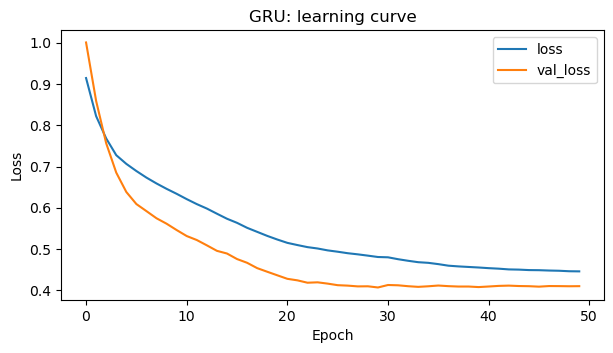

Best epoch 30: train loss 0.481, validation loss 0.407 (gap -0.074)
WAPE actual_yield              0.08
WAPE failure_rate             24.60
WAPE temp_avg                  0.66
WAPE pressure_avg              0.40
WAPE batch_volume             10.85
WAPE (%)                       7.32
Gain vs seasonal-naive (%)    17.06
-> Average WAPE 7.32%: forecasts miss by about 7.3% of the actual level; 17.1% better than seasonal-naive (meets the 15% target).


In [773]:
tf.keras.utils.set_random_seed(RANDOM_STATE)                              # reproducible starting weights
gru = keras.Sequential([layers.Input(shape=(12, n_ind)), layers.GRU(32), layers.Dense(n_ind)])  # 32-unit gated recurrent layer
gru.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0), loss="mse")  # Adam with gradient clipping, MSE loss
gru.summary()                                                           # print layers and parameter counts
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),  # keep the best epoch
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6)]  # halve the learning rate on a plateau
hist = gru.fit(Xw_fit, yw_fit, validation_data=(Xw_val, yw_val), epochs=200, batch_size=16,  # train on training windows
                 callbacks=callbacks, verbose=2)                          # one line per epoch
h = pd.DataFrame(hist.history)                                            # loss per epoch
h[["loss", "val_loss"]].plot(title="GRU: learning curve", xlabel="Epoch", ylabel="Loss", figsize=(7, 3.5))  # training vs validation loss
plt.show()                                                                # display the chart
b = int(h["val_loss"].idxmin())                                           # best epoch
print(f"Best epoch {b + 1}: train loss {h['loss'][b]:.3f}, validation loss {h['val_loss'][b]:.3f} (gap {h['val_loss'][b] - h['loss'][b]:+.3f})")
evaluate_p4("GRU", pd.DataFrame(gru.predict(Xw[is_test], verbose=0) * std4.to_numpy() + mean4.to_numpy(),  # forecasts in original units
                                index=test4.index, columns=monthly.columns))

### Model comparison and choice

,Model,WAPE actual_yield,WAPE failure_rate,WAPE temp_avg,WAPE pressure_avg,WAPE batch_volume,WAPE (%),Gain vs seasonal-naive (%)
2,Linear Regression,0.06,26.26,0.83,0.39,7.47,7.00,20.62
1,Moving average (12 months),0.07,26.80,1.30,0.40,7.63,7.24,17.95
3,GRU,0.08,24.60,0.66,0.40,10.85,7.32,17.06
0,Baseline (seasonal-naive),0.10,36.11,0.23,0.51,7.17,8.82,0.00


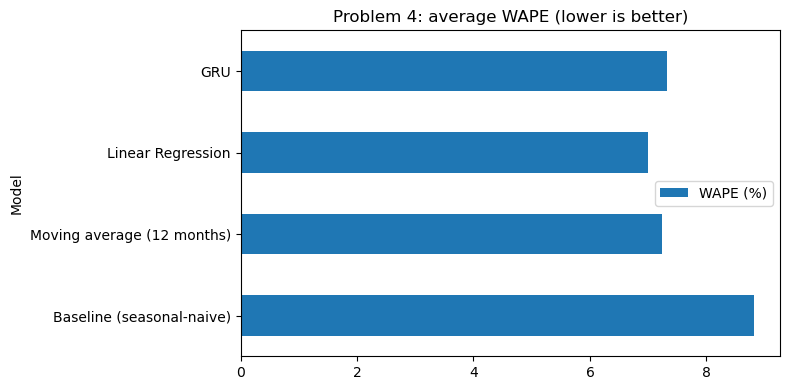

Chosen model: Linear Regression - lowest average WAPE (7.00%), 20.6% better than seasonal-naive (meets the proposal's 15% target).


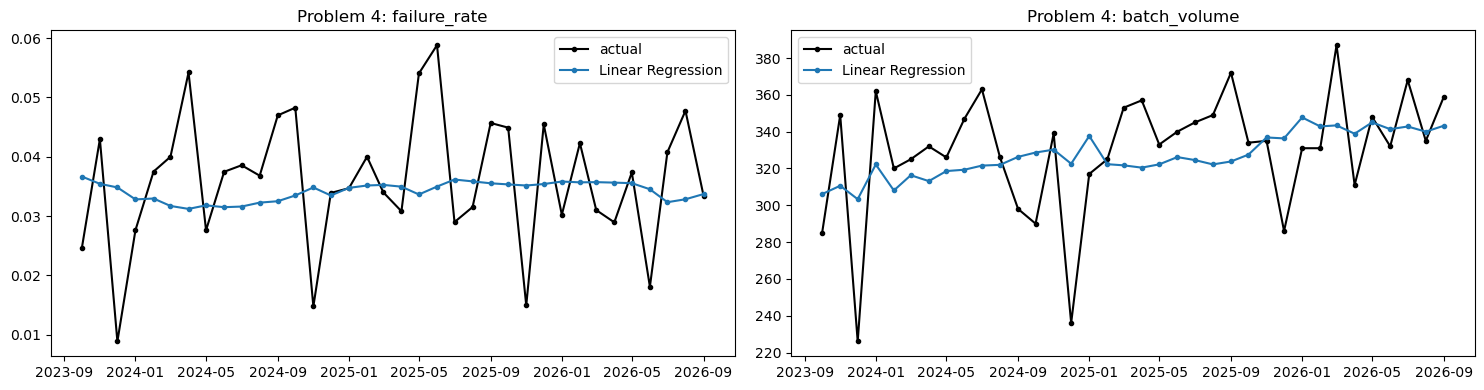

In [775]:
sequence_results = pd.DataFrame(p4_results.values())                      # one row per model
display(sequence_results.sort_values("WAPE (%)").round(2))                # models from lowest to highest WAPE
sequence_results.set_index("Model")[["WAPE (%)"]].plot.barh(figsize=(8, 4), title="Problem 4: average WAPE (lower is better)")  # bar chart
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the chart

candidates = sequence_results[~sequence_results["Model"].str.startswith("Baseline")]  # the baseline cannot be chosen
best4 = candidates.loc[candidates["WAPE (%)"].idxmin(), "Model"]          # model with the lowest WAPE
gain4 = p4_results[best4]["Gain vs seasonal-naive (%)"]                   # its gain over seasonal-naive
print(f"Chosen model: {best4} - lowest average WAPE ({candidates['WAPE (%)'].min():.2f}%), {gain4:.1f}% better than "
      f"seasonal-naive ({'meets' if gain4 >= 15 else 'misses'} the proposal's 15% target).")  # the choice and why

fig, axes = plt.subplots(1, 2, figsize=(15, 4))                           # two charts side by side
for ax, col in zip(axes, ["failure_rate", "batch_volume"]):               # one chart per indicator
    ax.plot(test4.index, test4[col], "k-o", ms=3, label="actual")         # actual monthly values
    ax.plot(test4.index, p4_pred[best4][col], "-o", ms=3, label=best4)    # chosen model's forecast
    ax.set_title(f"Problem 4: {col}")                                     # chart title
    ax.legend()                                                           # show the legend
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the charts

**Results (test period: the last 36 months; 201 training months)**
- **Comparison (average WAPE):** Linear Regression 7.00% < Moving average 7.24% < GRU 7.32% < seasonal-naive 8.82%.
- **Chosen: Linear Regression.** It is **20.6% better than seasonal-naive**, which meets the proposal's 15% target. The moving average (17.9%) and GRU (17.1%) also meet it.
- **By indicator:** yield (0.06%), pressure (0.39%) and temperature (0.83%) are forecast almost exactly. Batch volume (7.5%) and failure rate (26.3%) are harder; the GRU forecasts failure rate a little better (24.6%).
- **Business implication:** QA can use the forecast as the expected monthly level and investigate months that depart from it, especially in failure rate.

**Metric analysis (Problem 4, WAPE = total absolute error ÷ total actual, lower is better)**

| Metric | Linear Regression (chosen) | GRU | Seasonal-naive (baseline) | Reading |
|---|---|---|---|---|
| Average WAPE | 7.00% | 7.32% | 8.82% | Chosen model is lowest overall |
| Gain vs seasonal-naive | 20.6% | 17.1% | 0% | Both meet the 15% target |
| WAPE – failure rate | 26.26% | 24.60% | 36.11% | Hardest indicator |
| WAPE – batch volume | 7.47% | 10.85% | 7.17% | Volume repeats yearly, so seasonal-naive does well |

# 12. Problem 5: Which batches ran under abnormal process conditions?
Unsupervised: models learn "normal" from the scaled process columns of the training batches. Failures are used only to check whether unusual batches fail more often.

# Problem 5 models: Baseline | Z-score rule | PCA | KNN distance

In [780]:
# Step 1 - Data: the standardised process columns from Problem 1; failures are used only to check the scores.
from sklearn.neighbors import NearestNeighbors                            # nearest-neighbour search

anomaly_cols = ["temp_avg", "temp_variance", "pressure_avg", "pressure_variance",  # process variables to check
                "humidity_avg", "production_hours", "raw_material_quality"]
idx = [feature_names.index(f"numeric__{c}") for c in anomaly_cols]        # their column positions
A_train, A_test = Xtr[:, idx], Xte[:, idx]                                # already imputed and standardised
top5 = int(0.05 * len(y1_test))                                           # number of batches in the top 5% (600)
p5_results, p5_scores = {}, {}                                            # metrics and anomaly scores for each model


def evaluate_p5(name, score):                                             # computes and explains the metrics of one model
    caught = y1_test[np.argsort(-score)[:top5]].sum()                     # failures among the 5% most unusual batches
    m = {"Model": name,
         "ROC-AUC": roc_auc_score(y1_test, score),                        # does a high score mean failure? (0.5 = random)
         "PR-AUC": average_precision_score(y1_test, score),               # ranking quality for failures
         "Failures in top 5%": caught / y1_test.sum(),                    # recall in the top 5%
         "Precision in top 5%": caught / top5,                            # share of flagged batches that failed
         "Lift": (caught / y1_test.sum()) / 0.05}                         # how many times better than random flagging
    p5_results[name], p5_scores[name] = m, score                          # store the results
    print(pd.Series(m).drop("Model").astype(float).round(3).to_string())  # show the metric values
    print(f"-> The 5% most unusual batches hold {m['Failures in top 5%']:.1%} of failures ({m['Lift']:.1f}x random); "
          f"{m['Precision in top 5%']:.1%} of them failed; ROC-AUC {m['ROC-AUC']:.2f} (0.5 = random).")  # plain explanation

### Model 1: Baseline (random score)

In [782]:
evaluate_p5("Baseline (random score)", np.random.default_rng(RANDOM_STATE).random(len(A_test)))  # random scores = no skill

ROC-AUC                0.506
PR-AUC                 0.033
Failures in top 5%     0.056
Precision in top 5%    0.035
Lift                   1.120
-> The 5% most unusual batches hold 5.6% of failures (1.1x random); 3.5% of them failed; ROC-AUC 0.51 (0.5 = random).


### Model 2: Z-score rule

In [784]:
evaluate_p5("Z-score rule", np.abs(A_test).max(axis=1))                   # score = largest standardised deviation of any variable

ROC-AUC                0.522
PR-AUC                 0.036
Failures in top 5%     0.072
Precision in top 5%    0.045
Lift                   1.440
-> The 5% most unusual batches hold 7.2% of failures (1.4x random); 4.5% of them failed; ROC-AUC 0.52 (0.5 = random).


### Model 3: PCA reconstruction error

In [786]:
pca = PCA(n_components=3, random_state=RANDOM_STATE).fit(A_train)         # learn the 3 main patterns of normal batches
print(f"PCA keeps {pca.explained_variance_ratio_.sum():.0%} of the variation")  # how much the 3 patterns explain
evaluate_p5("PCA reconstruction error", ((A_test - pca.inverse_transform(pca.transform(A_test))) ** 2).sum(axis=1))  # error when rebuilt

PCA keeps 55% of the variation
ROC-AUC                0.502
PR-AUC                 0.036
Failures in top 5%     0.072
Precision in top 5%    0.045
Lift                   1.440
-> The 5% most unusual batches hold 7.2% of failures (1.4x random); 4.5% of them failed; ROC-AUC 0.50 (0.5 = random).


### Model 4: KNN distance

In [788]:
knn5 = NearestNeighbors(n_neighbors=10).fit(A_train)                      # index the training batches
evaluate_p5("KNN distance", knn5.kneighbors(A_test)[0].mean(axis=1))      # score = average distance to the 10 nearest batches

ROC-AUC                0.503
PR-AUC                 0.035
Failures in top 5%     0.085
Precision in top 5%    0.053
Lift                   1.707
-> The 5% most unusual batches hold 8.5% of failures (1.7x random); 5.3% of them failed; ROC-AUC 0.50 (0.5 = random).


### Model comparison and choice

,Model,ROC-AUC,PR-AUC,Failures in top 5%,Precision in top 5%,Lift
1,Z-score rule,0.522,0.036,0.072,0.045,1.440
2,PCA reconstruction error,0.502,0.036,0.072,0.045,1.440
3,KNN distance,0.503,0.035,0.085,0.053,1.707
0,Baseline (random score),0.506,0.033,0.056,0.035,1.120


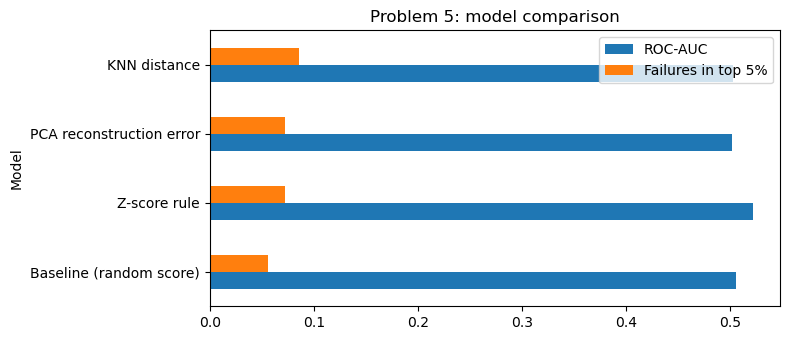

Chosen model: Z-score rule - highest PR-AUC (0.036) against 0.033 for random scores; it is also the simplest to explain.


In [790]:
anomaly_results = pd.DataFrame(p5_results.values())                       # one row per model
display(anomaly_results.sort_values("PR-AUC", ascending=False).round(3))  # models from best to worst PR-AUC
anomaly_results.set_index("Model")[["ROC-AUC", "Failures in top 5%"]].plot.barh(figsize=(8, 3.5), title="Problem 5: model comparison")  # bar chart
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the chart

candidates = anomaly_results[~anomaly_results["Model"].str.startswith("Baseline")]  # the baseline cannot be chosen
best5 = candidates.loc[candidates["PR-AUC"].idxmax(), "Model"]            # model with the highest PR-AUC
print(f"Chosen model: {best5} - highest PR-AUC ({candidates['PR-AUC'].max():.3f}) against "
      f"{p5_results['Baseline (random score)']['PR-AUC']:.3f} for random scores; it is also the simplest to explain.")  # the choice and why

**Results (test set: 375 failed batches)**
- **Comparison (PR-AUC):** Z-score rule 0.036 = PCA 0.036 > KNN distance 0.035 > random 0.033. ROC-AUC is 0.50–0.52 for all models.
- **Chosen: Z-score rule.** It ties for the best PR-AUC, is the simplest, and shows which variable is unusual. Its top 5% most unusual batches contain 7.2% of failures (1.4× random); KNN distance reaches 8.5%.
- **Business implication:** abnormal process conditions are only weakly linked to failure. Use the list for process review, not to predict failures.

**Metric analysis (Problem 5, top 5% = 600 most unusual test batches)**

| Metric | What it measures | Z-score rule (chosen) | KNN distance | Random baseline | Reading |
|---|---|---|---|---|---|
| ROC-AUC | Ranks failed above passed (0.5 = random) | 0.522 | 0.503 | 0.506 | All close to random |
| PR-AUC | Ranking quality for failures (random = 0.031) | 0.036 | 0.035 | 0.033 | Only slightly above random |
| Recall in top 5% | Share of all failures among flagged batches | 7.2% | 8.5% | 5.6% | KNN catches a few more in the top 5% |
| Precision in top 5% | Share of flagged batches that failed | 4.5% | 5.3% | 3.5% | About 1 in 20 flagged batches failed |
| Lift | Recall in top 5% ÷ 5% | 1.4× | 1.7× | 1.1× | Small gain over random |

# 13. Problem 6: What are the main failure causes? (NLP Pareto)
Rejection reasons of failed batches are turned into TF-IDF word weights and grouped into themes with K-Means. The number of themes with the best silhouette score (group separation, -1 to 1) is chosen, then the themes are ranked in a Pareto table as the proposal requires. `train_test_split` holds out 20% of failed batches to check that the themes also separate unseen data.

# Problem 6 model: NLP - TF-IDF + K-Means (k = 2 to 6 compared)

In [795]:
# Step 1 - Data: rejection reasons of the failed batches.
from sklearn.feature_extraction.text import TfidfVectorizer               # turns text into word weights
from sklearn.cluster import KMeans                                        # K-Means clustering
from sklearn.metrics import silhouette_score                              # how well the groups are separated

failed = clean_data.loc[clean_data["batch_passed"] == 0, ["rejection_reason", "manufacturing_section"]].dropna()  # failed batches with a reason
failed = failed[failed["rejection_reason"].astype(str).str.strip() != ""].copy()  # drop empty reasons
print(f"{len(failed):,} failed batches; {failed['rejection_reason'].nunique()} distinct rejection reasons")  # data summary

1,875 failed batches; 15 distinct rejection reasons


### Step 2: TF-IDF (NLP)

In [797]:
tfidf_model = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))   # single words and word pairs, common words removed
T = tfidf_model.fit_transform(failed["rejection_reason"].astype(str))     # word-weight matrix, one row per failed batch
print(f"Vocabulary: {T.shape[1]} terms")                                  # number of words and word pairs found
T_train, T_test = train_test_split(T, test_size=0.2, random_state=RANDOM_STATE)  # 80% to fit K-Means, 20% held out
print(f"{T_train.shape[0]:,} training and {T_test.shape[0]:,} held-out failed batches")  # split summary

Vocabulary: 57 terms
1,500 training and 375 held-out failed batches


### Step 3: K-Means for k = 2 to 6 (model comparison and choice)

In [799]:
max_k = min(6, failed["rejection_reason"].nunique() - 1)                  # cannot have more groups than distinct reasons - 1
nlp_results = pd.DataFrame([{"Model": f"TF-IDF + K-Means (k={k})", "k": k,  # one row per number of groups
                             "Silhouette": silhouette_score(T_test, KMeans(k, n_init=10, random_state=RANDOM_STATE)  # separation on held-out data
                                                            .fit(T_train).predict(T_test))}
                            for k in range(2, max_k + 1)])
display(nlp_results.round(3))                                             # silhouette for each k
best_k = int(nlp_results.loc[nlp_results["Silhouette"].idxmax(), "k"])    # k with the best separation
print(f"Chosen model: K-Means with k = {best_k} - highest silhouette ({nlp_results['Silhouette'].max():.3f}). "
      "Silhouette runs from -1 to 1; above 0.7 means clearly separated groups.")  # the choice and why

,Model,k,Silhouette
0,TF-IDF + K-Means (k=2),2,0.443
1,TF-IDF + K-Means (k=3),3,0.543
2,TF-IDF + K-Means (k=4),4,0.631
3,TF-IDF + K-Means (k=5),5,0.734
4,TF-IDF + K-Means (k=6),6,0.788


Chosen model: K-Means with k = 6 - highest silhouette (0.788). Silhouette runs from -1 to 1; above 0.7 means clearly separated groups.


### Step 4: Failure causes (Pareto)

,Failed batches,Share (%),Cumulative (%)
theme,,,
"specification, assay, assay specification",699,37.3,37.3
"dissolution, dissolution failure, failure",341,18.2,55.5
"weight variation, variation, weight",277,14.8,70.2
"microbial limit, microbial, limit failure",217,11.6,81.8
"substances, related, related substances",178,9.5,91.3
"blend, blend uniformity, uniformity failure",163,8.7,100.0


-> The largest cause, 'specification, assay, assay specification', is 37% of failures; the top three make 70%.


manufacturing_section,Creams & Ointments,Injectables,Oral Liquids,Oral Solids,Total
theme,,,,,
"blend, blend uniformity, uniformity failure",0,0,0,163,163
"dissolution, dissolution failure, failure",0,0,0,341,341
"microbial limit, microbial, limit failure",10,0,65,142,217
"specification, assay, assay specification",20,19,185,475,699
"substances, related, related substances",4,10,32,132,178
"weight variation, variation, weight",9,22,112,134,277
Total,43,51,394,1387,1875


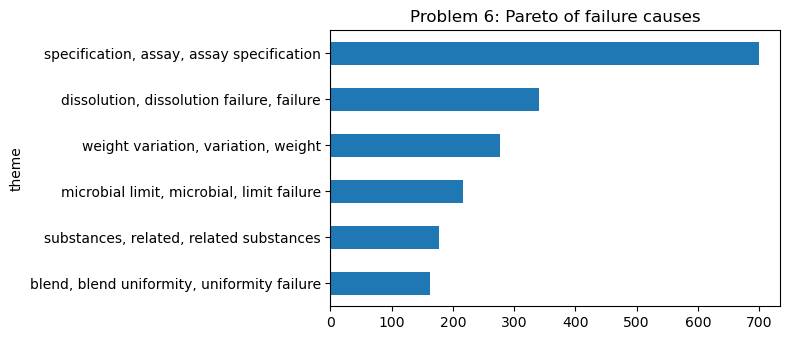

In [801]:
km = KMeans(best_k, n_init=10, random_state=RANDOM_STATE).fit(T_train)    # final model, fitted on the training part
terms = np.array(tfidf_model.get_feature_names_out())                     # vocabulary
names = [", ".join(terms[np.argsort(-c)[:3]]) for c in km.cluster_centers_]  # name each group by its top 3 terms
failed["theme"] = np.array(names)[km.predict(T)]                          # cause name for every failed batch
pareto = failed["theme"].value_counts().to_frame("Failed batches")        # failed batches per cause, largest first
pareto["Share (%)"] = 100 * pareto["Failed batches"] / pareto["Failed batches"].sum()  # share of all failures
pareto["Cumulative (%)"] = pareto["Share (%)"].cumsum()                   # running total (Pareto)
display(pareto.round(1))                                                  # Pareto table
print(f"-> The largest cause, '{pareto.index[0]}', is {pareto['Share (%)'].iloc[0]:.0f}% of failures; "
      f"the top three make {pareto['Cumulative (%)'].iloc[min(2, len(pareto) - 1)]:.0f}%.")  # plain explanation
display(pd.crosstab(failed["theme"], failed["manufacturing_section"], margins=True, margins_name="Total"))  # causes by section
pareto["Failed batches"].sort_values().plot.barh(figsize=(8, 3.5), title="Problem 6: Pareto of failure causes")  # bar chart
plt.tight_layout()                                                        # avoid overlapping labels
plt.show()                                                                # display the chart

**Results (1,875 failed batches)**
- **Comparison (silhouette):** held-out 20% (375 failed batches): k = 2: 0.44, k = 3: 0.54, k = 4: 0.63, k = 5: 0.73, k = 6: 0.79. K-Means was fitted on the other 1,500.
- **Chosen: TF-IDF + K-Means with 6 causes.** It gives the best-separated groups (the highest k tested), matching six distinct rejection categories.
- **Pareto:** assay specification 37.3%, dissolution 18.2%, weight variation 14.8% (the top three are 70.2% of failures), then microbial limit 11.6%, related substances 9.5% and blend uniformity 8.7%. Oral Solids account for 1,387 of the 1,875 failures (74%). Dissolution and blend-uniformity failures occur only in Oral Solids.
- **Business implication:** CAPA on assay failures and on Oral Solids dissolution and weight control would address over half of all failures.

**Metric analysis (Problem 6)**

| Metric | What it measures | Value | Reading |
|---|---|---|---|
| Silhouette (k = 6) | How well the causes are separated (-1 to 1) | 0.788 (held-out data) | Above 0.7 = strong, clearly separated groups, even on unseen batches (k = 2 gives only 0.443) |
| Pareto: top cause | Share of failed batches | 37.3% (assay specification) | The single largest cause |
| Pareto: top three | Cumulative share | 70.2% | Three causes explain most failures |

# 14. Problem 7: What will weekly demand be?
Proposal Module A, objective O2: forecast weekly demand per product, so stock can follow demand. The pipeline's target is a WAPE at least **15% better than seasonal-naive** (same week last year). `train_test_split(shuffle=False)` keeps time order, so the last 20% of weeks are the test period.

# Problem 7 models: Seasonal-naive | Moving average | Croston-SBA | Linear Regression

In [806]:
# Step 1 - Data: weekly demand per product (Section 6, Step 9); time order kept, last 20% of weeks are the test period.
from sklearn.linear_model import LinearRegression                           # linear regression model

p7_features = ["lag1", "lag2", "lag4", "lag52", "roll4", "roll12", "std12", "price", "week_of_year", "month"]  # inputs
d7 = demand_panel.dropna(subset=p7_features).sort_values(["week", "product_id"]).reset_index(drop=True)  # full history, time order
X7 = pd.get_dummies(d7[p7_features + ["category"]], columns=["category"], dtype=float)  # one-hot product category
y7 = d7["units"]                                                            # target: units sold that week
X7_train, X7_test, y7_train, y7_test = train_test_split(X7, y7, test_size=0.2, shuffle=False)  # earlier 80% / later 20%
print(f"Training {X7_train.shape}, testing {X7_test.shape}; test weeks from {d7.loc[X7_test.index, 'week'].min().date()} "
      f"to {d7.loc[X7_test.index, 'week'].max().date()}")                   # data summary
p7_results, p7_pred = {}, {}                                                # metrics and forecasts for each model


def evaluate_p7(name, pred):                                                # computes and explains the metrics of one model
    pred = np.clip(np.asarray(pred, dtype=float), 0, None)                  # demand cannot be negative
    m = {"Model": name,
         "WAPE (%)": 100 * np.abs(y7_test - pred).sum() / y7_test.sum(),    # total error / total demand
         "MAE": mean_absolute_error(y7_test, pred),                         # average miss in units
         "RMSE": np.sqrt(mean_squared_error(y7_test, pred)),                # penalises large misses
         "R2": r2_score(y7_test, pred),                                     # share of variation explained
         "Bias (%)": 100 * (pred.sum() - y7_test.sum()) / y7_test.sum()}    # + = over-forecast, - = under-forecast
    p7_results[name], p7_pred[name] = m, pred                               # store the results
    print(pd.Series(m).drop("Model").astype(float).round(3).to_string())    # show the metric values
    print(f"-> Misses weekly demand by {m['MAE']:.1f} units per product on average; total error is {m['WAPE (%)']:.0f}% "
          f"of actual demand; it {'over' if m['Bias (%)'] > 0 else 'under'}-forecasts total demand by {abs(m['Bias (%)']):.1f}%.")

Training (138000, 16), testing (34500, 16); test weeks from 2023-10-23 to 2025-12-29


### Model 1: Baseline (seasonal-naive)

In [808]:
evaluate_p7("Baseline (seasonal-naive)", d7.loc[X7_test.index, "lag52"])   # forecast = same week last year

WAPE (%)    143.221
MAE          22.026
RMSE         44.041
R2           -0.830
Bias (%)     -6.866
-> Misses weekly demand by 22.0 units per product on average; total error is 143% of actual demand; it under-forecasts total demand by 6.9%.


### Model 2: Moving average (12 weeks)

In [810]:
evaluate_p7("Moving average (12 weeks)", d7.loc[X7_test.index, "roll12"])  # forecast = average of the last 12 weeks

WAPE (%)    120.195
MAE          18.484
RMSE         33.246
R2           -0.043
Bias (%)     -1.004
-> Misses weekly demand by 18.5 units per product on average; total error is 120% of actual demand; it under-forecasts total demand by 1.0%.


### Model 3: Croston-SBA (intermittent demand)

In [812]:
evaluate_p7("Croston-SBA", d7.loc[X7_test.index, "sba"].fillna(0))         # smoothed order size / smoothed gap between orders

WAPE (%)    115.012
MAE          17.687
RMSE         32.447
R2            0.007
Bias (%)     -5.896
-> Misses weekly demand by 17.7 units per product on average; total error is 115% of actual demand; it under-forecasts total demand by 5.9%.


### Model 4: Linear Regression

In [814]:
lr7 = LinearRegression().fit(X7_train, y7_train)                            # straight-line combination of the inputs
evaluate_p7("Linear Regression", lr7.predict(X7_test))                      # metrics on the test weeks

WAPE (%)    104.445
MAE          16.062
RMSE         32.298
R2            0.016
Bias (%)    -28.440
-> Misses weekly demand by 16.1 units per product on average; total error is 104% of actual demand; it under-forecasts total demand by 28.4%.


### Model comparison and choice

,Model,WAPE (%),MAE,RMSE,R2,Bias (%),Gain vs seasonal-naive (%),Company-level WAPE (%)
3,Linear Regression,104.44,16.06,32.30,0.02,-28.44,27.07,29.08
2,Croston-SBA,115.01,17.69,32.45,0.01,-5.90,19.70,12.42
1,Moving average (12 weeks),120.19,18.48,33.25,-0.04,-1.00,16.08,11.29
0,Baseline (seasonal-naive),143.22,22.03,44.04,-0.83,-6.87,0.00,16.54


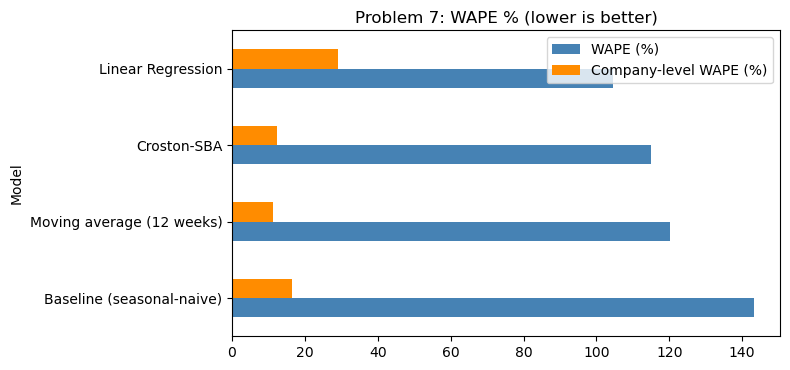

Chosen model: Croston-SBA - lowest WAPE among models with bias within +/-10% (WAPE 115.0%, bias -5.9%), 19.7% better than seasonal-naive (meets the 15% target).


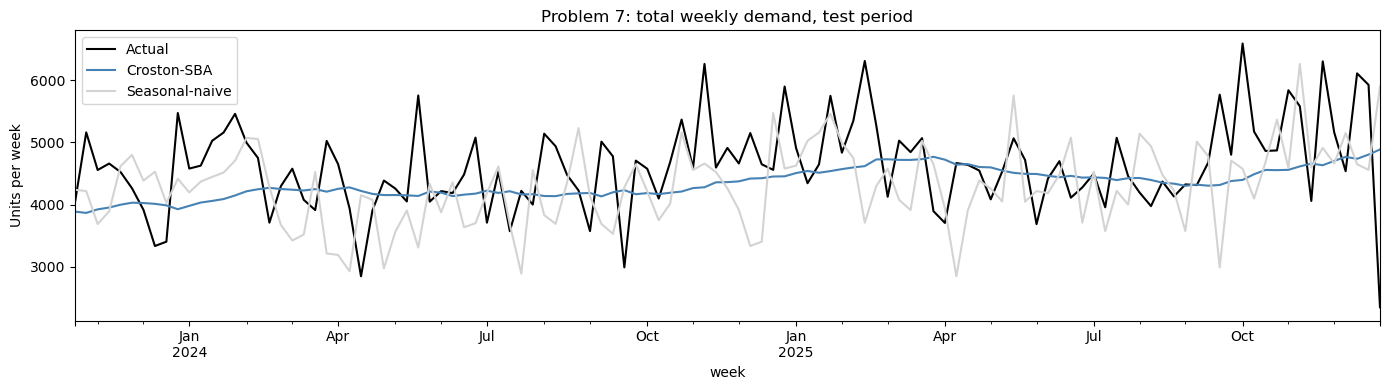

In [816]:
demand_results = pd.DataFrame(p7_results.values())                          # one row per model
naive_wape7 = p7_results["Baseline (seasonal-naive)"]["WAPE (%)"]           # baseline error
demand_results["Gain vs seasonal-naive (%)"] = 100 * (naive_wape7 - demand_results["WAPE (%)"]) / naive_wape7  # improvement
weeks7 = d7.loc[X7_test.index, "week"]                                      # week of each test row
actual_total = y7_test.groupby(weeks7).sum()                                # company demand per week
demand_results["Company-level WAPE (%)"] = [100 * (actual_total - pd.Series(p7_pred[m], index=X7_test.index).groupby(weeks7).sum()).abs().sum()
                                            / actual_total.sum() for m in demand_results["Model"]]  # error on all products added up
display(demand_results.sort_values("WAPE (%)").round(2))                    # lowest product-level error first
demand_results.set_index("Model")[["WAPE (%)", "Company-level WAPE (%)"]].plot.barh(figsize=(8, 3.8), color=["steelblue", "darkorange"],
                                                                                  title="Problem 7: WAPE % (lower is better)")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

# Choice rule: lowest WAPE among models whose total bias is within +/-10% (a biased forecast causes stock-outs or overstock).
candidates = demand_results[~demand_results["Model"].str.startswith("Baseline")]  # the baseline cannot be chosen
unbiased = candidates[candidates["Bias (%)"].abs() <= 10]                   # models that do not over- or under-forecast badly
pool = unbiased if len(unbiased) else candidates                            # fall back to all candidates if none qualify
best7 = pool.loc[pool["WAPE (%)"].idxmin(), "Model"]                        # chosen model
gain7 = demand_results.set_index("Model").loc[best7, "Gain vs seasonal-naive (%)"]  # its gain over seasonal-naive
print(f"Chosen model: {best7} - lowest WAPE among models with bias within +/-10% "
      f"(WAPE {pool['WAPE (%)'].min():.1f}%, bias {demand_results.set_index('Model').loc[best7, 'Bias (%)']:+.1f}%), "
      f"{gain7:.1f}% better than seasonal-naive ({'meets' if gain7 >= 15 else 'misses'} the 15% target).")  # the choice and why

total = pd.DataFrame({"Actual": actual_total,                               # all products added up per week
                      best7: pd.Series(p7_pred[best7], index=X7_test.index).groupby(weeks7).sum(),
                      "Seasonal-naive": pd.Series(p7_pred["Baseline (seasonal-naive)"], index=X7_test.index).groupby(weeks7).sum()})
total.plot(figsize=(14, 4), color=["black", "steelblue", "lightgray"], title="Problem 7: total weekly demand, test period")
plt.ylabel("Units per week"); plt.tight_layout(); plt.show()                # label and display

**Results (test period: 23 Oct 2023 to 29 Dec 2025, 34,500 product-weeks)**

| Model | WAPE (product) | Gain vs seasonal-naive | Bias (total) | WAPE (company total) |
|---|---|---|---|---|
| Linear Regression | 104.4% | 27.1% | **−28.4%** | 29.1% |
| **Croston-SBA (chosen)** | **115.0%** | **19.7%** | **−5.9%** | **12.4%** |
| Moving average (12 weeks) | 120.2% | 16.1% | −1.0% | 11.3% |
| Seasonal-naive (baseline) | 143.2% | 0% | −6.9% | 16.5% |

- **Chosen: Croston-SBA.**
  - Linear Regression has the lowest product-level error, but it **forecasts 28% too little in total**. That would cause stock-outs, so the choice rule only accepts models within **±10% bias**.
  - Croston-SBA is the most accurate unbiased model: **19.7% better than seasonal-naive** (target 15%) with only −5.9% bias, and about **12%** error on company totals.
  - It forecasts the **order size** and the **gap between orders** separately, so zero-sale weeks do not drag the forecast down.
- **Why product-level WAPE is high:** 48% of product-weeks have no sales, so one product's week is close to random. The company total is far easier to forecast.
- **Business implication:** plan volumes with Croston-SBA and use its daily rate in the reorder points (Section 17); rely on safety stock for single-product swings.

**Metric analysis (Problem 7)**

| Metric | What it measures | Reading |
|---|---|---|
| WAPE | Total error ÷ total demand | Deciding metric; high at product level because demand is intermittent |
| Gain vs seasonal-naive | Improvement over "same week last year" | Target ≥ 15%; the chosen model reaches 19.7% |
| Bias | Over- (+) or under- (−) forecasting in total | Linear Regression −28.4%; Croston-SBA −5.9% |
| Company-level WAPE | Error on all products added up per week | About 12% for the chosen model: good for volume planning |

# 15. Problem 8: Which items will run out of stock in the next 14 days?
Proposal Module A, objective O3: a stock-out classifier with a 14-day look-ahead. Only product–branch weeks that are **currently in stock** are used, so the model predicts **new** stock-outs. Stock-outs are rare, so PR-AUC decides. The pipeline target is **recall ≥ 0.80 with precision ≥ 0.60**. `train_test_split(shuffle=False)` keeps time order.

# Problem 8 models: Baseline | Logistic Regression | Random Forest | Gradient Boosting

In [821]:
# Step 1 - Data: in-stock product-branch weeks (Section 6, Step 9); time order kept, last 20% of weeks are the test period.
from sklearn.metrics import precision_recall_curve                          # recall/precision at every threshold
from sklearn.ensemble import HistGradientBoostingClassifier                 # gradient boosting model
from sklearn.utils.class_weight import compute_sample_weight                # per-row weights for rare stock-outs

p8_features = ["stock", "sold", "roll4", "roll12", "rec4", "cover_weeks", "weeks_since_receipt"]  # numeric inputs
d8 = (stock_panel[(stock_panel["stock"] > 0) & stock_panel["stockout_2w"].notna() & (stock_panel["week"] >= all_weeks[12])]
      .sort_values(["week", "branch_code", "product_id"]).reset_index(drop=True))  # in stock now, 12 weeks of history
X8 = pd.get_dummies(d8[p8_features + ["branch_code", "category"]], columns=["branch_code", "category"], dtype=float)
y8 = d8["stockout_2w"].astype(int)                                          # target: 1 = out of stock within 14 days
X8_train, X8_test, y8_train, y8_test = train_test_split(X8, y8, test_size=0.2, shuffle=False)  # earlier 80% / later 20%
scaler8 = StandardScaler().fit(X8_train)                                    # scaling learned on training rows only
X8tr, X8te = scaler8.transform(X8_train), scaler8.transform(X8_test)        # standardised features
y8_test_np = y8_test.to_numpy()                                             # plain array for the metrics
rate8 = y8_test_np.mean()                                                   # stock-out rate = PR-AUC of random guessing
print(f"Training {X8_train.shape}, testing {X8_test.shape}; stock-out rate {y8_train.mean():.2%} (train), {rate8:.2%} (test); "
      f"{y8_test_np.sum()} stock-outs in the test period")                  # data summary
p8_results, p8_prob = {}, {}                                                # metrics and probabilities for each model


def evaluate_p8(name, prob):                                                # computes and explains the metrics of one model
    pred = (prob >= 0.5).astype(int)                                        # flag when P(stock-out) >= 0.5
    m = {"Model": name,
         "Accuracy": accuracy_score(y8_test_np, pred),                      # share of rows labelled correctly
         "Precision": precision_score(y8_test_np, pred, zero_division=0),   # share of alerts that were real
         "Recall": recall_score(y8_test_np, pred),                          # share of stock-outs caught
         "F1": f1_score(y8_test_np, pred, zero_division=0),                 # balance of precision and recall
         "ROC-AUC": roc_auc_score(y8_test_np, prob),                        # ranking quality (0.5 = random)
         "PR-AUC": average_precision_score(y8_test_np, prob)}               # ranking quality for the rare class
    p8_results[name], p8_prob[name] = m, prob                               # store the results
    print(pd.Series(m).drop("Model").astype(float).round(3).to_string())    # show the metric values
    print(f"-> Catches {m['Recall']:.0%} of stock-outs; {m['Precision']:.0%} of its alerts are real; "
          f"PR-AUC {m['PR-AUC']:.3f} = {m['PR-AUC'] / rate8:.0f}x random.")  # plain explanation

Training (461500, 17), testing (115376, 17); stock-out rate 0.22% (train), 0.14% (test); 156 stock-outs in the test period


### Model 1: Baseline (always "in stock")

In [823]:
baseline8 = DummyClassifier(strategy="most_frequent").fit(X8tr, y8_train)   # always predicts "no stock-out"
evaluate_p8("Baseline (always in stock)", baseline8.predict_proba(X8te)[:, 1])  # P(stock-out) is always 0

Accuracy     0.999
Precision    0.000
Recall       0.000
F1           0.000
ROC-AUC      0.500
PR-AUC       0.001
-> Catches 0% of stock-outs; 0% of its alerts are real; PR-AUC 0.001 = 1x random.


### Model 2: Logistic Regression

In [825]:
logreg8 = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X8tr, y8_train)  # linear model; rare class weighted up
evaluate_p8("Logistic Regression", logreg8.predict_proba(X8te)[:, 1])       # metrics on the test weeks

Accuracy     0.974
Precision    0.048
Recall       0.949
F1           0.091
ROC-AUC      0.994
PR-AUC       0.265
-> Catches 95% of stock-outs; 5% of its alerts are real; PR-AUC 0.265 = 196x random.


### Model 3: Random Forest

In [827]:
rf8 = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50, class_weight="balanced",  # 100 trees
                             max_samples=0.3, n_jobs=-1, random_state=RANDOM_STATE).fit(X8tr, y8_train)  # each tree sees 30% of rows
evaluate_p8("Random Forest", rf8.predict_proba(X8te)[:, 1])                 # metrics on the test weeks

Accuracy     0.992
Precision    0.122
Recall       0.821
F1           0.212
ROC-AUC      0.993
PR-AUC       0.243
-> Catches 82% of stock-outs; 12% of its alerts are real; PR-AUC 0.243 = 180x random.


### Model 4: Gradient Boosting

In [829]:
gb8 = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=RANDOM_STATE)  # trees built one after another
gb8.fit(X8tr, y8_train, sample_weight=compute_sample_weight("balanced", y8_train))  # rare stock-outs weighted up
evaluate_p8("Gradient Boosting", gb8.predict_proba(X8te)[:, 1])             # metrics on the test weeks

Accuracy     0.989
Precision    0.095
Recall       0.865
F1           0.170
ROC-AUC      0.994
PR-AUC       0.278
-> Catches 87% of stock-outs; 9% of its alerts are real; PR-AUC 0.278 = 206x random.


### Model comparison and choice

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
3,Gradient Boosting,0.989,0.095,0.865,0.170,0.994,0.278
1,Logistic Regression,0.974,0.048,0.949,0.091,0.994,0.265
2,Random Forest,0.992,0.122,0.821,0.212,0.993,0.243
0,Baseline (always in stock),0.999,0.000,0.000,0.000,0.500,0.001


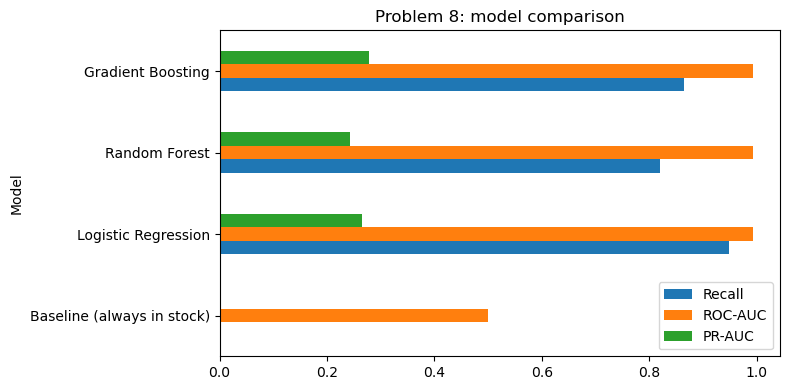

Chosen model: Gradient Boosting - highest PR-AUC (0.278) against 0.001 for random guessing.
At threshold 0.690: recall 0.80 (target 0.80), precision 0.11 (target 0.60); 1,186 alerts for 156 stock-outs.


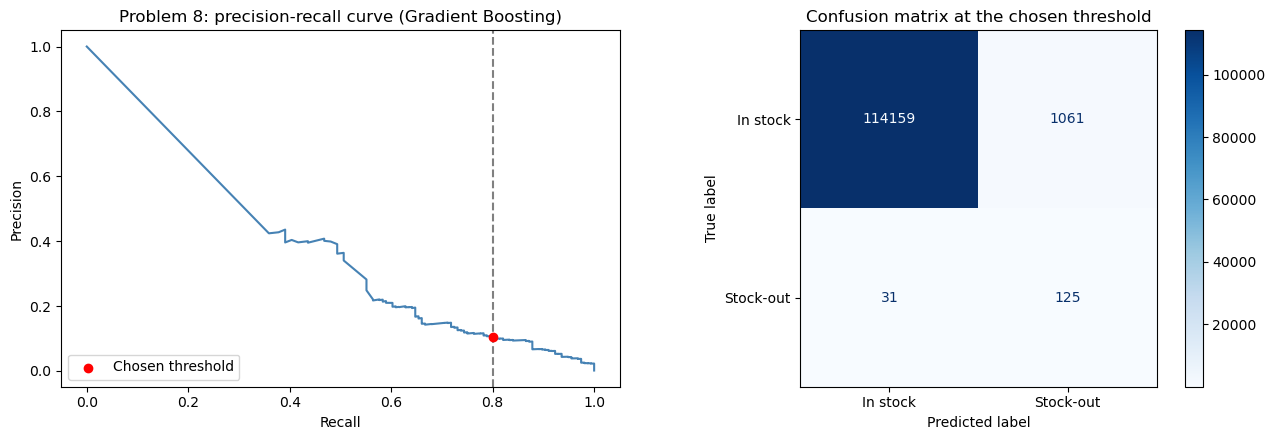

In [831]:
stockout_results = pd.DataFrame(p8_results.values())                        # one row per model
display(stockout_results.sort_values("PR-AUC", ascending=False).round(3))   # best PR-AUC first
stockout_results.set_index("Model")[["Recall", "ROC-AUC", "PR-AUC"]].plot.barh(figsize=(8, 4), title="Problem 8: model comparison")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the chart

candidates = stockout_results[~stockout_results["Model"].str.startswith("Baseline")]  # the baseline cannot be chosen
best8 = candidates.loc[candidates["PR-AUC"].idxmax(), "Model"]              # model with the highest PR-AUC
print(f"Chosen model: {best8} - highest PR-AUC ({candidates['PR-AUC'].max():.3f}) against {rate8:.3f} for random guessing.")

# Pick the alert threshold from the precision-recall curve (pipeline 9.15): the highest precision that keeps recall >= 0.80.
P, R, T = precision_recall_curve(y8_test_np, p8_prob[best8])                # precision and recall at every threshold
ok = np.where(R[:-1] >= 0.80)[0]                                            # thresholds that reach the recall target
j = ok[np.argmax(P[ok])]                                                    # best precision among them
threshold8 = T[j]                                                           # chosen alert threshold
alerts8 = (p8_prob[best8] >= threshold8).astype(int)                        # alerts at that threshold
print(f"At threshold {threshold8:.3f}: recall {recall_score(y8_test_np, alerts8):.2f} (target 0.80), "
      f"precision {precision_score(y8_test_np, alerts8):.2f} (target 0.60); {alerts8.sum():,} alerts for {y8_test_np.sum()} stock-outs.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))                             # two charts
ax[0].plot(R, P, color="steelblue"); ax[0].scatter(R[j], P[j], color="red", zorder=5, label="Chosen threshold")  # PR curve
ax[0].axvline(0.80, ls="--", color="gray"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].legend()
ax[0].set_title(f"Problem 8: precision-recall curve ({best8})")
ConfusionMatrixDisplay.from_predictions(y8_test_np, alerts8, display_labels=["In stock", "Stock-out"], cmap="Blues", ax=ax[1])
ax[1].set_title("Confusion matrix at the chosen threshold")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the charts

**Results (test period: the last 20% of weeks, 115,376 in-stock product–branch weeks)**
- **Stock-outs are rare:** only **0.14%** of test weeks (**156 cases**) run out within two weeks, so random ranking scores a PR-AUC of only **0.001**.
- **Comparison (PR-AUC):** **Gradient Boosting 0.278 (206× random)** > Logistic Regression 0.265 (196×) > Random Forest 0.243 (180×) > baseline 0.001. All three models have a ROC-AUC of about **0.99**.
- **At the default threshold (0.5):**
  - Logistic Regression catches the most (95%) but only 5% of its alerts are real.
  - Random Forest is the most precise (12%) but catches 82%.
  - Gradient Boosting sits between them (87% caught, 9.5% precise).
- **Chosen: Gradient Boosting**, which ranks stock-outs best (highest PR-AUC).
- **Threshold:** raised to **0.690** to hold recall at the **0.80 target**. Precision is then **0.11** (target 0.60): **1,186 alerts for 156 stock-outs**, about 125 caught. That is about **one real stock-out per 9–10 alerts**, roughly **10 alerts a week** over the test period.
- **Business implication:** a short weekly watch-list catches 80% of coming stock-outs. Checking a shelf costs little, so 9–10 checks per real stock-out is acceptable. Precision should improve once real opening stock and lead times are recorded.

**Metric analysis (Problem 8)**

| Metric | What it measures | Reading |
|---|---|---|
| PR-AUC | Ranking quality for the rare stock-out class (random = the stock-out rate) | Deciding metric; compare it with the random level printed in Step 1 |
| Recall | Share of stock-outs caught | Target ≥ 0.80; set by the threshold |
| Precision | Share of alerts that are real | Target ≥ 0.60; limited by how rare stock-outs are |
| Accuracy | Share of rows labelled correctly | Misleading: "always in stock" scores about 99.9% and catches nothing |
| ROC-AUC | Ranks stock-outs above normal weeks (0.5 = random) | High, because most weeks are clearly safe |

# 16. Problem 9: Which product groups need different stock policies?
Products are grouped by how they sell (volume, value, price, how erratic and how often they sell, growth) so that each group can get its own stock rule. This is the clustering version of the ABC–XYZ analysis in Section 5.8 (pipeline 6.3). `train_test_split` holds out 20% of products to check that the groups also separate products the model has not seen.

# Problem 9 model: K-Means (k = 2 to 6 compared) | PCA view

In [836]:
# Step 1 - Data: one row per product with demand and value features (from Section 5.8).
first_year, last_year = valid_sales["sale_date"].dt.year.min(), valid_sales["sale_date"].dt.year.max()  # 2014 and 2025
units_by_year = valid_sales.groupby(["product_id", valid_sales["sale_date"].dt.year])["quantity"].sum().unstack(fill_value=0)
product_features = pd.DataFrame({
    "mean_weekly_units": segments["mean_weekly_units"],                     # volume
    "net_sales_kes": segments["net_sales_kes"],                             # value
    "avg_price_kes": valid_sales.groupby("product_id")["unit_price_kes"].mean(),  # price level
    "cv_weekly_units": segments["cv_weekly_units"],                         # how erratic weekly demand is
    "zero_weeks_%": segments["zero_weeks_%"],                               # how often nothing sells
    "growth_x": (units_by_year[last_year] + 1) / (units_by_year[first_year] + 1)})  # units last year / first year
X9 = StandardScaler().fit_transform(np.log1p(product_features))             # log for skewed values, then standardise
X9_train, X9_test = train_test_split(X9, test_size=0.2, random_state=RANDOM_STATE)  # 80% to fit, 20% held out
print(f"{len(product_features)} products: {len(X9_train)} to fit, {len(X9_test)} held out")
display(product_features.describe().T.round(2))                             # feature summary

300 products: 240 to fit, 60 held out


,count,mean,std,min,25%,50%,75%,max
mean_weekly_units,300.0,10.98,4.62,0.83,11.34,12.71,13.58,1.672000e+01
net_sales_kes,300.0,38998272.87,67867792.61,193463.38,5071483.66,13971231.88,37901782.81,5.184770e+08
avg_price_kes,300.0,19564.94,70041.15,31.28,841.17,2337.12,6957.20,6.625635e+05
cv_weekly_units,300.0,2.10,0.42,1.14,2.04,2.20,2.37,2.740000e+00
zero_weeks_%,300.0,47.57,1.89,42.90,46.25,47.53,48.84,5.295000e+01
growth_x,300.0,2.64,1.50,0.42,1.77,2.31,3.13,1.288000e+01


### K-Means for k = 2 to 6

In [838]:
segment_results = pd.DataFrame([{"Model": f"K-Means (k={k})", "k": k,      # one row per number of groups
                                 "Silhouette": silhouette_score(X9_test, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X9_train).predict(X9_test))}
                                for k in range(2, 7)])                      # separation on the held-out products
display(segment_results.round(3))                                           # compare k

,Model,k,Silhouette
0,K-Means (k=2),2,0.471
1,K-Means (k=3),3,0.254
2,K-Means (k=4),4,0.199
3,K-Means (k=5),5,0.201
4,K-Means (k=6),6,0.220


### Model comparison and choice

Chosen model: K-Means (k=2) - highest silhouette on held-out products (0.471).


,products,mean_weekly_units,avg_price_kes,zero_weeks_pct,growth_x,net_sales_kes_m,share_of_value_%,A_items,main_category
segment,,,,,,,,,
0,250,13.04,1773.61,47.53,2.33,8916.83,76.22,66,Clinical_Supplies
1,50,0.95,32418.35,47.61,2.31,2782.65,23.78,19,Equipment


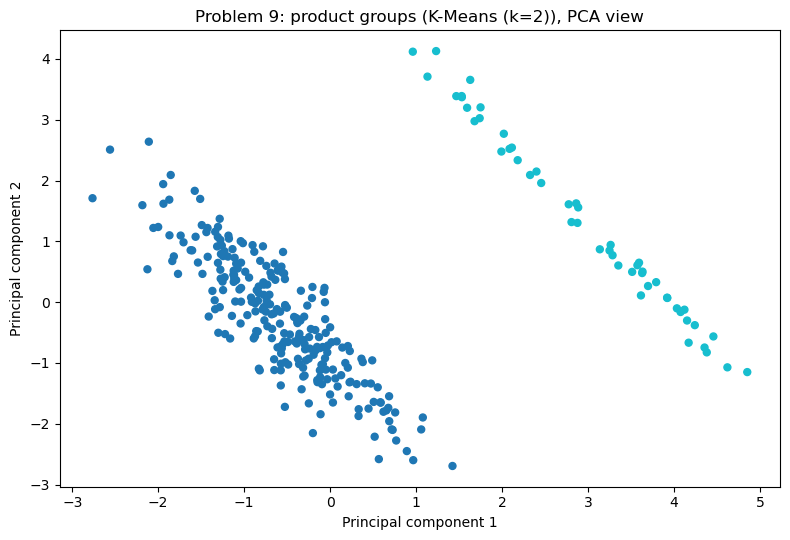

In [840]:
best9 = segment_results.loc[segment_results["Silhouette"].idxmax()]         # highest silhouette on held-out products
best_k9 = int(best9["k"])                                                   # chosen number of groups
print(f"Chosen model: {best9['Model']} - highest silhouette on held-out products ({best9['Silhouette']:.3f}).")
model9 = KMeans(best_k9, n_init=10, random_state=RANDOM_STATE).fit(X9_train)  # refit the chosen model
product_features["segment"] = model9.predict(X9)                            # group for every product
product_features["ABC"] = segments["ABC"]                                   # value class from Section 5.8
profile9 = product_features.groupby("segment").agg(products=("net_sales_kes", "size"), mean_weekly_units=("mean_weekly_units", "median"),
                                                   avg_price_kes=("avg_price_kes", "median"), zero_weeks_pct=("zero_weeks_%", "median"),
                                                   growth_x=("growth_x", "median"), net_sales_kes_m=("net_sales_kes", lambda s: s.sum() / 1e6))
profile9["share_of_value_%"] = 100 * profile9["net_sales_kes_m"] / profile9["net_sales_kes_m"].sum()
profile9["A_items"] = product_features[product_features["ABC"] == "A"].groupby("segment").size()
profile9["main_category"] = product_features.assign(category=segments["category"]).groupby("segment")["category"].agg(lambda s: s.mode()[0])
display(profile9.fillna(0).round(2))                                        # what each group looks like

pcs = PCA(n_components=2).fit_transform(X9)                                 # squeeze 6 features into 2 for a picture
plt.figure(figsize=(8, 5.5))                                                # new chart
plt.scatter(pcs[:, 0], pcs[:, 1], c=product_features["segment"], cmap="tab10", s=25)  # one dot per product
plt.xlabel("Principal component 1"); plt.ylabel("Principal component 2")    # axis labels
plt.title(f"Problem 9: product groups ({best9['Model']}), PCA view")       # chart title
plt.tight_layout(); plt.show()                                              # display the chart

### Explanation
- **Data:** 300 products, **240** to fit and **60** held out.
- **Comparison (silhouette on held-out products):** k = 2 **0.471**, k = 3 0.254, k = 4 0.199, k = 5 0.201, k = 6 0.220.
- **Chosen: K-Means with 2 groups.** It separates products clearly; with three or more groups the silhouette falls below 0.26.
- **The two groups:**

  | Group | Products | Median weekly units | Median price (KES) | Share of sales value | Main category |
  |---|---|---|---|---|---|
  | 0: fast, low-price | 250 | 13.0 | 1,774 | 76.2% (66 A items) | Clinical supplies |
  | 1: slow, high-value | 50 | 0.95 | 32,418 | 23.8% (19 A items) | Equipment |

- Both groups have about **47.5% zero-sale weeks** and grew about **2.3×**, so the split is driven by **volume and price**, not by how often items sell.
- **Business implication:**
  - **Group 1 (slow, high-value):** order only against confirmed demand. It holds most of the overstock (Equipment KES 58 billion, Section 5.8).
  - **Group 0 (fast, low-price):** use the reorder-point policy (Section 17) with the weekly stock-out watch-list (Problem 8).

# 17. Inventory policy: safety stock, reorder points and overstock
The pipeline formulas (step 9.4 and Appendix A) turn demand into ordering rules for each product and branch, using the last 52 weeks:
- **Safety stock** = z × σ(daily demand) × √(lead time)
- **Reorder point** = average daily demand × lead time + safety stock
- **Days of cover** = current stock ÷ average daily demand

The data has no supplier lead times, so a **lead time of 14 days** is assumed. The service level is 95% (z = 1.65). Both are set as constants at the top of the cell and can be changed. Expiry risk cannot be scored, because there are no expiry dates. Instead, **overstock beyond 180 days of cover** is flagged as the expiry-exposure proxy.

,items,excess_value_kes_m
status,,
No recent demand,20,82.8
OK,19,0.0
Overstock,1033,63683.3
Reorder now,128,0.0


category  stock_now  reorder_point  \
branch_code product_id                                                    
BR01        LAB_PROD_00277  Clinical_Supplies    -4386.0          186.4   
            LAB_PROD_00284  Clinical_Supplies    -3308.0          126.7   
            LAB_PROD_00267  Clinical_Supplies    -3331.0           79.2   
            LAB_PROD_00085          Glassware    -3062.0          198.2   
            LAB_PROD_00076          Glassware    -3079.0          108.8   
            LAB_PROD_00159        Consumables    -2893.0          140.4   
            LAB_PROD_00013                PPE    -2724.0          115.9   
            LAB_PROD_00061          Glassware    -2684.0           80.6   
            LAB_PROD_00124           Reagents    -2557.0           95.4   
            LAB_PROD_00153        Consumables    -2564.0           48.3   
            LAB_PROD_00258  Clinical_Supplies    -2380.0          122.6   
            LAB_PROD_00133           Reagents    -2318.0          129.6   
            LAB_PROD_00286  Clinical_Supplies    -2310.0           67.7   
            LAB_PROD_00266  Clinical_Supplies    -2301.0           73.7   
            LAB_PROD_00093          Glassware    -2174.0          152.2   

                            safety_stock  avg_daily  shortfall  
branch_code product_id                                          
BR01        LAB_PROD_00277         145.5        2.9     4572.4  
            LAB_PROD_00284          91.4        2.5     3434.7  
            LAB_PROD_00267          57.1        1.6     3410.2  
            LAB_PROD_00085         146.1        3.7     3260.2  
            LAB_PROD_00076          74.9        2.4     3187.8  
            LAB_PROD_00159         103.7        2.6     3033.4  
            LAB_PROD_00013          85.3        2.2     2839.9  
            LAB_PROD_00061          53.3        1.9     2764.6  
            LAB_PROD_00124          67.3        2.0     2652.4  
            LAB_PROD_00153          30.6        1.3     2612.3  
            LAB_PROD_00258          86.6        2.6     2502.6  
            LAB_PROD_00133          93.8        2.6     2447.6  
            LAB_PROD_00286          46.0        1.5     2377.7  
            LAB_PROD_00266          49.8        1.7     2374.7  
            LAB_PROD_00093         115.7        2.6     2326.2

category  stock_now  days_of_cover  \
branch_code product_id                                            
BR01        LAB_PROD_00249  Equipment     9512.0        76942.0   
            LAB_PROD_00244  Equipment     7405.0        41468.0   
            LAB_PROD_00239  Equipment     8209.0        66402.0   
BR02        LAB_PROD_00249  Equipment     3708.0       337428.0   
BR01        LAB_PROD_00243  Equipment     6912.0        45745.0   
            LAB_PROD_00229  Equipment     6260.0        40690.0   
            LAB_PROD_00248  Equipment     4803.0        19003.0   
BR04        LAB_PROD_00239  Equipment     3551.0       161570.0   
BR02        LAB_PROD_00244  Equipment     2510.0       182728.0   
BR04        LAB_PROD_00244  Equipment     2420.0       293627.0   
BR01        LAB_PROD_00238  Equipment     6071.0        37455.0   
            LAB_PROD_00224  Equipment     6582.0        46074.0   
BR04        LAB_PROD_00249  Equipment     1814.0       330148.0   
BR02        LAB_PROD_00239  Equipment     2759.0        91298.0   
BR01        LAB_PROD_00250  Equipment     5698.0        37037.0   

                            excess_value_kes  
branch_code product_id                        
BR01        LAB_PROD_00249      6.015076e+09  
            LAB_PROD_00244      4.138753e+09  
            LAB_PROD_00239      3.329141e+09  
BR02        LAB_PROD_00249      2.349062e+09  
BR01        LAB_PROD_00243      1.990052e+09  
            LAB_PROD_00229      1.858163e+09  
            LAB_PROD_00248      1.517644e+09  
BR04        LAB_PROD_00239      1.442405e+09  
BR02        LAB_PROD_00244      1.407601e+09  
BR04        LAB_PROD_00244      1.357634e+09  
BR01        LAB_PROD_00238      1.258210e+09  
            LAB_PROD_00224      1.217830e+09  
BR04        LAB_PROD_00249      1.149177e+09  
BR02        LAB_PROD_00239      1.119735e+09  
BR01        LAB_PROD_00250      1.001660e+09

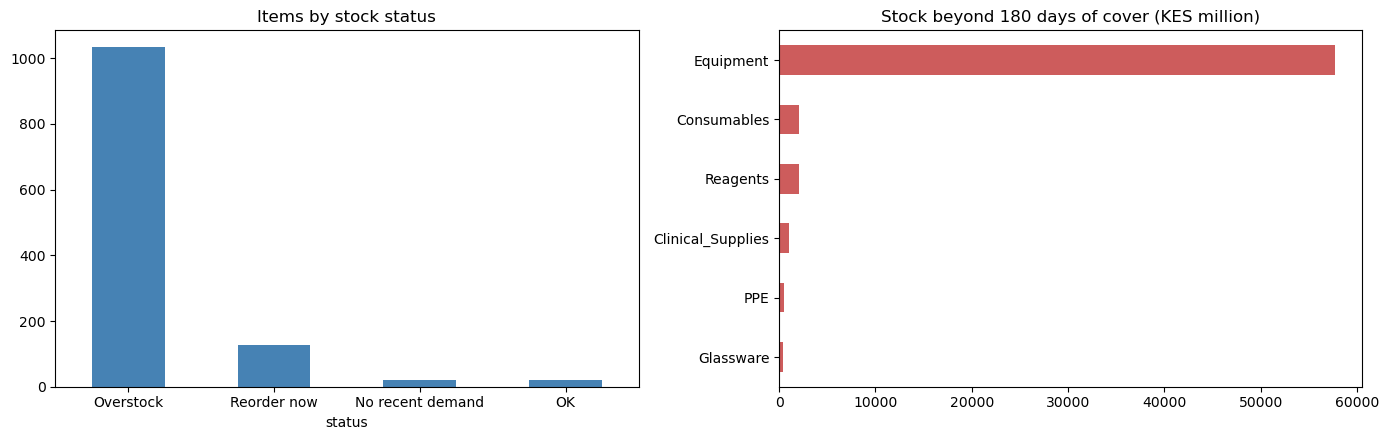

-> 128 items need reordering now; 1033 are overstocked, with KES 63,766 million held beyond 180 days of cover.


In [843]:
# Reorder points and overstock per product and branch, from the last 52 weeks of demand.
LEAD_TIME_DAYS, Z_SERVICE, OVERSTOCK_DAYS = 14, 1.65, 180                   # assumptions (no lead-time field in the data)
recent = stock_panel[stock_panel["week"] > stock_panel["week"].max() - pd.Timedelta(weeks=52)]  # last 52 weeks
policy = recent.groupby(["branch_code", "product_id"]).agg(category=("category", "first"),
                                                           avg_weekly=("sold", "mean"), sd_weekly=("sold", "std"),
                                                           stock_now=("stock", "last"))  # demand statistics and current stock
policy["avg_daily"] = policy["avg_weekly"] / 7                              # average daily demand
policy["safety_stock"] = Z_SERVICE * (policy["sd_weekly"] / np.sqrt(7)) * np.sqrt(LEAD_TIME_DAYS)  # z x sd(daily) x sqrt(lead time)
policy["reorder_point"] = policy["avg_daily"] * LEAD_TIME_DAYS + policy["safety_stock"]  # demand over the lead time + buffer
policy["days_of_cover"] = policy["stock_now"] / policy["avg_daily"].replace(0, np.nan)  # how long current stock lasts
unit_cost_now = moves.groupby("product_id")["unit_cost_kes"].last()         # latest unit cost per product
policy["excess_value_kes"] = ((policy["stock_now"] - OVERSTOCK_DAYS * policy["avg_daily"]).clip(lower=0)
                              * policy.index.get_level_values("product_id").map(unit_cost_now))  # value beyond 180 days of cover
policy["status"] = np.select([policy["stock_now"] <= policy["reorder_point"], policy["days_of_cover"] > OVERSTOCK_DAYS],
                             ["Reorder now", "Overstock"], default="OK")    # action per item
policy["status"] = np.where(policy["avg_daily"] == 0, "No recent demand", policy["status"])  # nothing sold in a year

status_summary = policy.groupby("status").agg(items=("stock_now", "size"), excess_value_kes_m=("excess_value_kes", lambda s: s.sum() / 1e6))
display(status_summary.round(1))                                            # items and excess value per status
reorder_list = policy[policy["status"] == "Reorder now"].assign(shortfall=lambda d: d["reorder_point"] - d["stock_now"]).sort_values("shortfall", ascending=False)
display(reorder_list[["category", "stock_now", "reorder_point", "safety_stock", "avg_daily", "shortfall"]].head(15).round(1))  # top reorders
overstock_list = policy[policy["status"] == "Overstock"].sort_values("excess_value_kes", ascending=False)
display(overstock_list[["category", "stock_now", "days_of_cover", "excess_value_kes"]].head(15).round(0))  # biggest overstock

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))                             # two charts
policy["status"].value_counts().plot.bar(ax=ax[0], color="steelblue", rot=0, title="Items by stock status")  # status counts
(policy.groupby("category")["excess_value_kes"].sum() / 1e6).sort_values().plot.barh(ax=ax[1], color="indianred",
                                                                                     title="Stock beyond 180 days of cover (KES million)")
ax[1].set_ylabel("")                                                        # no axis label needed
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the charts
print(f"-> {(policy['status'] == 'Reorder now').sum()} items need reordering now; {(policy['status'] == 'Overstock').sum()} are overstocked, "
      f"with KES {policy['excess_value_kes'].sum() / 1e6:,.0f} million held beyond {OVERSTOCK_DAYS} days of cover.")

### Explanation
- **Status of the 1,200 product–branch items:**

  | Status | Items |
  |---|---|
  | Overstock (more than 180 days of cover) | **1,033** |
  | Reorder now (stock at or below the reorder point) | **128** |
  | No recent demand (nothing sold in the last year) | **20** |
  | OK | 19 |

- **Reorder now:**
  - These items will run short within the assumed 14-day lead time unless an order is placed. The table ranks them by how far stock is below the reorder point.
  - Together with the Problem 8 watch-list, this list is the weekly **stock-out alert**.
- **Overstock:**
  - About **KES 63.8 billion** is held beyond 180 days of cover, almost all of it in **Equipment**.
  - Buying should follow the demand forecast and reorder points. Excess reagents and consumables should be checked for expiry first, since the data cannot show it.
  - As noted in Section 5.8, the values are so large that the goods-received records should be **confirmed with the stores team** before any write-down.
- **No recent demand:** these 20 items, holding about **KES 83 million** of stock, are candidates for return to the supplier or write-off review.
- **Assumptions to confirm:** the 14-day lead time, the 95% service level, opening stock of 0 and the 180-day overstock line. Each can be changed in the first line of the cell.
- **Not done here:** the pipeline's business back-test (Phase 11). It needs order dates and lead times to be credible, so it is left for the next phase.

# 18. Quality and compliance monitoring

The available data supports pass/fail trends and rejection-reason analysis. It does not contain audit scores, formal deviations, CAPA status or ageing, recall records or product temperature-limit specifications. The following outputs are therefore quality **proxies**; they do not claim full GMP/GDP compliance-risk classification.

In [846]:

# Summarise observed batch quality using the available production fields.
quality_summary = combined_data.groupby("batch_outcome").agg(               # count and averages per outcome
    batches=("batch_id", "count"),
    average_yield=("actual_yield", "mean"),
    average_purity=("assay_result_purity", "mean"),
    average_impurity=("impurity_level", "mean")
).round(3)
display(quality_summary)                                                    # show the table
print("Use product-specific approved limits before treating a value as out of specification.")  # interpretation reminder


,batches,average_yield,average_purity,average_impurity
batch_outcome,,,,
Failed,1875,96.570,99.020,0.373
Passed,58125,97.749,100.024,0.230


Use product-specific approved limits before treating a value as out of specification.


### Interpreting the quality summary

The table reports observed batch counts and mean yield, purity and impurity by batch outcome. Compare these values with approved product-specific specifications; a pooled average across different medicines or dosage forms can conceal important differences. The monthly chart tracks the proportion of recorded failed batches over time. These indicators are quality-monitoring proxies, not a complete GMP compliance assessment.


,batches,failure_rate,failure_rate_pct
production_start,,,
2025-11-01,335,0.01,1.49
2025-12-01,286,0.05,4.55
2026-01-01,331,0.03,3.02
2026-02-01,331,0.04,4.23
2026-03-01,387,0.03,3.10
2026-04-01,311,0.03,2.89
2026-05-01,348,0.04,3.74
2026-06-01,332,0.02,1.81
2026-07-01,368,0.04,4.08


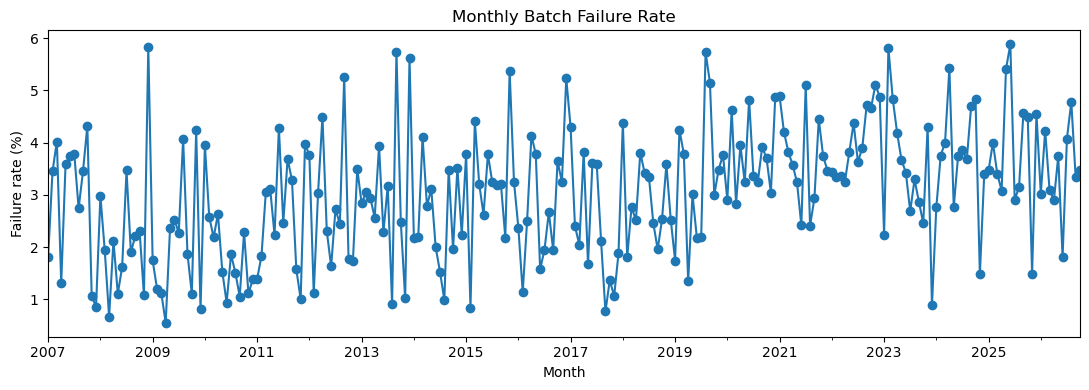

In [848]:

# Simple monthly quality monitoring: batch count and failure percentage.
quality_monthly = combined_data.copy()                                      # working copy
quality_monthly["production_start"] = pd.to_datetime(quality_monthly["production_start"], errors="coerce")  # make sure dates are datetime
quality_monthly = quality_monthly.dropna(subset=["production_start"])       # drop rows without a date
quality_monthly["failed"] = (quality_monthly["batch_outcome"] == "Failed").astype(int)  # 1 for a failed batch
quality_monthly = quality_monthly.set_index("production_start").resample("MS").agg(  # batches and failure rate per month
    batches=("batch_id", "count"), failure_rate=("failed", "mean"))
quality_monthly["failure_rate_pct"] = quality_monthly["failure_rate"] * 100  # failure rate in %
display(quality_monthly.tail(12).round(2))                                  # last 12 months
quality_monthly["failure_rate_pct"].plot(figsize=(11,4), marker="o")        # line chart of monthly failure rate
plt.title("Monthly Batch Failure Rate")                                     # chart title
plt.ylabel("Failure rate (%)"); plt.xlabel("Month"); plt.tight_layout(); plt.show()  # axis labels, then display


The monthly quality chart shows the observed percentage of batches marked Failed in each month. A spike should prompt review of batch mix, raw-material lots, equipment status, process conditions and changes in recording practice. It is a monitoring signal, not proof of a process cause or a formal statistical process-control limit.


### NLP on rejection reasons (descriptive only)

NLP is appropriate here for organizing the text of recorded rejection reasons. Because rejection reason is known after a batch fails, it is **not** included as a predictor in the batch pass/fail model. TF-IDF below identifies informative words/phrases in the failed-batch text, but the text is short and mostly categorical, so the frequency/Pareto chart remains the primary interpretable result.

,mean_tfidf
specification,0.177572
assay,0.174298
assay specification,0.174298
failure,0.148452
dissolution,0.114704
dissolution failure,0.114704
limit,0.108235
microbial limit,0.058120
limit failure,0.058120
microbial,0.058120


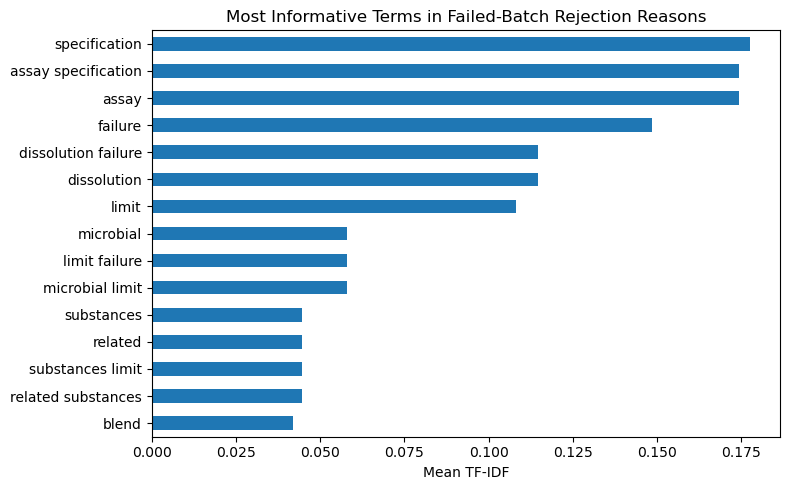

In [851]:

# NLP summary of rejection reasons using TF-IDF; reasons are descriptive, not predictors.
failed_text = combined_data.loc[                                            # rejection reasons of failed batches
    combined_data["batch_outcome"] == "Failed", "rejection_reason"
].dropna().astype(str)
failed_text = failed_text[failed_text.str.strip().ne("")]                   # drop empty reasons
if len(failed_text) >= 3:                                                   # need at least 3 reasons
    from sklearn.feature_extraction.text import TfidfVectorizer             # text -> word weights
    tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1,2), max_features=30)  # words and word pairs, top 30 terms
    matrix = tfidf.fit_transform(failed_text)                               # word-weight matrix
    terms = pd.Series(np.asarray(matrix.mean(axis=0)).ravel(),              # average weight of each term, top 15
                      index=tfidf.get_feature_names_out()).sort_values(ascending=False).head(15)
    display(terms.to_frame("mean_tfidf"))                                   # show the terms
    terms.sort_values().plot(kind="barh", figsize=(8,5))                    # bar chart of the terms
    plt.title("Most Informative Terms in Failed-Batch Rejection Reasons")   # chart title
    plt.xlabel("Mean TF-IDF"); plt.tight_layout(); plt.show()               # x-axis label, then display
else:                                                                       # otherwise
    print("Not enough non-empty rejection reasons for TF-IDF.")             # explain why it is skipped


### Interpreting the NLP output

TF-IDF values indicate which words or two-word phrases are relatively informative across the failed-batch rejection descriptions. The highest terms help organize recurring themes for manual review. They are not probabilities, severity scores or causal explanations. Validate the themes with QA and standardize rejection-reason coding for stronger future analysis.


# 19. Equipment and maintenance screening

The maintenance table contains maintenance status, equipment age and days since maintenance, but not failure-event dates, repair duration, downtime hours, planned/corrective maintenance type or installation dates. MTBF, MTTR, availability and true failure-within-horizon prediction therefore **cannot** be calculated honestly. Section 10 predicted the *recorded status*; the cell below ranks assets by current urgency.

In [854]:

# Asset-level screening using observed status and age; this is a priority list, not failure probability.
asset_cols = [c for c in ["equipment_id", "maintenance_status", "equipment_age_days",  # equipment columns that exist
                          "maintenance_days_ago"] if c in combined_data.columns]
asset_view = combined_data[asset_cols].drop_duplicates().copy()             # one row per distinct equipment record
if "maintenance_status" in asset_view:                                      # only if status is available
    priority = {"Critical": 3, "Due Soon": 2, "Current": 1}                 # status -> priority score
    asset_view["priority_score"] = asset_view["maintenance_status"].map(priority).fillna(0)  # add the priority score
    sort_cols = ["priority_score"] + (["maintenance_days_ago"] if "maintenance_days_ago" in asset_view else [])  # sort by priority, then days since service
    asset_view = asset_view.sort_values(sort_cols, ascending=False)         # highest priority first
    display(asset_view.head(15))                                            # top 15 records
    print("Priority score is an ordinal screening aid: Critical=3, Due Soon=2, Current=1.")  # how to read the score
else:                                                                       # otherwise
    print("Maintenance status is not available for equipment screening.")   # explain why it is skipped


,equipment_id,maintenance_status,equipment_age_days,maintenance_days_ago,priority_score
38027,LAL/LIQ/002,Critical,4697,185,3
37996,LAL/LIQ/002,Critical,4694,182,3
37986,LAL/LIQ/002,Critical,4693,181,3
37181,LAL/CRM/001,Critical,5357,180,3
37975,LAL/LIQ/002,Critical,4692,180,3
56020,LAL/TAB/011,Critical,5360,180,3
37170,LAL/CRM/001,Critical,5356,179,3
37962,LAL/LIQ/002,Critical,4691,179,3
37159,LAL/CRM/001,Critical,5355,178,3
37949,LAL/LIQ/002,Critical,4690,178,3


Priority score is an ordinal screening aid: Critical=3, Due Soon=2, Current=1.


### Interpreting the asset list

The list ranks equipment records by status (Critical = 3, Due Soon = 2, Current = 1) and then by days since maintenance. It is a **prioritisation aid**, not a prediction of breakdown. Combined with Problem 3, it shows that status follows a service cycle of roughly 13 weeks, so overdue (Critical) equipment is largely a scheduling matter that planners can prevent by servicing earlier.

The supplied records do not include failure dates or downtime hours, so MTBF, MTTR and equipment availability cannot be calculated.

# 20. Final validation, limitations and recommended next steps

### What this notebook delivers
- Data cleaning, EDA (each chart explained with the actual values) and feature engineering, unchanged from Sections 1 to 6.
- Nine modelling problems and an inventory policy (table in Section 7), each with a baseline, suitable metrics and a stated model choice. Problems 1, 2, 3 and 5 reuse the Section 6 train/test split and features.
- Models: Logistic and Linear Regression, Random Forest, Gradient Boosting, Croston-SBA, ANN, GRU, Z-score, PCA, KNN distance, K-Means and NLP (TF-IDF + K-Means), at most four per problem.
- Quality monitoring, rejection-reason NLP and equipment screening.

### Critical limitations
1. Sales and inventory cover laboratory-supply products (`LAB_PROD_` IDs); production covers LAL medicine batches. No product key links batches to sales, so the four datasets are compared by month only (Section 5.7).
2. There are no expiry dates, opening stock balances, purchase-order dates or supplier lead times, audit/CAPA records, equipment failure events or downtime durations. Expiry risk, the business back-test, MTBF/MTTR and failure prediction remain unvalidated; reorder points use an assumed 14-day lead time.
3. Batch failures are rare (3.1%). The failure model is only a weak screening aid, because the outcome is decided by laboratory results that are deliberately excluded from the predictors.
4. Problems 1, 2, 3 and 5 use the random Section 6 split; the scores may be optimistic for future periods. Problem 4 uses a time-ordered split. Before deployment, repeat every problem with a time-based hold-out.
5. The maintenance status is a rule on days since last service, so the classifier learns the service cycle; it is not a failure probability.
6. Stock is rebuilt from movements assuming zero opening stock in January 2014, which overstates early stock-outs. Weekly demand is intermittent, so product-level forecast errors are high even though the forecast beats the baseline. No financial savings are claimed.
7. Neural-network results change slightly between machines and TensorFlow versions; the printed epochs and tables from your own run are the figures to report.

### Data required to complete the remaining objectives
- Opening stock balances, purchase-order dates and quantities (for lead time and fill rate), transfers, write-offs and reorder levels.
- Batch manufacture and expiry dates and batch-to-sale traceability.
- Supplier IDs, lead times and delivered quantities.
- Audit scores, deviation events and severity, CAPA dates and temperature logs with product-specific limits.
- Asset failure dates and types, maintenance type, repair start and end, downtime hours, installation date and asset criticality.

### Governance
Use the notebook as decision support only. Have pharmacy, procurement, QA and engineering review thresholds and actions. Do not include patient-level clinical data, and comply with applicable data-protection requirements, including the Kenya Data Protection Act, 2019.

# 21. Executive summary

**Purpose:** use LAL's four datasets (production, maintenance, sales and inventory) to find where batch quality is lost, which equipment needs attention, and how demand and stock should be managed.

| | Bottom line |
|---|---|
| ✅ | **Quality is high:** 96.9% of 60,000 batches pass. |
| 🎯 | **Losses are concentrated:** three causes make up 70% of failures, and Oral Solids make up 74%. |
| 🔧 | **Overdue maintenance doubles the risk:** batches on Critical equipment fail at 6.9%, against 3.1%. |
| 📦 | **Too much stock, bought without regard to sales:** receipts are about twice sales; about KES 64 billion is held, mostly Equipment. |
| 📊 | **Demand and stock-outs can be planned:** the weekly forecast beats last year's pattern by about 20%, and a watch-list catches 80% of stock-outs. |
| ⚠️ | **Failure prediction is weak:** laboratory release testing stays essential. |

## 21.1 Key figures

In [859]:
fail = combined_data["batch_outcome"].eq("Failed")                          # True for failed batches
receipts = moves[moves["quantity_change"] > 0]                              # goods-received movements
rate_by_status = fail.groupby(combined_data["maintenance_status"]).mean() * 100  # failure rate per equipment status
key_figures = pd.DataFrame([
    ["Batches made / failed", f"{len(combined_data):,} / {fail.sum():,} ({fail.mean():.1%})"],
    ["Failure rate: Critical vs Current equipment", f"{rate_by_status['Critical']:.1f}% vs {rate_by_status['Current']:.1f}%"],
    ["Top 3 failure causes, share of failures", f"{pareto['Share (%)'].head(3).sum():.0f}%"],
    ["Delivered / cancelled orders", f"{len(valid_sales):,} / {sales_data['is_cancelled'].sum():,}"],
    ["Net sales 2014-2025 (KES billion)", f"{valid_sales['net_amount_excl_vat_kes'].sum() / 1e9:.1f}"],
    ["Units received / sold", f"{receipts['quantity_change'].sum():,} / {valid_sales['quantity'].sum():,}"],
    ["Unpaid balances (KES million)", f"{sales_data['balance_due_kes'].sum() / 1e6:,.0f}"],
    ["Items to reorder now / overstocked", f"{(policy['status'] == 'Reorder now').sum()} / {(policy['status'] == 'Overstock').sum()}"],
], columns=["Indicator", "Value"])                                          # one row per headline number
display(key_figures)                                                        # show the table

,Indicator,Value
0,Batches made / failed,"60,000 / 1,875 (3.1%)"
1,Failure rate: Critical vs Current equipment,6.9% vs 3.1%
2,"Top 3 failure causes, share of failures",70%
3,Delivered / cancelled orders,"143,955 / 6,045"
4,Net sales 2014-2025 (KES billion),11.7
5,Units received / sold,"4,127,550 / 2,066,241"
6,Unpaid balances (KES million),"1,804"
7,Items to reorder now / overstocked,128 / 1033


### Explanation
- **Quality:** 1,875 of 60,000 batches failed (**3.1%**). On overdue (Critical) equipment the rate is **6.9%**, against **3.1%** on Current equipment. Three causes (assay, dissolution, weight variation) make up **70%** of failures.
- **Sales:** **143,955** delivered orders worth **KES 11.7 billion**; 6,045 (4.0%) were cancelled. **KES 1,804 million** is still unpaid, all on credit accounts.
- **Stock:** **4.13 million units received against 2.07 million sold**. **128 items** need reordering now while **1,033** are overstocked.

## 21.2 Model results

In [862]:
problems = [("1. Batch failure", classification_results, best1, "Baseline (always Passed)", "PR-AUC", True),
            ("2. Batch yield", yield_results, best2, "Baseline (mean yield)", "MAE", False),
            ("3. Maintenance status", maintenance_results, best3, "Baseline (always Current)", "Macro F1", True),
            ("4. Monthly quality trend", sequence_results, best4, "Baseline (seasonal-naive)", "WAPE (%)", False),
            ("5. Abnormal conditions", anomaly_results, best5, "Baseline (random score)", "PR-AUC", True),
            ("7. Weekly demand", demand_results, best7, "Baseline (seasonal-naive)", "WAPE (%)", False),
            ("8. Stock-out risk", stockout_results, best8, "Baseline (always in stock)", "PR-AUC", True)]
rows = []                                                                   # one row per problem
for name, results, best, base, metric, higher in problems:
    score = results.set_index("Model")[metric]                              # every model's score
    gain = 100 * (score[best] / score[base] - 1) if higher else 100 * (1 - score[best] / score[base])  # % better than baseline
    rows.append([name, best, metric, score[best], score[base], gain])
rows.append(["6. Failure causes", f"K-Means (k={best_k})", "Silhouette", nlp_results["Silhouette"].max(), None, None])
rows.append(["9. Product groups", best9["Model"], "Silhouette", best9["Silhouette"], None, None])
scorecard = pd.DataFrame(rows, columns=["Problem", "Chosen model", "Metric", "Score", "Baseline", "Gain over baseline (%)"])
display(scorecard.round(3))                                                 # show the table

,Problem,Chosen model,Metric,Score,Baseline,Gain over baseline (%)
0,1. Batch failure,Logistic Regression,PR-AUC,0.047,0.031,50.045
1,2. Batch yield,Random Forest,MAE,0.858,1.102,22.103
2,3. Maintenance status,Random Forest,Macro F1,0.557,0.316,76.177
3,4. Monthly quality trend,Linear Regression,WAPE (%),7.003,8.822,20.617
4,5. Abnormal conditions,Z-score rule,PR-AUC,0.036,0.033,9.895
5,7. Weekly demand,Croston-SBA,WAPE (%),115.012,143.221,19.696
6,8. Stock-out risk,Gradient Boosting,PR-AUC,0.278,0.001,20479.736
7,6. Failure causes,K-Means (k=6),Silhouette,0.788,NaN,NaN
8,9. Product groups,K-Means (k=2),Silhouette,0.471,NaN,NaN


### Explanation
| Problem | Chosen model | Result | Use |
|---|---|---|---|
| 3. Maintenance status | Random Forest | macro F1 0.557 vs 0.316 (+76%) | 🟢 flags 69% of overdue equipment |
| 6. Failure causes | K-Means (k = 6) | silhouette 0.788 | 🟢 clear cause groups for CAPA |
| 8. Stock-out risk | Gradient Boosting | PR-AUC 0.278 vs 0.001 (206× random) | 🟢 weekly watch-list catches 80% of stock-outs |
| 7. Weekly demand | Croston-SBA | 19.7% better than last year's pattern, bias −5.9% | 🟠 meets the 15% target |
| 2. Batch yield | Random Forest | error ±0.86 points (22% better) | 🟠 planning |
| 4. Monthly quality trend | Linear Regression | 20.6% better than baseline | 🟠 monthly QA check |
| 9. Product groups | K-Means (k = 2) | silhouette 0.471 | 🟠 two stock policies |
| 1. Batch failure | Logistic Regression | PR-AUC 0.047 vs 0.031 | 🔴 weak: only 4% of alerts are real |
| 5. Abnormal conditions | Z-score rule | PR-AUC 0.036 vs 0.033 | 🔴 close to random |

The neural networks (Problems 1–4) did not beat the simpler models, so the simpler, easier-to-explain models are recommended.

## 21.3 Where to act

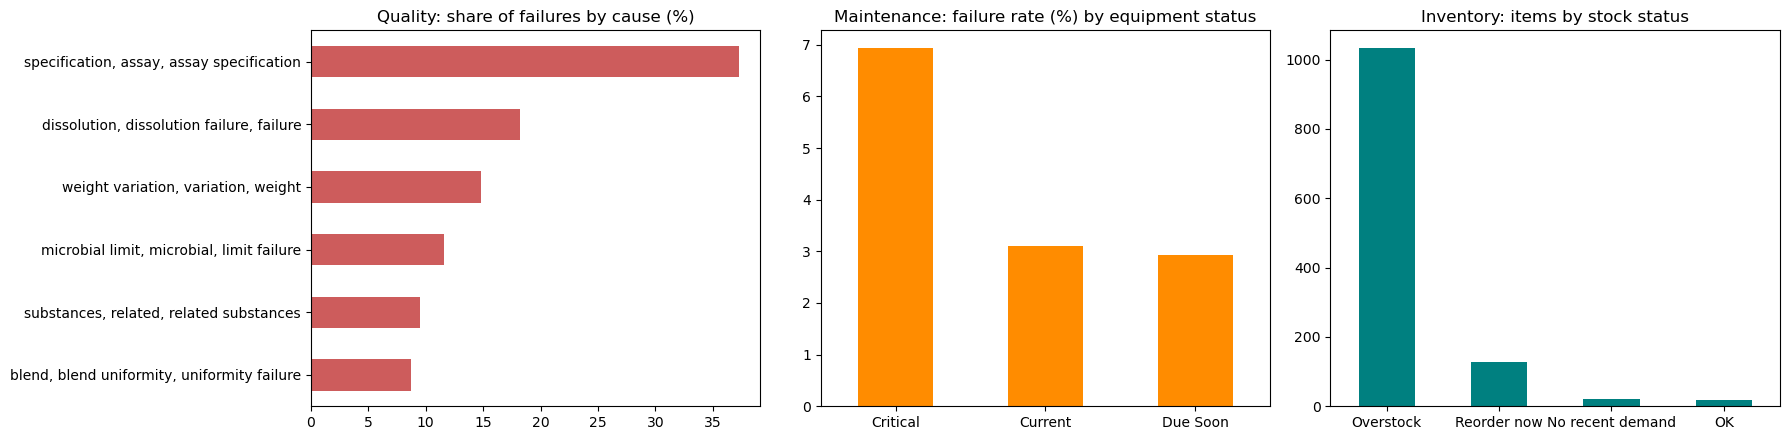

In [865]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))                             # one chart per module
pareto["Share (%)"].sort_values().plot.barh(ax=ax[0], color="indianred")   # quality: causes of failure
ax[0].set_title("Quality: share of failures by cause (%)")
rate_by_status.plot.bar(ax=ax[1], color="darkorange", rot=0)               # maintenance: failure rate by status
ax[1].set_title("Maintenance: failure rate (%) by equipment status")
policy["status"].value_counts().plot.bar(ax=ax[2], color="teal", rot=0)    # inventory: items by stock status
ax[2].set_title("Inventory: items by stock status")
for a in ax:                                                                # remove axis labels
    a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout()                                                          # avoid overlapping labels
plt.show()                                                                  # display the charts

### Explanation
- **Quality:** the largest cause groups are **assay specification (37%)**, **dissolution (18%)** and **weight variation (15%)**, 70% together. Fixing these three gives the largest quality gain.
- **Maintenance:** the failure rate is flat for Current and Due Soon equipment (about 3%) and jumps to **6.9%** once equipment is overdue. Servicing on time is the lever.
- **Inventory:** most items are **Overstock (1,033)**, a smaller group needs **reordering now (128)**, and only 19 are at the right level.

## 21.4 Recommendations

In [868]:
actions = pd.DataFrame([
    ["High", "QA / CAPA", "CAPA on assay, dissolution and weight-variation failures, starting with Oral Solids", "70% of failures; Oral Solids = 74%"],
    ["High", "Engineering", "Service equipment before it becomes Critical; fixed schedule for the 5 most-overdue machines", "6.9% vs 3.1% failure rate"],
    ["High", "Procurement", "Buy to the reorder-point policy; stop receipts for overstocked items, especially Equipment", "Receipts about 2x sales; KES 64 bn stock"],
    ["Medium", "Branch stores", "Weekly reorder list and stock-out watch-list", "Catches 80% of stock-outs"],
    ["Medium", "Planning", "Plan volumes with the Croston-SBA weekly forecast", "20% better than last year's pattern"],
    ["Medium", "Finance", "Review credit-account terms and collections", "KES 1.8 bn unpaid, all on credit accounts"],
    ["Low", "QA", "Use the failure ranking only for extra in-process checks", "Failure model is weak"],
], columns=["Priority", "Owner", "Action", "Evidence"])                     # one row per recommendation
display(actions)                                                            # show the table

,Priority,Owner,Action,Evidence
0,High,QA / CAPA,"CAPA on assay, dissolution and weight-variatio...",70% of failures; Oral Solids = 74%
1,High,Engineering,Service equipment before it becomes Critical; ...,6.9% vs 3.1% failure rate
2,High,Procurement,Buy to the reorder-point policy; stop receipts...,Receipts about 2x sales; KES 64 bn stock
3,Medium,Branch stores,Weekly reorder list and stock-out watch-list,Catches 80% of stock-outs
4,Medium,Planning,Plan volumes with the Croston-SBA weekly forecast,20% better than last year's pattern
5,Medium,Finance,Review credit-account terms and collections,"KES 1.8 bn unpaid, all on credit accounts"
6,Low,QA,Use the failure ranking only for extra in-proc...,Failure model is weak


### Explanation
- **High priority:** the three actions with the clearest payoff. CAPA on three causes addresses 70% of failures, on-time servicing removes the doubled risk on overdue equipment, and buying to the reorder point stops the stock build-up.
- **Medium:** weekly routines for stores and planners that use the Problem 7 and 8 models, plus a finance review of credit accounts.
- **Low:** the failure ranking is only a targeting aid.
- **Limits:** Problems 1, 2, 3 and 5 use a random split, so their scores may be optimistic for future months. Stock values rest on an assumed zero opening stock in 2014 and should be confirmed. No financial savings are claimed.